In [1]:
import configparser
import os

from kneed import KneeLocator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [3]:
dataMutations_all = pd.read_csv(data['all_all___mutations'], sep='\t', comment='#', engine='python')
dataMutations_Giannakis = pd.read_csv(data['Giannakis_all___mutations'], sep='\t', comment='#', engine='python')
dataMutations_Seshagiri = pd.read_csv(data['Seshagiri_all___mutations'], sep='\t', comment='#', engine='python')
dataMutations_TCGA = pd.read_csv(data['TCGA_all___mutations'], sep='\t', comment='#', engine='python')

In [4]:
dataClinicalSample_all = pd.read_csv(data['all_all___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample_Giannakis = pd.read_csv(data['Giannakis_all___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample_Seshagiri = pd.read_csv(data['Seshagiri_all___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample_TCGA = pd.read_csv(data['TCGA_all___samples'], sep='\t', comment='#', engine='python')

In [5]:
numMutatedBases_perPatient_all = pd.merge(dataMutations_all, dataClinicalSample_all, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID', how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
geneLength_perGene_all = dataMutations_all[['Hugo_Symbol', 'Gene_Length']].groupby('Hugo_Symbol').max().reset_index()
totalGeneLength_all = geneLength_perGene_all['Gene_Length'].sum()

numMutatedBases_perPatient_Giannakis = pd.merge(dataMutations_Giannakis, dataClinicalSample_Giannakis, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID',  how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
geneLength_perGene_Giannakis = dataMutations_Giannakis[['Hugo_Symbol', 'Gene_Length']].groupby('Hugo_Symbol').max().reset_index()
totalGeneLength_Giannakis = geneLength_perGene_Giannakis['Gene_Length'].sum()

numMutatedBases_perPatient_Seshagiri = pd.merge(dataMutations_Seshagiri, dataClinicalSample_Seshagiri, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID', how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
geneLength_perGene_Seshagiri = dataMutations_Seshagiri[['Hugo_Symbol', 'Gene_Length']].groupby('Hugo_Symbol').max().reset_index()
totalGeneLength_Seshagiri = geneLength_perGene_Seshagiri['Gene_Length'].sum()

numMutatedBases_perPatient_TCGA = pd.merge(dataMutations_TCGA, dataClinicalSample_TCGA, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID', how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
geneLength_perGene_TCGA = dataMutations_TCGA[['Hugo_Symbol', 'Gene_Length']].groupby('Hugo_Symbol').max().reset_index()
totalGeneLength_TCGA = geneLength_perGene_TCGA['Gene_Length'].sum()

In [6]:
print(len(geneLength_perGene_all))
print(len(geneLength_perGene_Giannakis))
print(len(geneLength_perGene_Seshagiri))
print(len(geneLength_perGene_TCGA))

19010
18188
12798
18582


In [7]:
print(totalGeneLength_all)
print(totalGeneLength_Giannakis)
print(totalGeneLength_Seshagiri)
print(totalGeneLength_TCGA)

1286749622
1257216806
1046254288
1279243864


In [8]:
## TODO: È giusto considerare solo la lunghezza dei geni presenti nel singolo database? o dovrei sempre considerarli tutti???

In [9]:
numMutatedBases_perPatient_all['Mutation_Rate'] = numMutatedBases_perPatient_all['Number_Mutated_Bases'] / totalGeneLength_all
numMutatedBases_perPatient_all['Mutation_Rate[µ]'] = numMutatedBases_perPatient_all['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_all = numMutatedBases_perPatient_all.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)

numMutatedBases_perPatient_Giannakis['Mutation_Rate'] = numMutatedBases_perPatient_Giannakis['Number_Mutated_Bases'] / totalGeneLength_Giannakis
numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] = numMutatedBases_perPatient_Giannakis['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_Giannakis = numMutatedBases_perPatient_Giannakis.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)

numMutatedBases_perPatient_Seshagiri['Mutation_Rate'] = numMutatedBases_perPatient_Seshagiri['Number_Mutated_Bases'] / totalGeneLength_Seshagiri
numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] = numMutatedBases_perPatient_Seshagiri['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_Seshagiri = numMutatedBases_perPatient_Seshagiri.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)

numMutatedBases_perPatient_TCGA['Mutation_Rate'] = numMutatedBases_perPatient_TCGA['Number_Mutated_Bases'] / totalGeneLength_TCGA
numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] = numMutatedBases_perPatient_TCGA['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_TCGA = numMutatedBases_perPatient_TCGA.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)

In [10]:
# number of patient with mut rate = 0
print('all: ' + str(np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] == 0)))
print('Giannakis: ' + str(np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] == 0)))
print('Seshagiri: ' + str(np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] == 0)))
print('TCGA: ' + str(np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] == 0)))

all: 68
Giannakis: 0
Seshagiri: 2
TCGA: 66


In [11]:
# function to align a dataframe with another one containing it
def align(df, df_all):
    aligned_df = pd.DataFrame(index=df_all.index)  # Create an empty dataframe with the same index as _all
    for col in df.columns:
        aligned_df[col] = None
    for row in df.iterrows():
        aligned_df.loc[df_all[df_all['PATIENT_ID'] == row[1]['PATIENT_ID']].index[0]] = row[1]
    return aligned_df

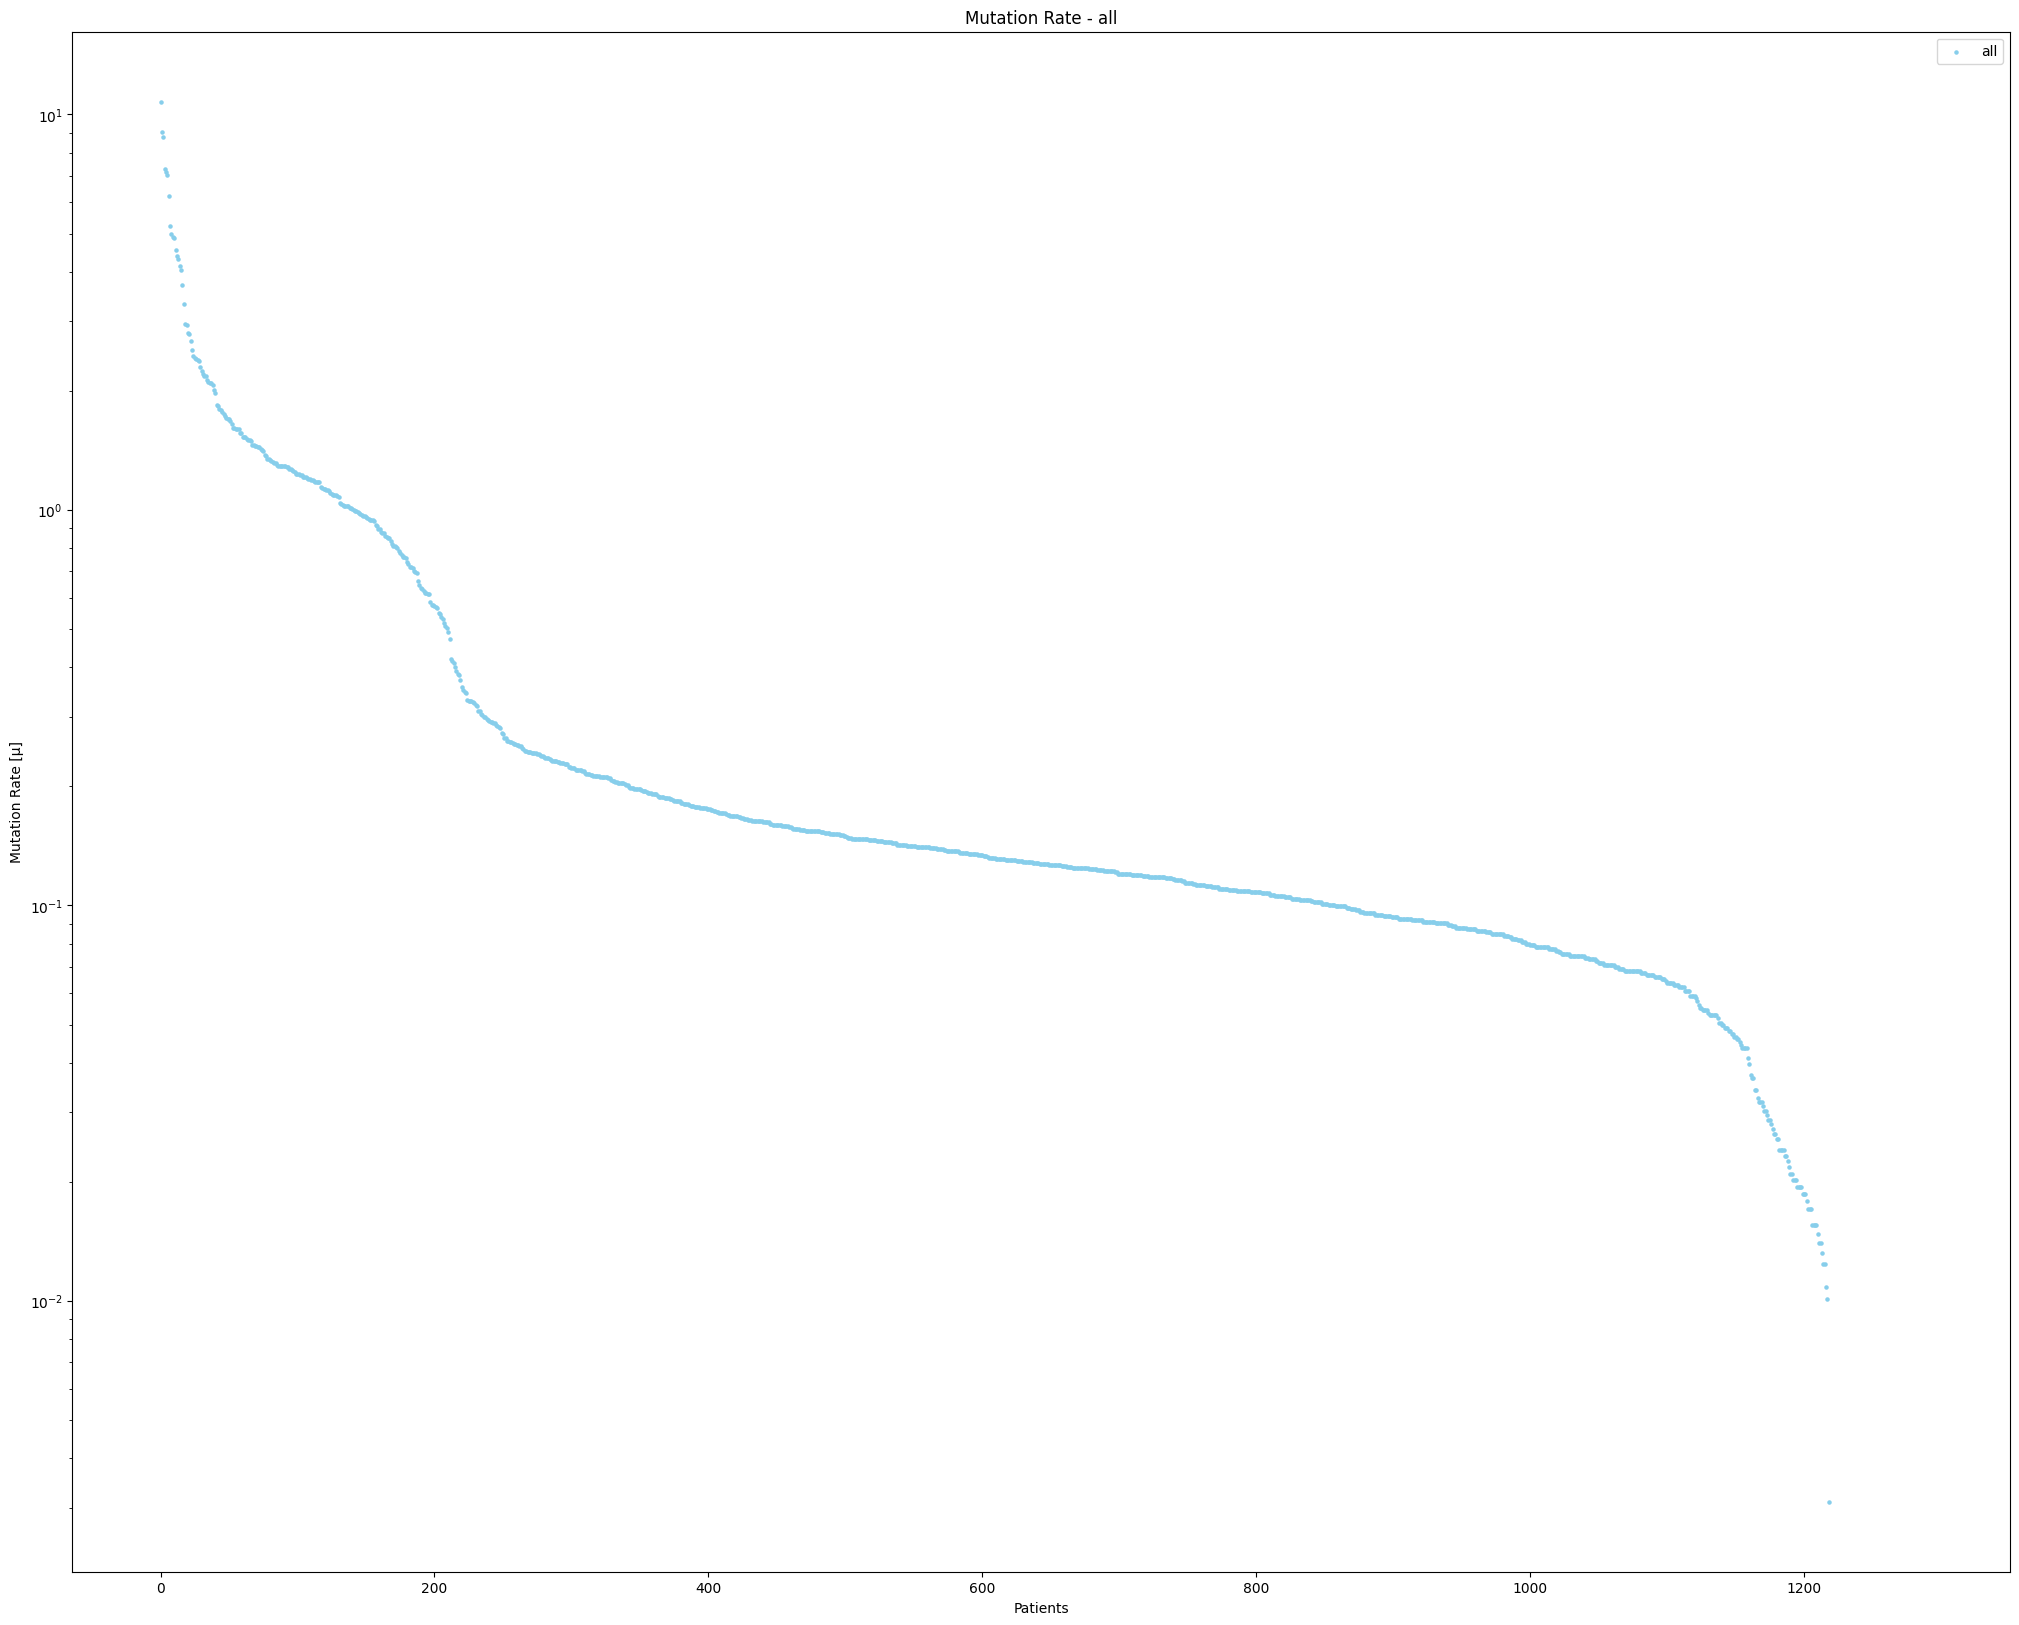

In [12]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all'])
plt.title('Mutation Rate - all')
plt.savefig(data['hypoHyper_analysis'] + 'all')
plt.show()

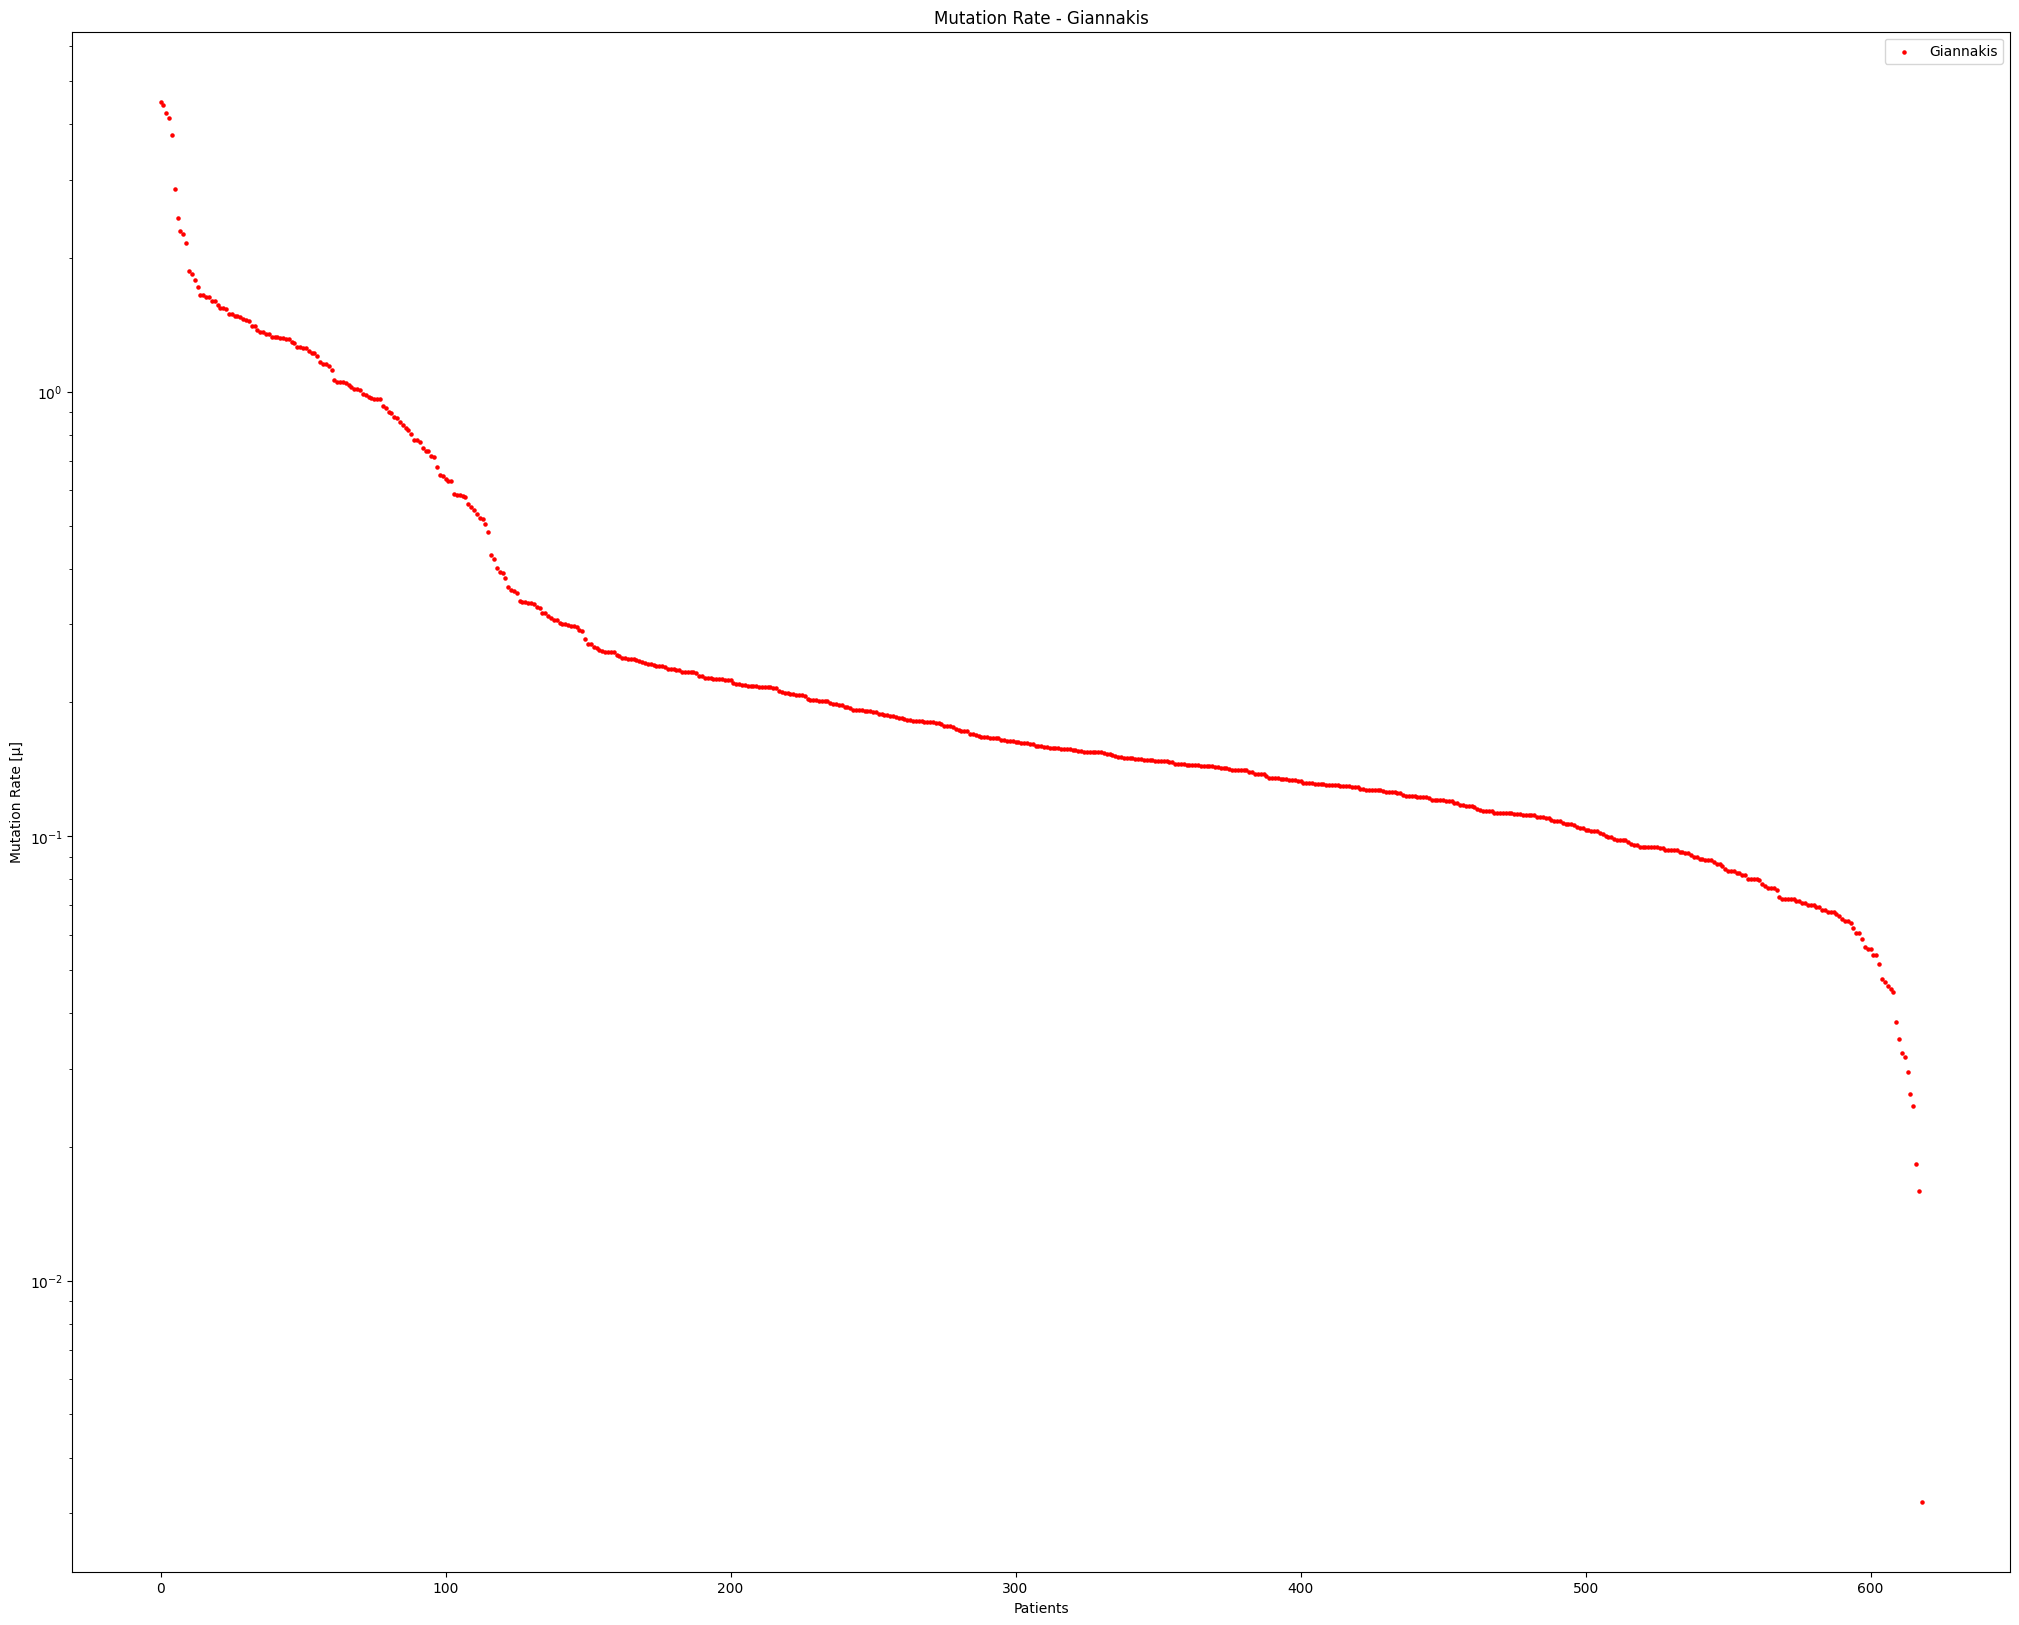

In [13]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis'])
plt.title('Mutation Rate - Giannakis')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis')
plt.show()

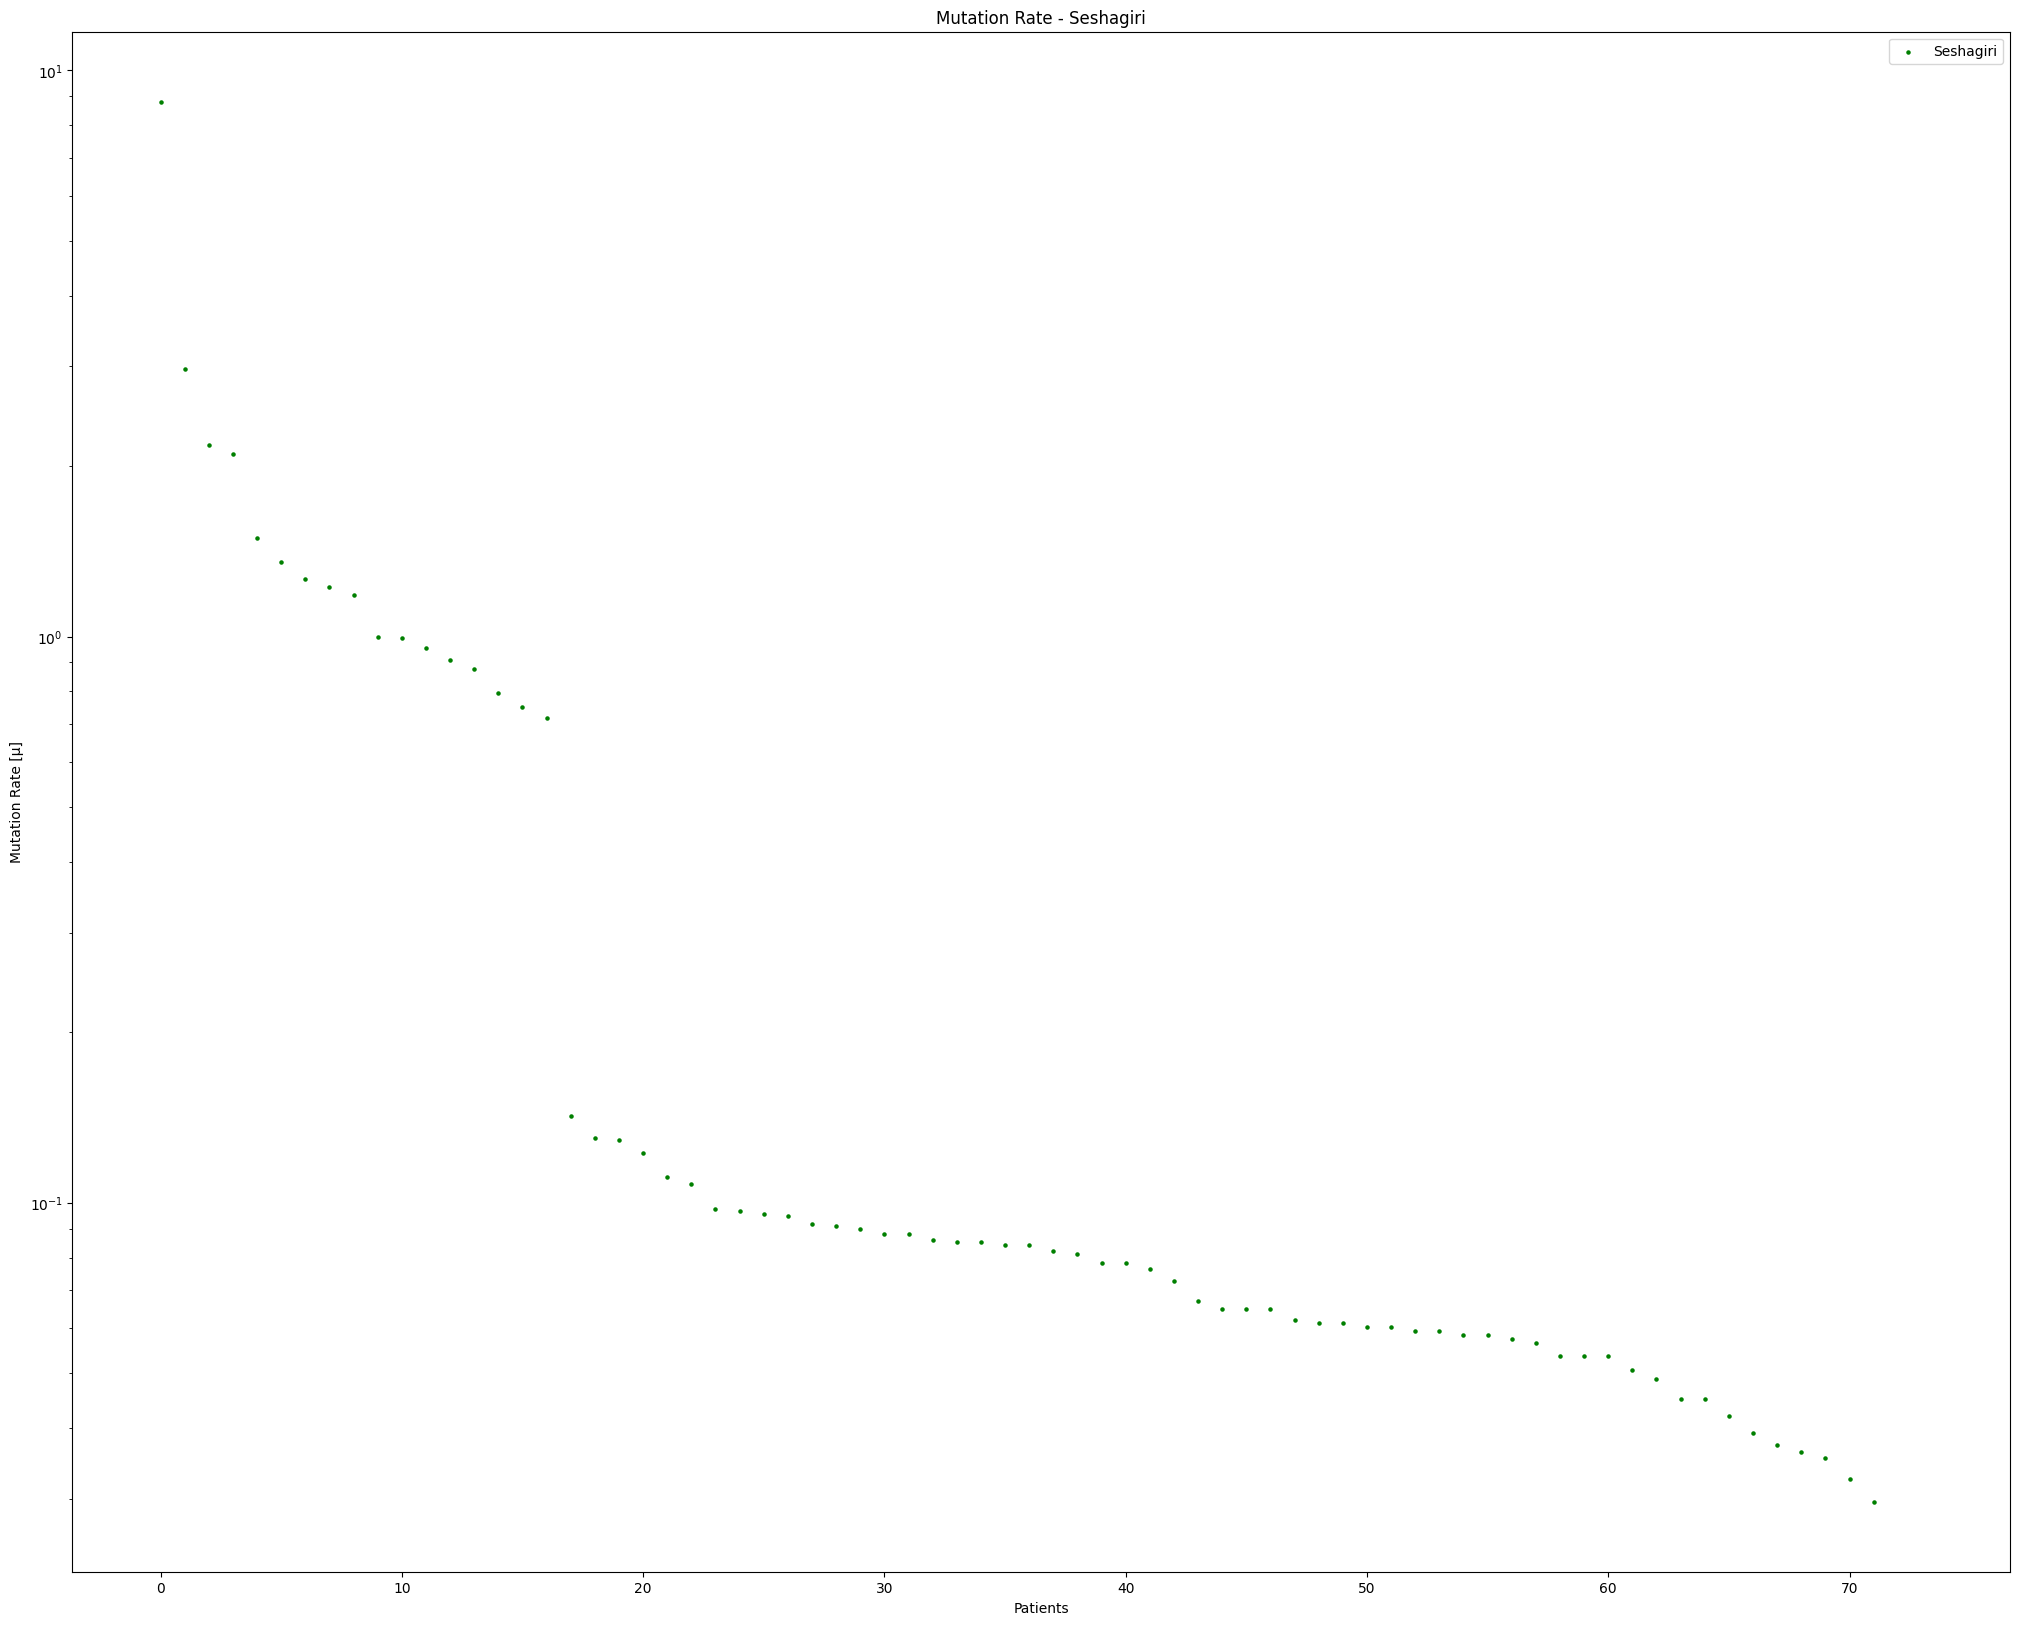

In [14]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Seshagiri'])
plt.title('Mutation Rate - Seshagiri')
plt.savefig(data['hypoHyper_analysis'] + 'Seshagiri')
plt.show()

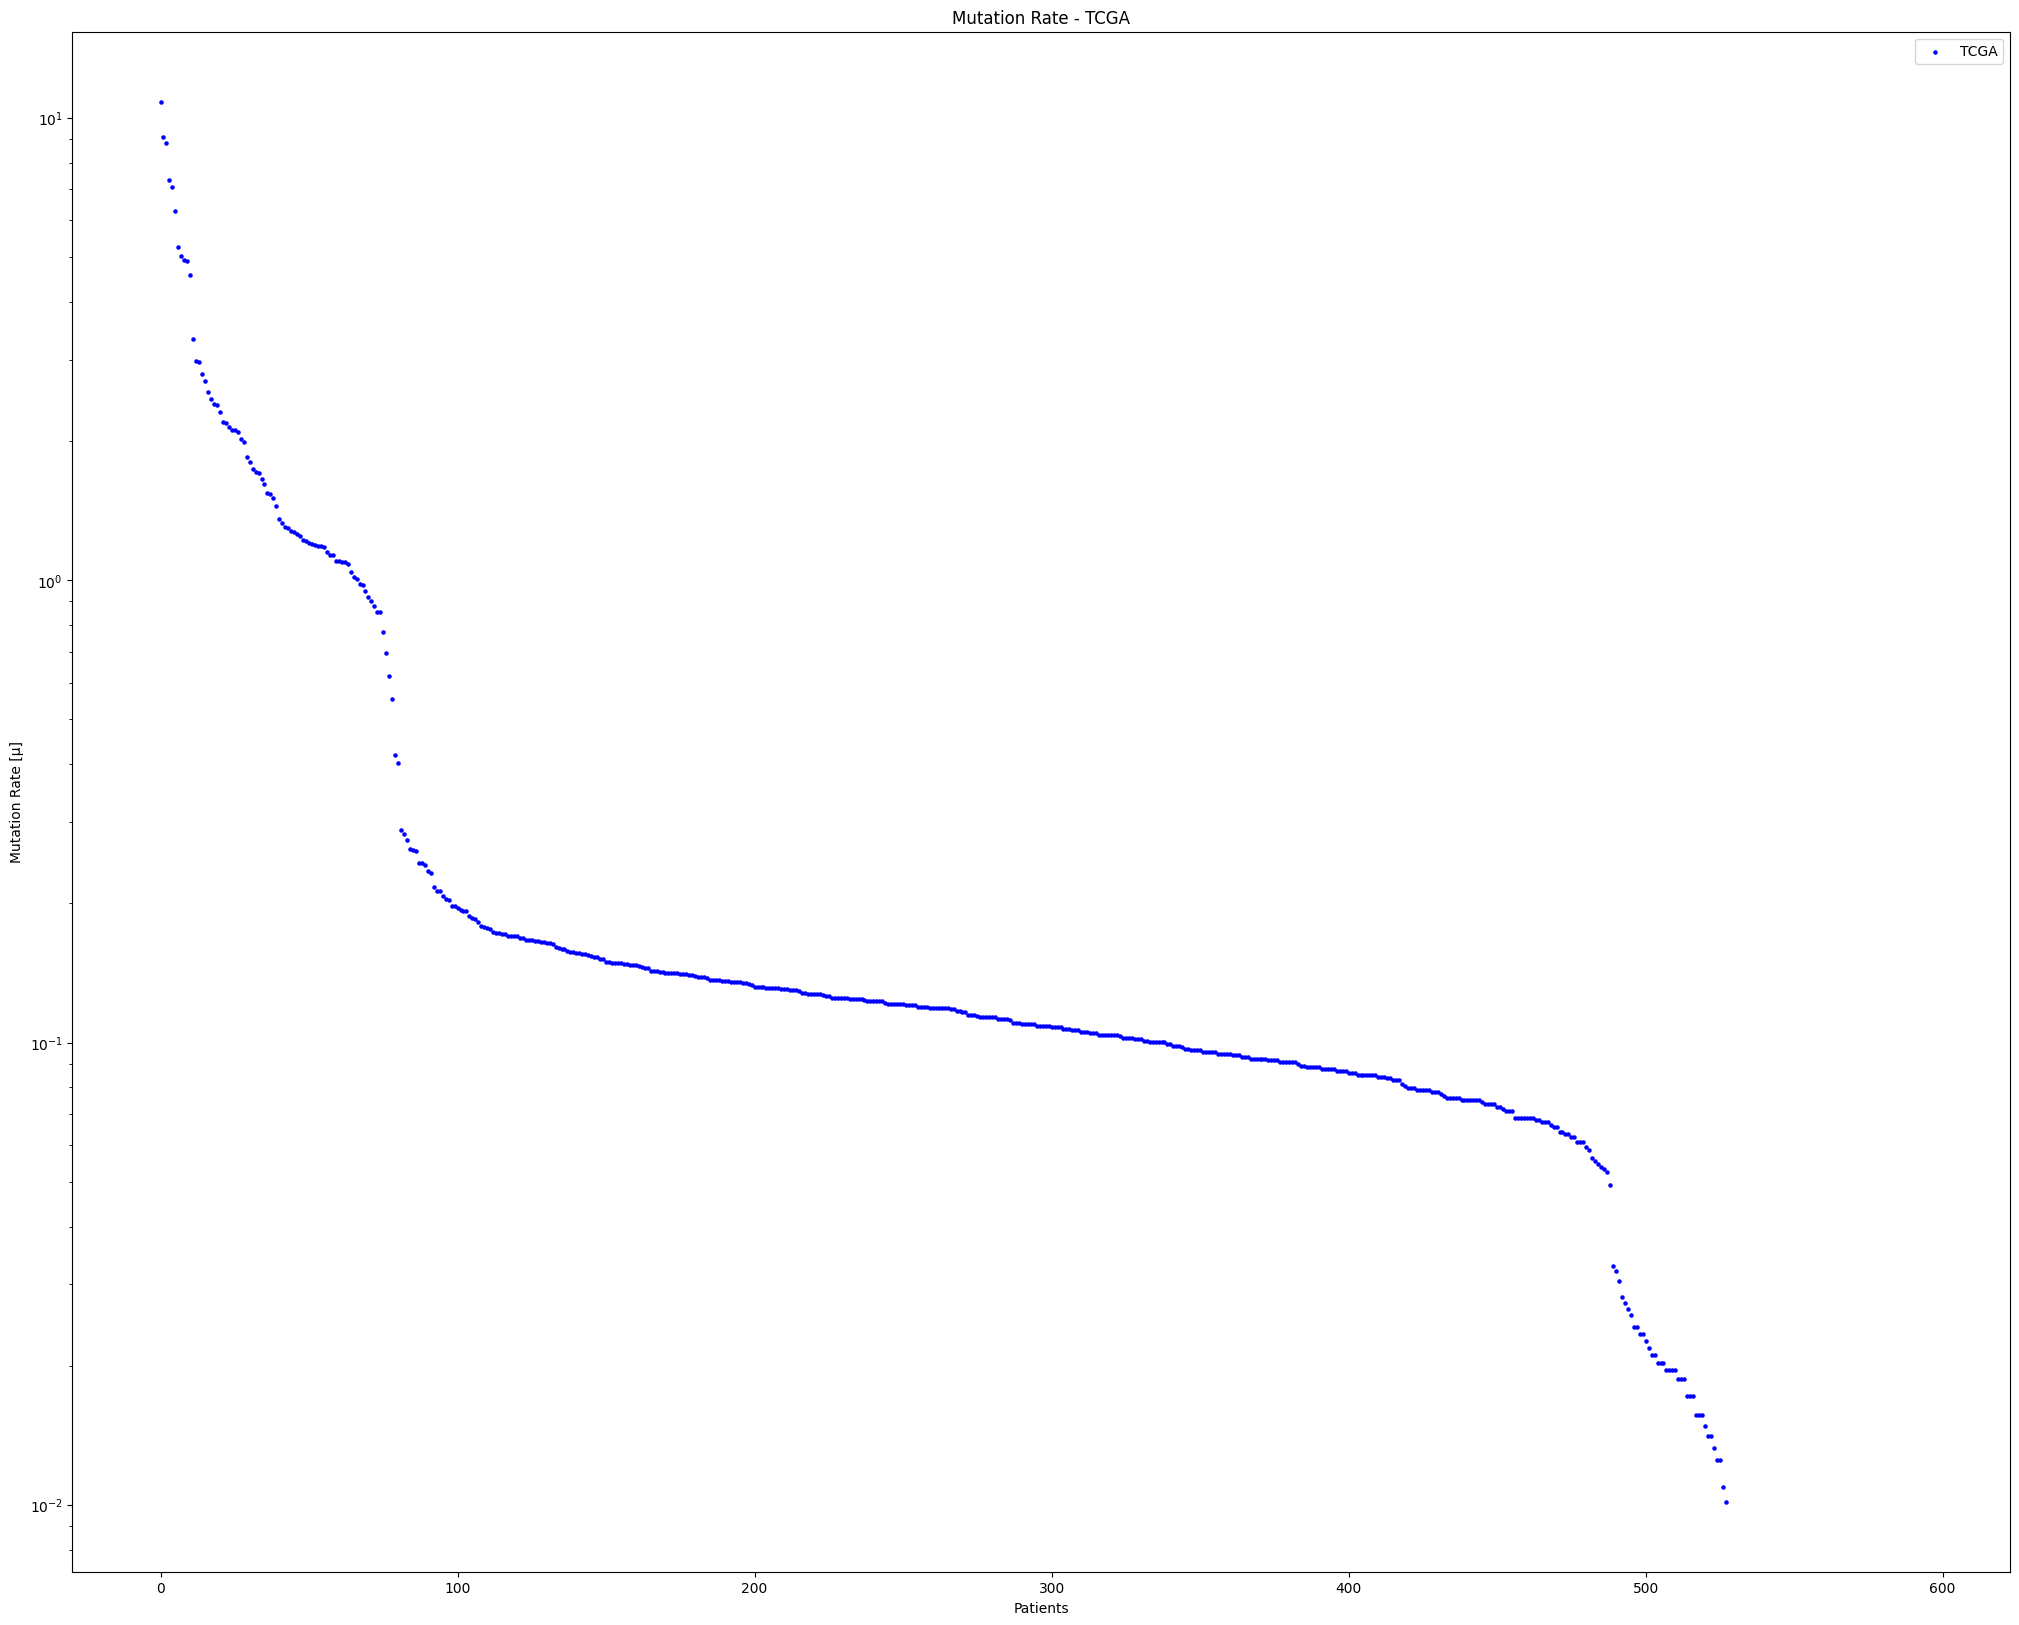

In [15]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['TCGA'])
plt.title('Mutation Rate - TCGA')
plt.savefig(data['hypoHyper_analysis'] + 'TCGA')
plt.show()

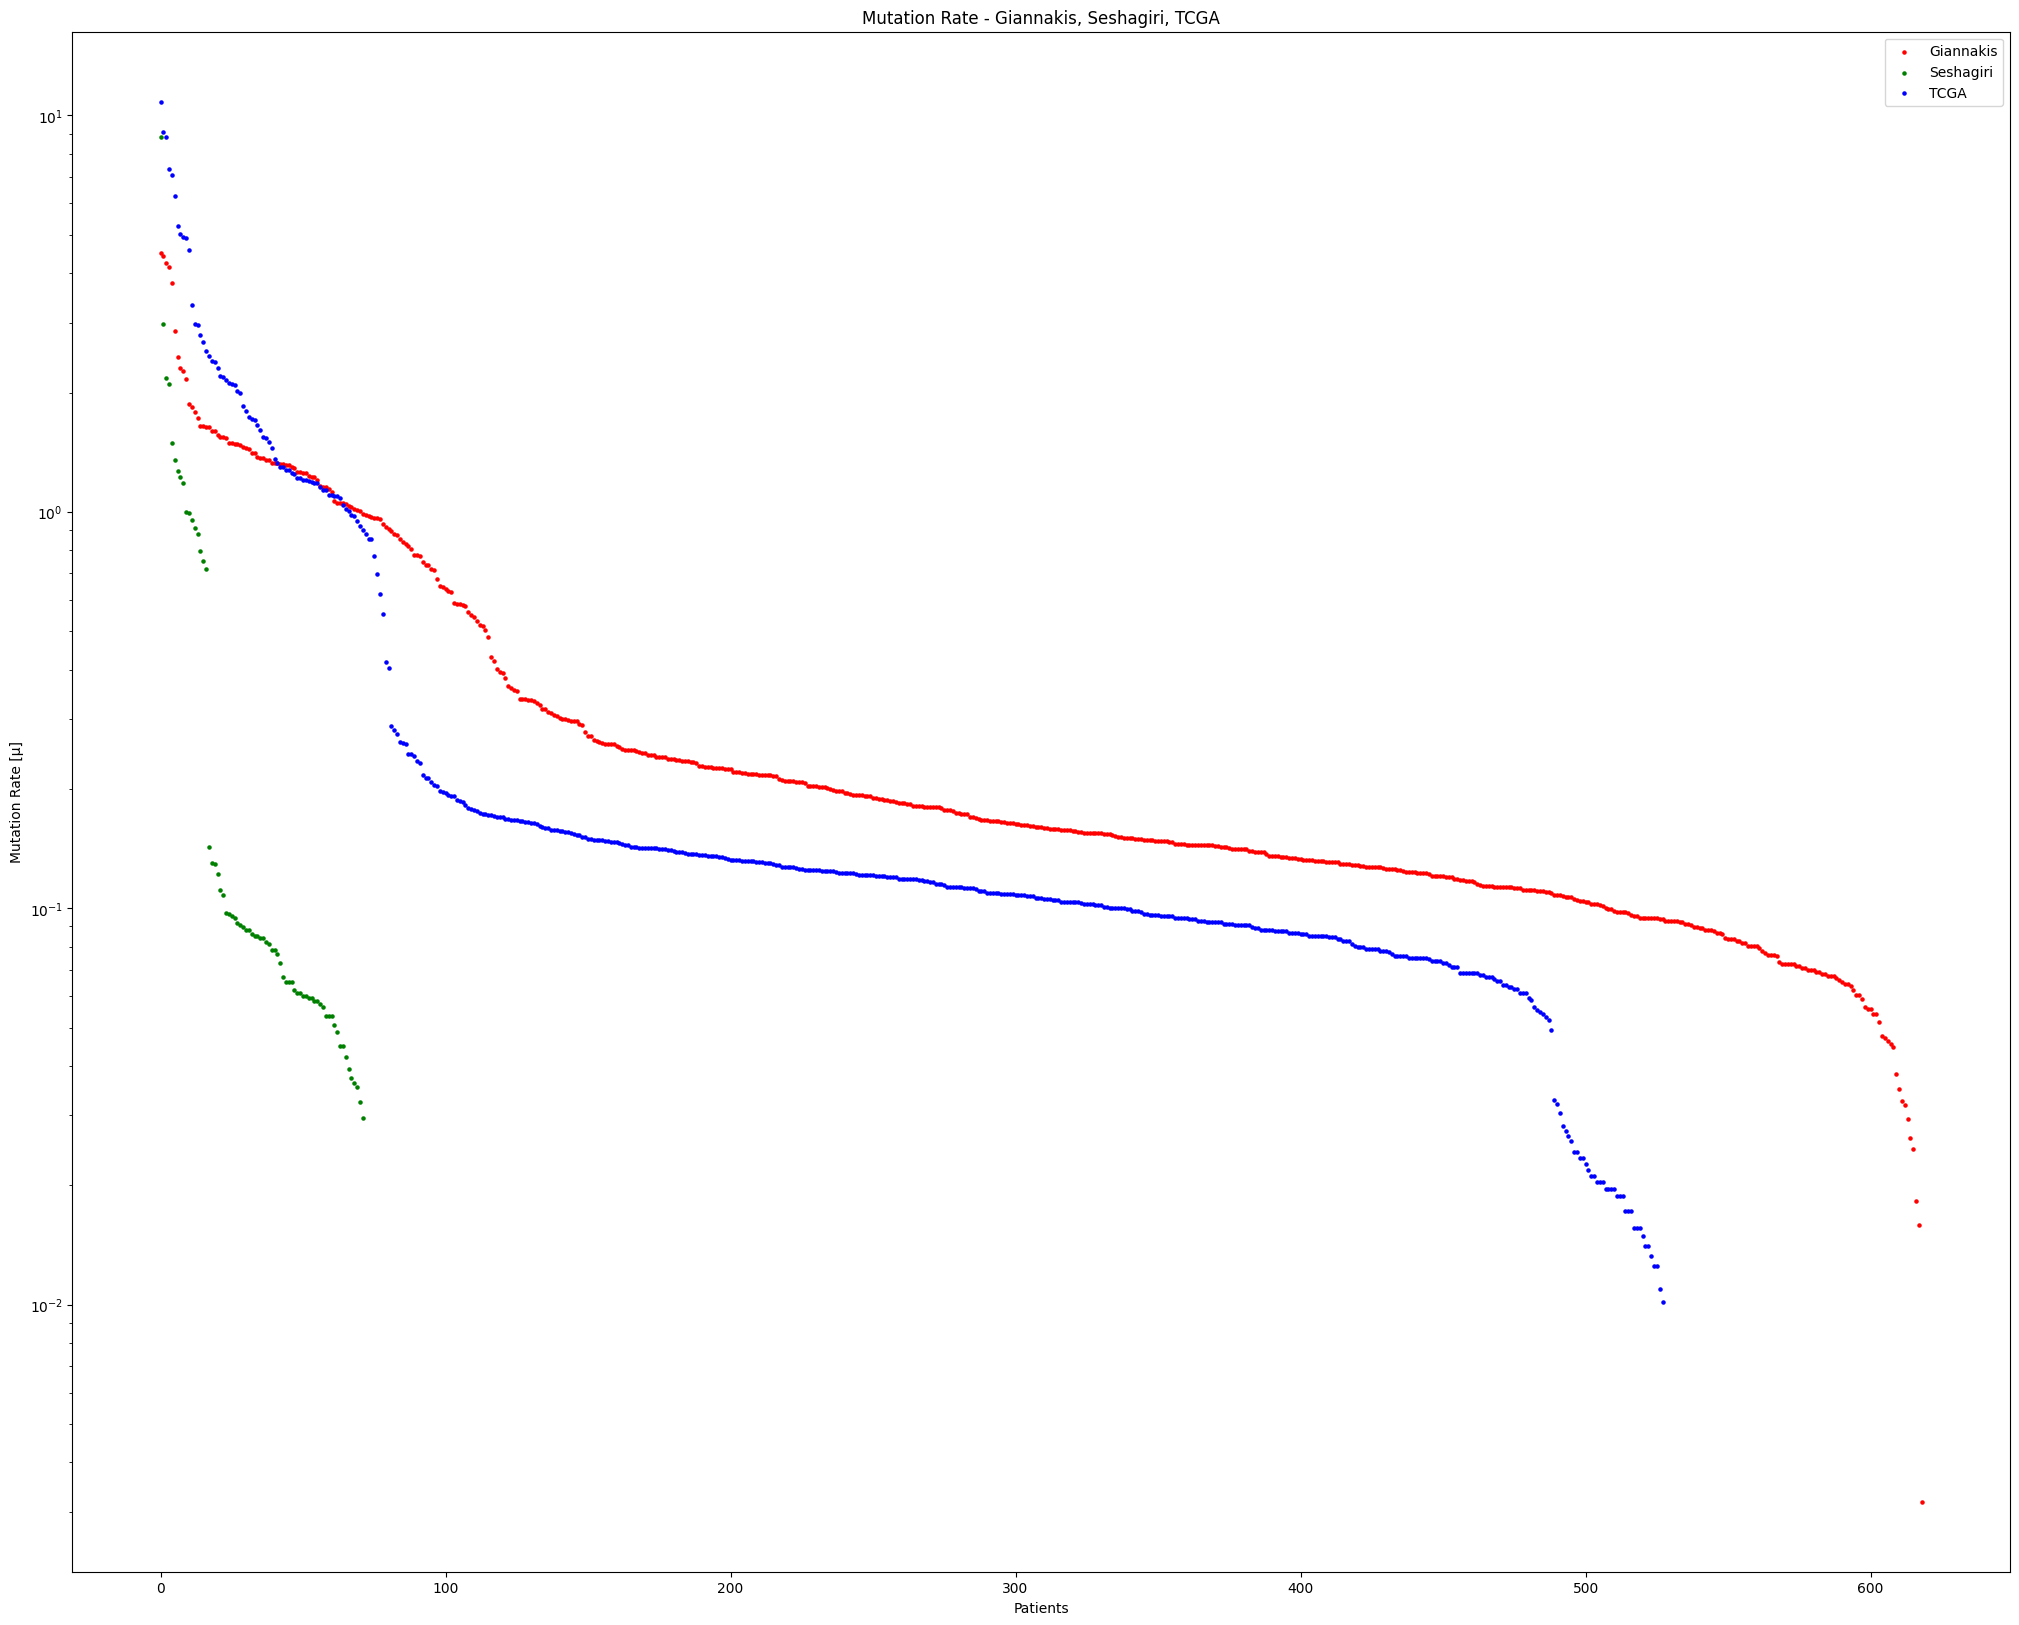

In [16]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=5)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=5)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - Giannakis, Seshagiri, TCGA')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_Seshagiri_TCGA')
plt.show()

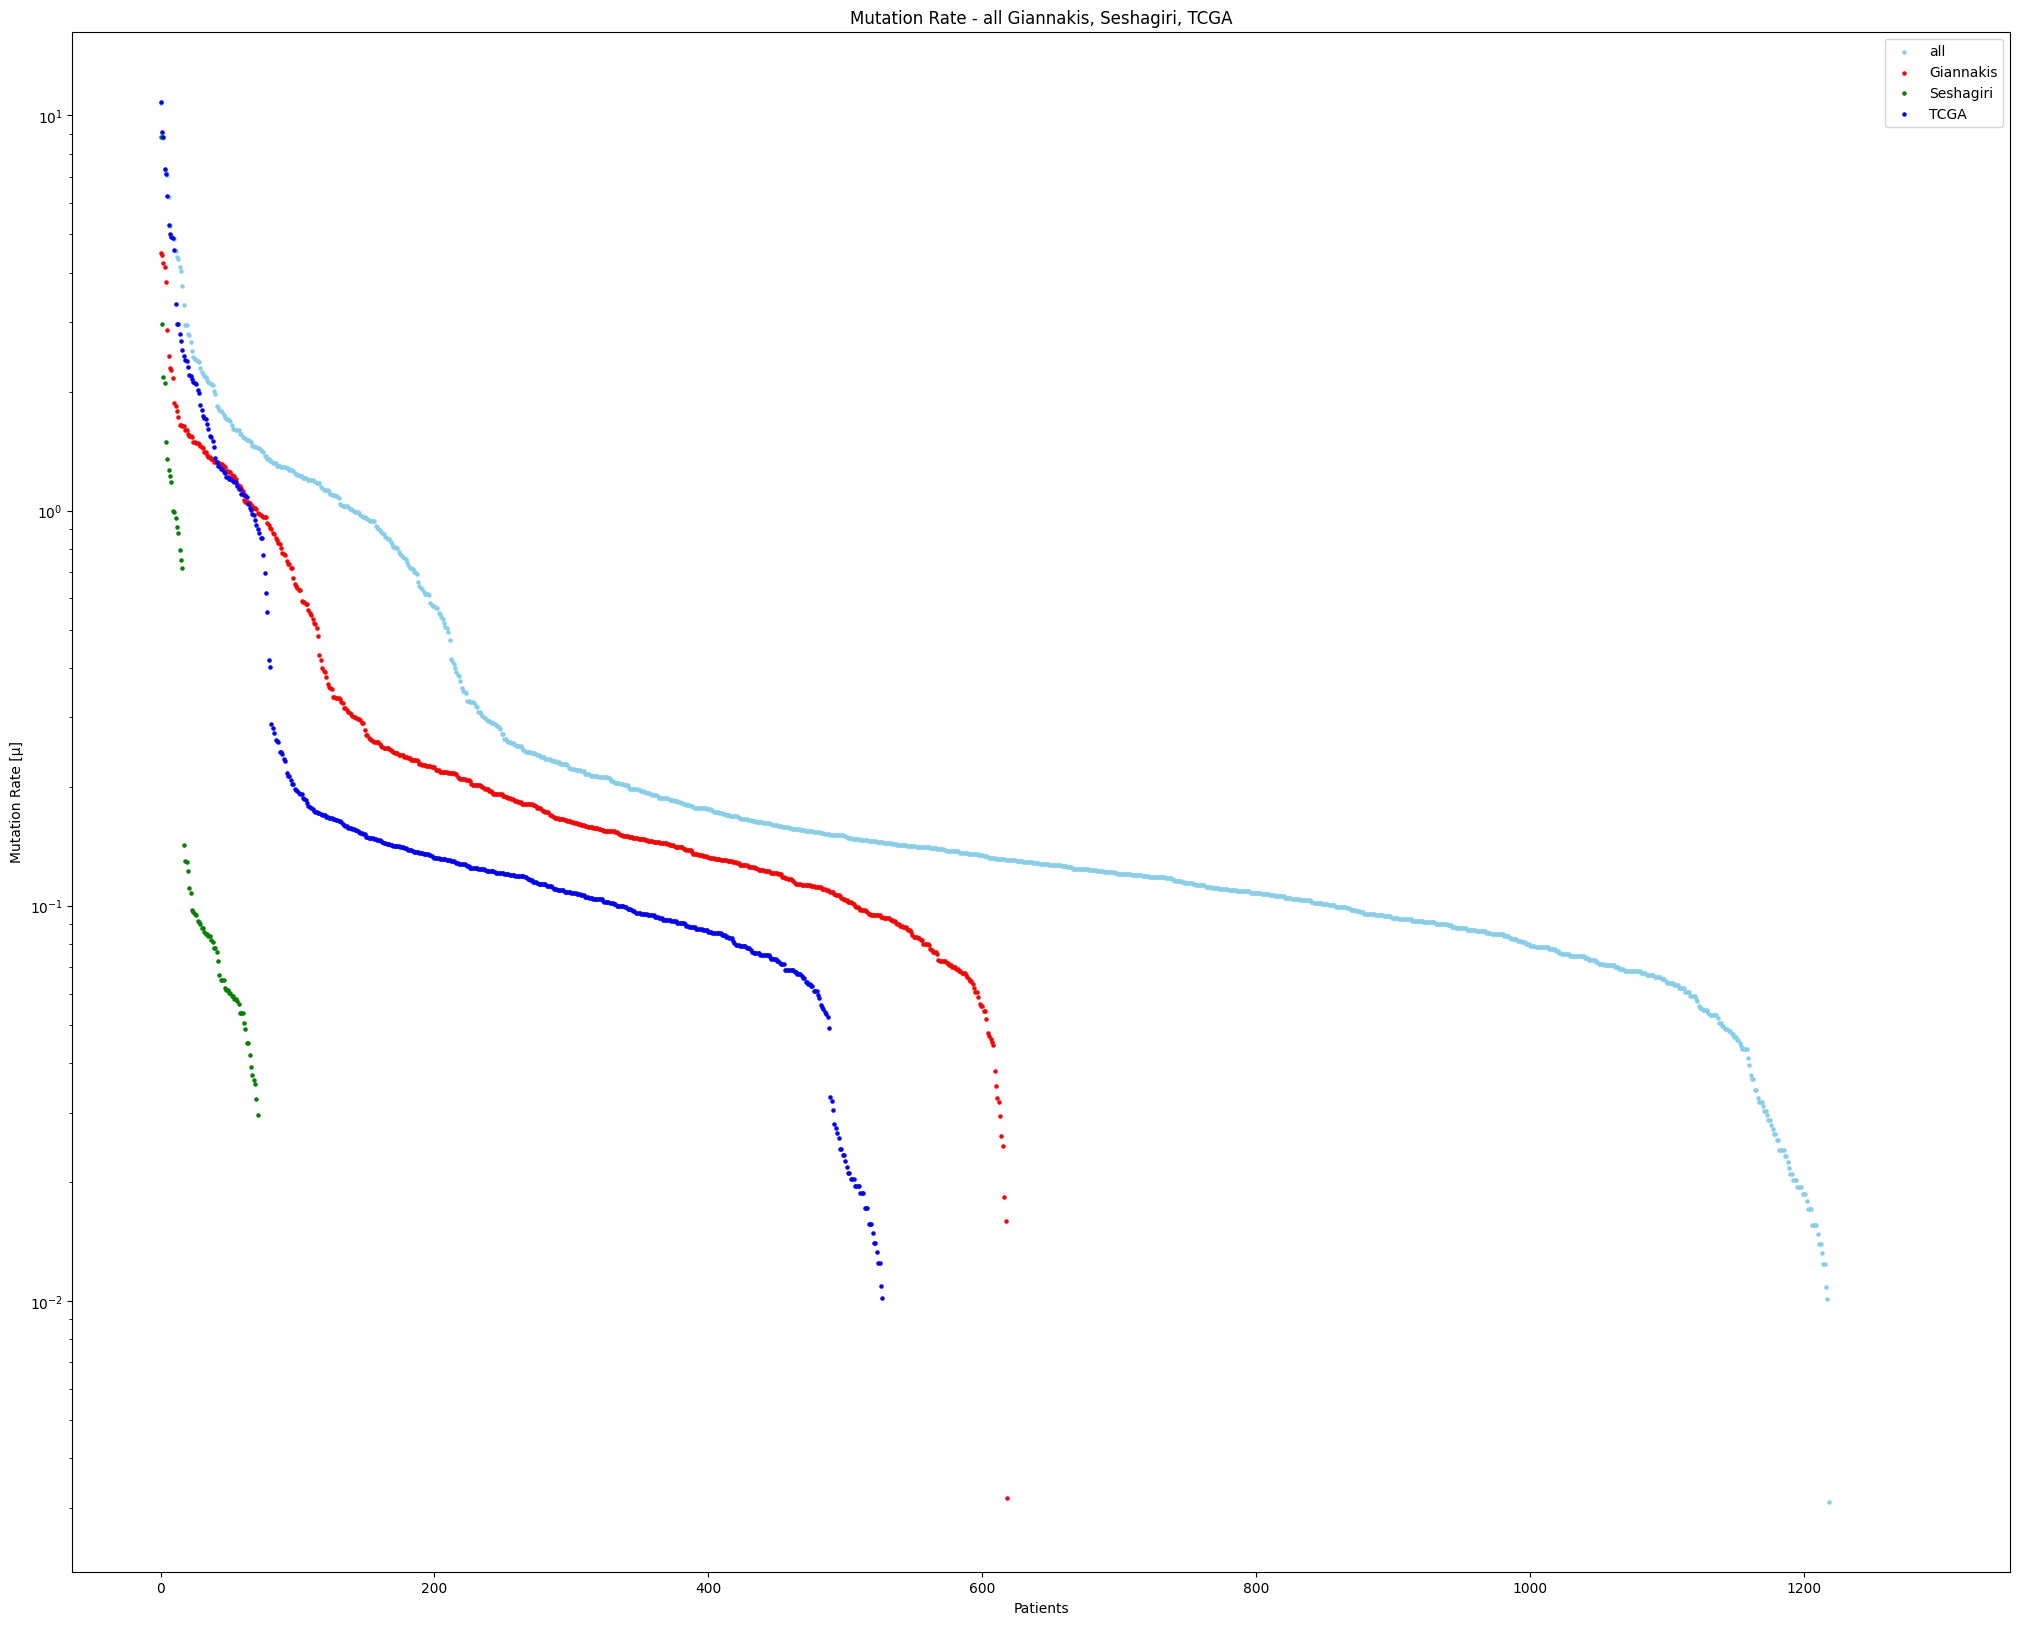

In [17]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=5)
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=5)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=5)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=5)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all', 'Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - all Giannakis, Seshagiri, TCGA')
plt.savefig(data['hypoHyper_analysis'] + 'all_Giannakis_Seshagiri_TCGA')
plt.show()

## Convex Left Knees

In [18]:
def find_knees(numMutatedBases_perPatient):
    xs = []
    ys = []
    gaps = []

    gap_max = -1
    dim_end = len(numMutatedBases_perPatient)
    while(True):
        kl  = KneeLocator(numMutatedBases_perPatient.index[:dim_end], numMutatedBases_perPatient['Mutation_Rate[µ]'].values[:dim_end], curve='convex', direction='decreasing', online=True)
        if kl.knee == None or kl.knee == 0:
            break
        x4 = kl.knee
        x3 = kl.knee - 1
        y4 = kl.knee_y
        y3 = numMutatedBases_perPatient['Mutation_Rate[µ]'].values[x3]
        gap = abs(y4 - y3)
        if gap > gap_max:
            print(str(x4) + '   -   ' + str(y4))
            gap_max = gap
            x_max = x4
            xs.append(x4)
            ys.append(y4)
            gaps.append(gap)
        dim_end = x3
    return xs, ys, gaps

In [19]:
print('all')
xs_all, ys_all, gaps_all = find_knees(numMutatedBases_perPatient_all)
print('Giannakis')
xs_Giannakis, ys_Giannakis, gaps_Giannakis = find_knees(numMutatedBases_perPatient_Giannakis)
print('Seshagiri')
xs_Seshagiri, ys_Seshagiri, gaps_Seshagiri = find_knees(numMutatedBases_perPatient_Seshagiri)
print('TCGA')
xs_TCGA, ys_TCGA, gaps_TCGA = find_knees(numMutatedBases_perPatient_TCGA)

all
232   -   0.3100836349031389
212   -   0.4204392142421006
41   -   1.8379644023707356
18   -   2.955508931169517
7   -   5.236449954830451
3   -   7.2842453883386495
Giannakis
149   -   0.2783927150270691
116   -   0.4303155966561268
61   -   1.064255579160624
14   -   1.648084872960249
10   -   1.8723898604963447
6   -   2.4586053775676304
Seshagiri
17   -   0.1424127974517797
4   -   1.491033315602526
TCGA
81   -   0.28845164740223445
29   -   1.8487483634316655
12   -   2.9728499053406443
6   -   5.267173984271697


In [20]:
# put xs, ys, and gaps in df
knees_ConvexLeft_all = pd.DataFrame({'x': xs_all, 'y': ys_all, 'gap': gaps_all})
knees_ConvexLeft_Giannakis = pd.DataFrame({'x': xs_Giannakis, 'y': ys_Giannakis, 'gap': gaps_Giannakis})
knees_ConvexLeft_Seshagiri = pd.DataFrame({'x': xs_Seshagiri, 'y': ys_Seshagiri, 'gap': gaps_Seshagiri})
knees_ConvexLeft_TCGA = pd.DataFrame({'x': xs_TCGA, 'y': ys_TCGA, 'gap': gaps_TCGA})

In [21]:
# add number of giannakis patient with mut rate above y to df
knees_ConvexLeft_all['#all'] = knees_ConvexLeft_all.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_all['#giannakis'] = knees_ConvexLeft_all.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_all['#seshagiri'] = knees_ConvexLeft_all.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_all['#TCGA'] = knees_ConvexLeft_all.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] > row['y']), axis=1)

knees_ConvexLeft_Giannakis['#all'] = knees_ConvexLeft_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Giannakis['#giannakis'] = knees_ConvexLeft_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Giannakis['#seshagiri'] = knees_ConvexLeft_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Giannakis['#TCGA'] = knees_ConvexLeft_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] > row['y']), axis=1)

knees_ConvexLeft_Seshagiri['#all'] = knees_ConvexLeft_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Seshagiri['#giannakis'] = knees_ConvexLeft_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Seshagiri['#seshagiri'] = knees_ConvexLeft_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_Seshagiri['#TCGA'] = knees_ConvexLeft_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] > row['y']), axis=1)

knees_ConvexLeft_TCGA['#all'] = knees_ConvexLeft_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_TCGA['#giannakis'] = knees_ConvexLeft_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_TCGA['#seshagiri'] = knees_ConvexLeft_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] > row['y']), axis=1)
knees_ConvexLeft_TCGA['#TCGA'] = knees_ConvexLeft_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] > row['y']), axis=1)

In [22]:
# save them
knees_ConvexLeft_all.to_csv(data['hypoHyper_analysis'] + 'knees_ConvexLeft_all.csv', index=False)
knees_ConvexLeft_Giannakis.to_csv(data['hypoHyper_analysis'] + 'knees_ConvexLeft_Giannakis.csv', index=False)
knees_ConvexLeft_Seshagiri.to_csv(data['hypoHyper_analysis'] + 'knees_ConvexLeft_Seshagiri.csv', index=False)
knees_ConvexLeft_TCGA.to_csv(data['hypoHyper_analysis'] + 'knees_ConvexLeft_TCGA.csv', index=False)

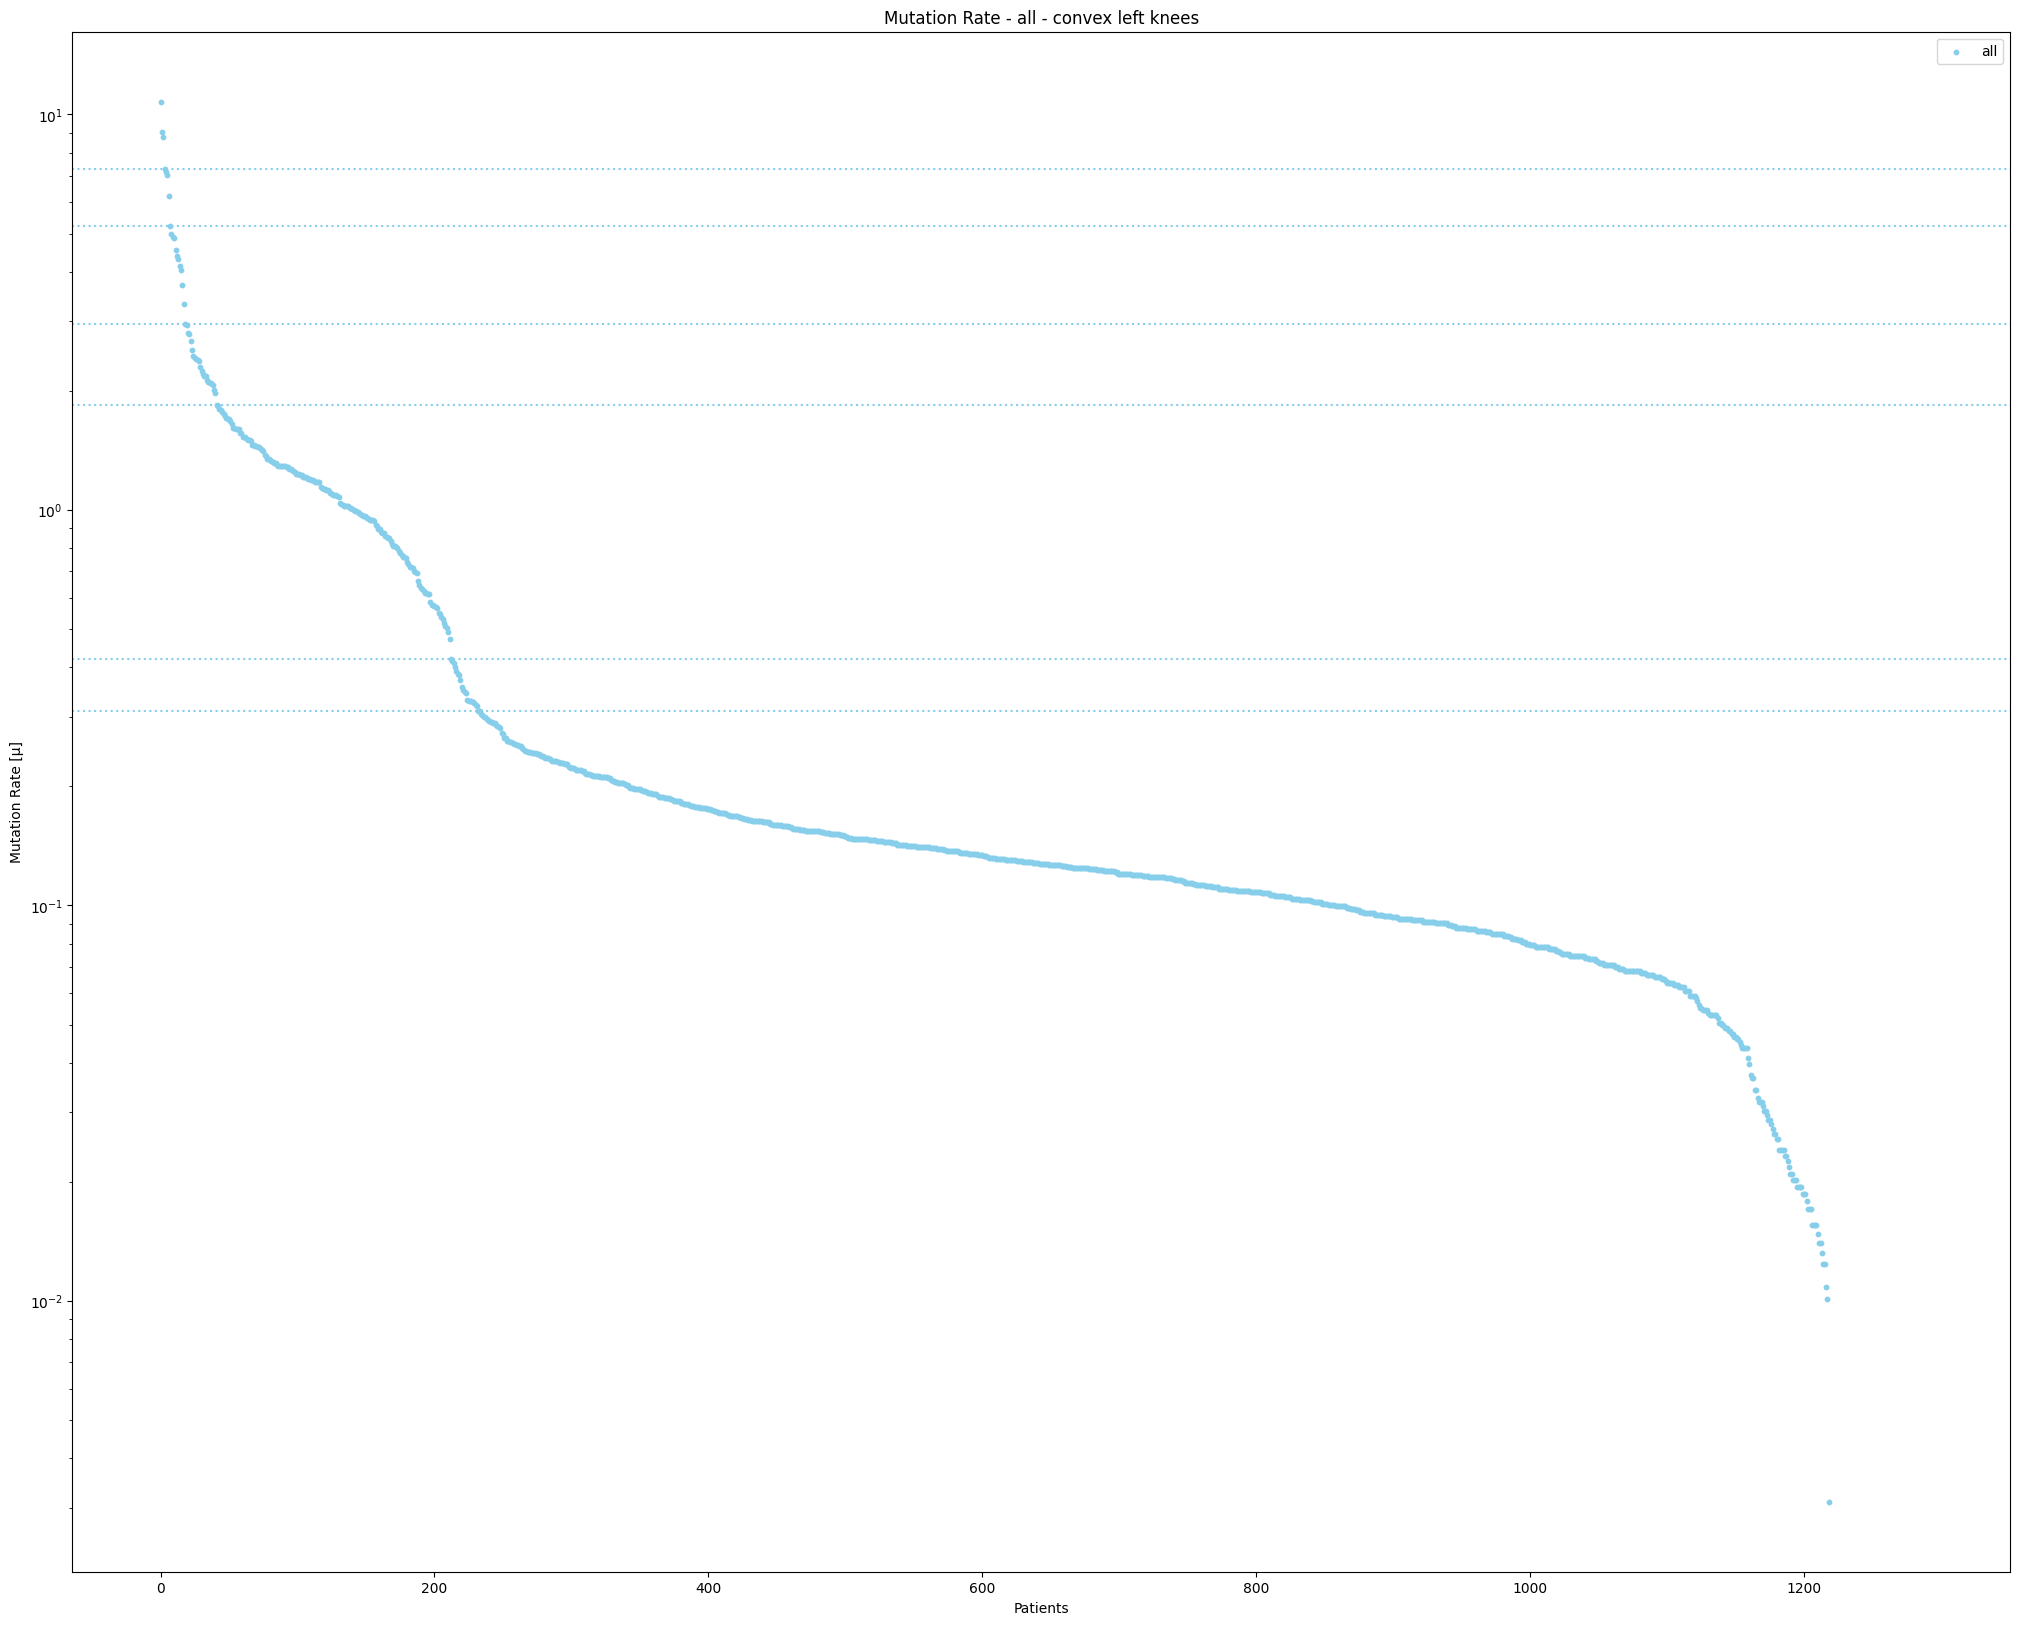

In [23]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all'])
plt.title('Mutation Rate - all - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'all_convexLeftKnees')
plt.show()

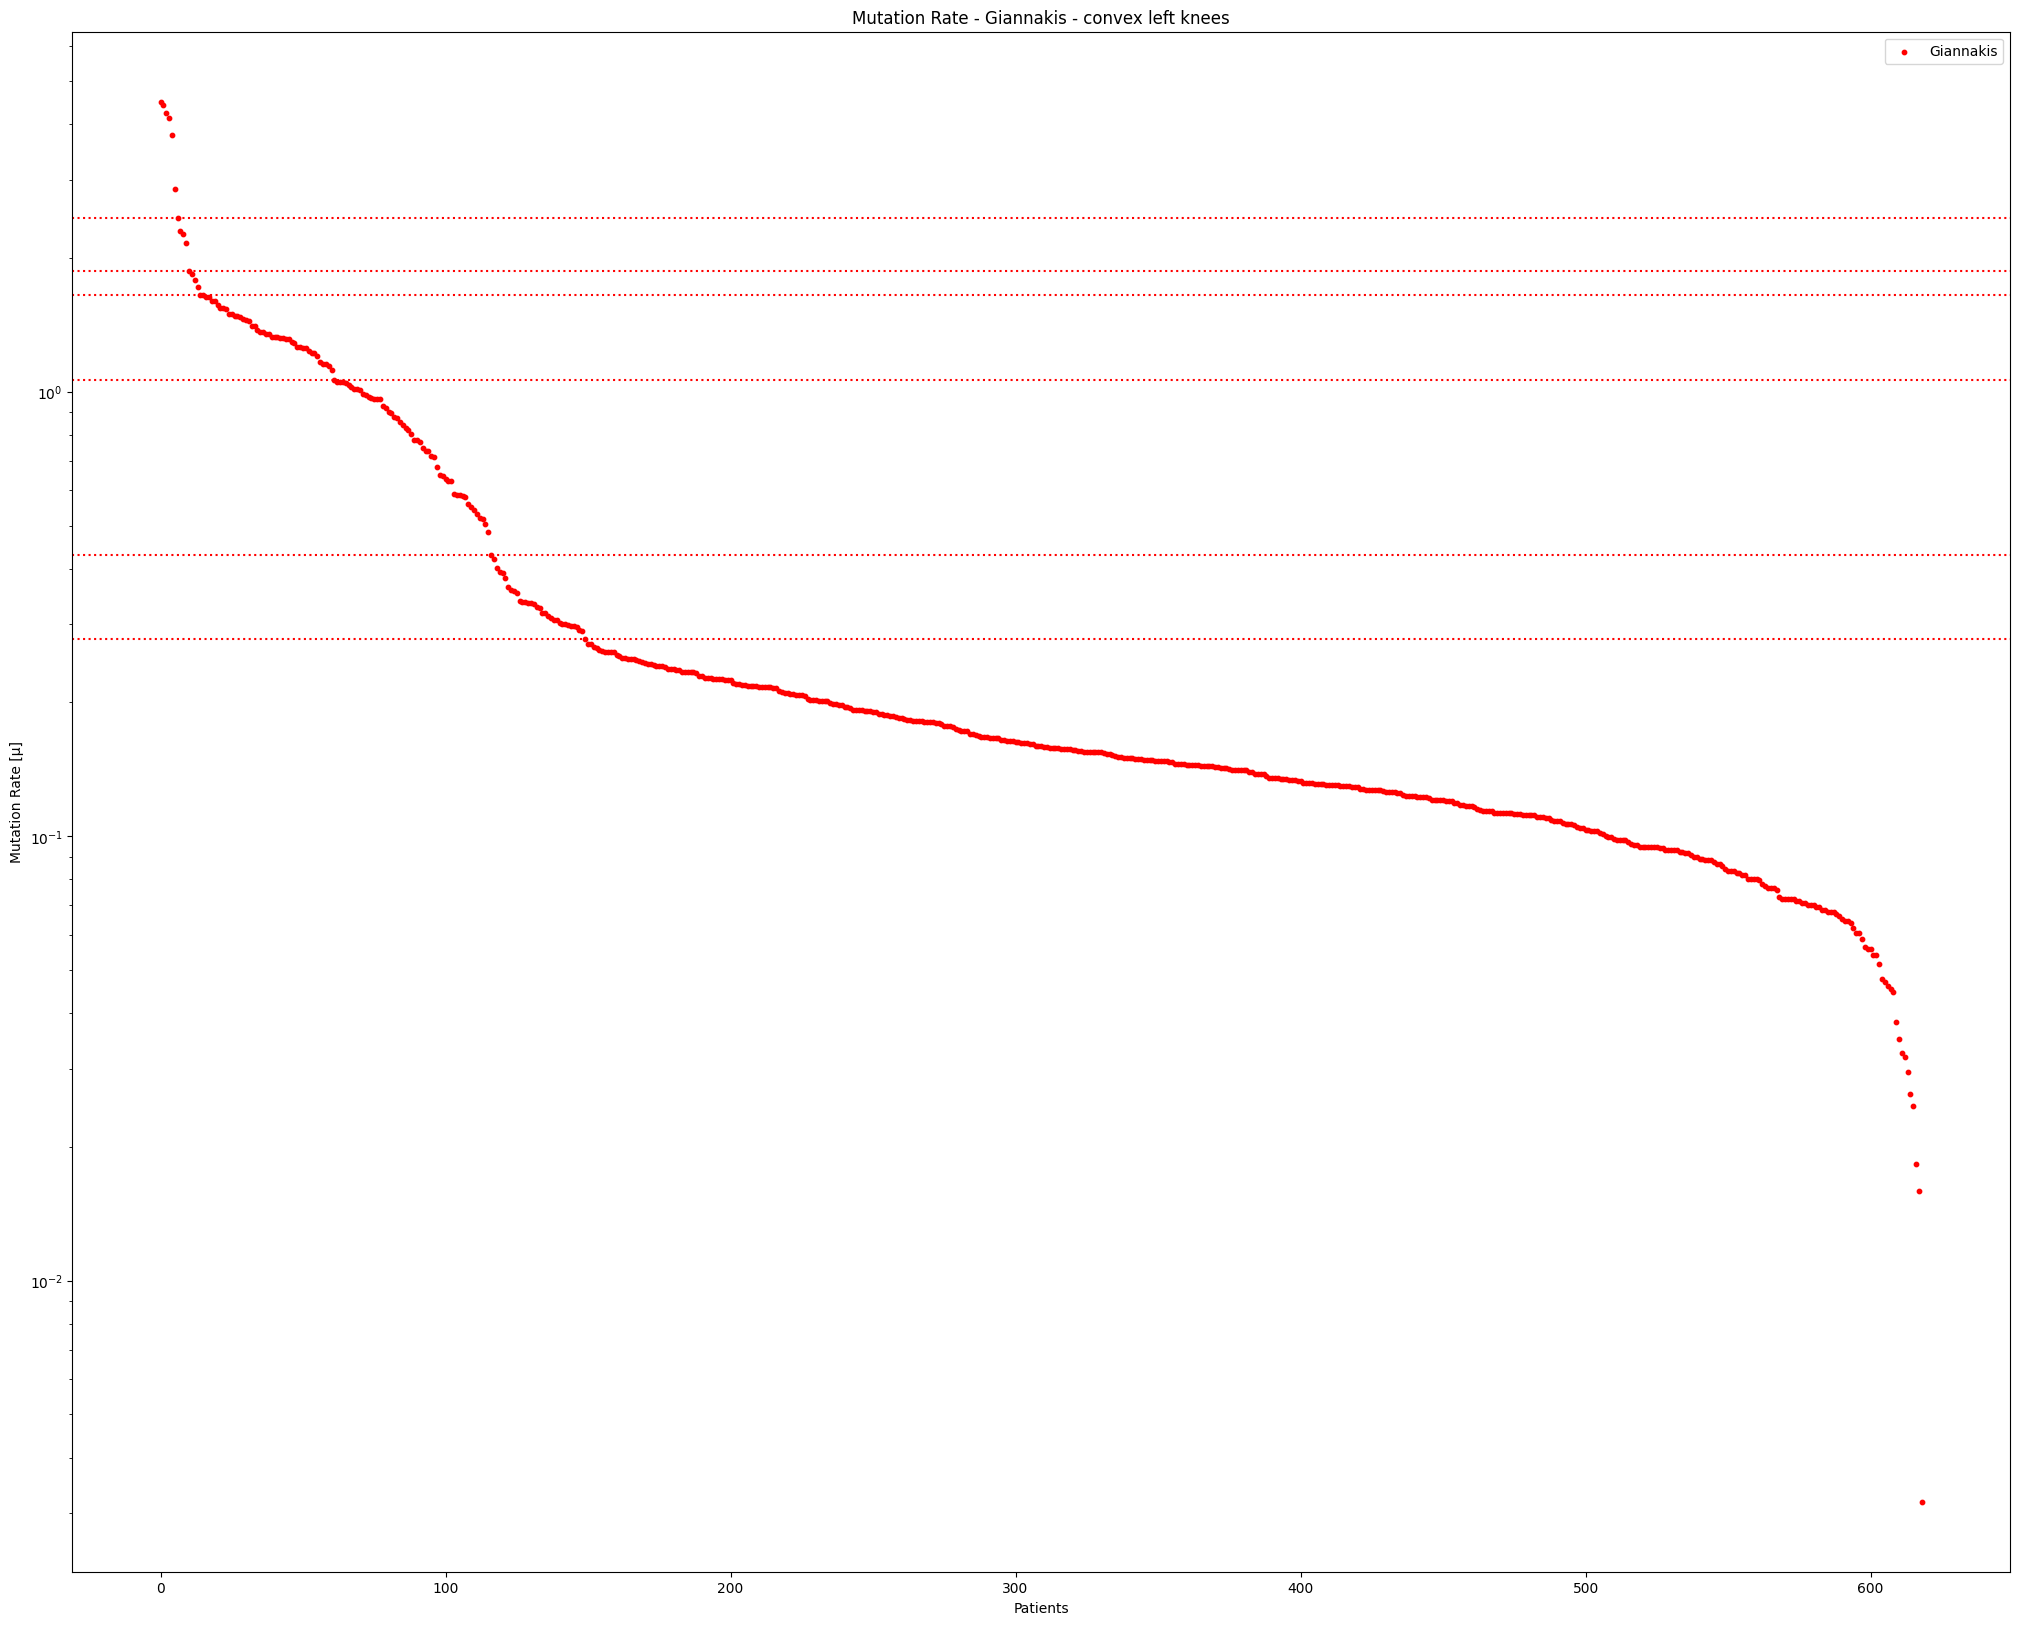

In [24]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis'])
plt.title('Mutation Rate - Giannakis - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_convexLeftKnees')
plt.show()

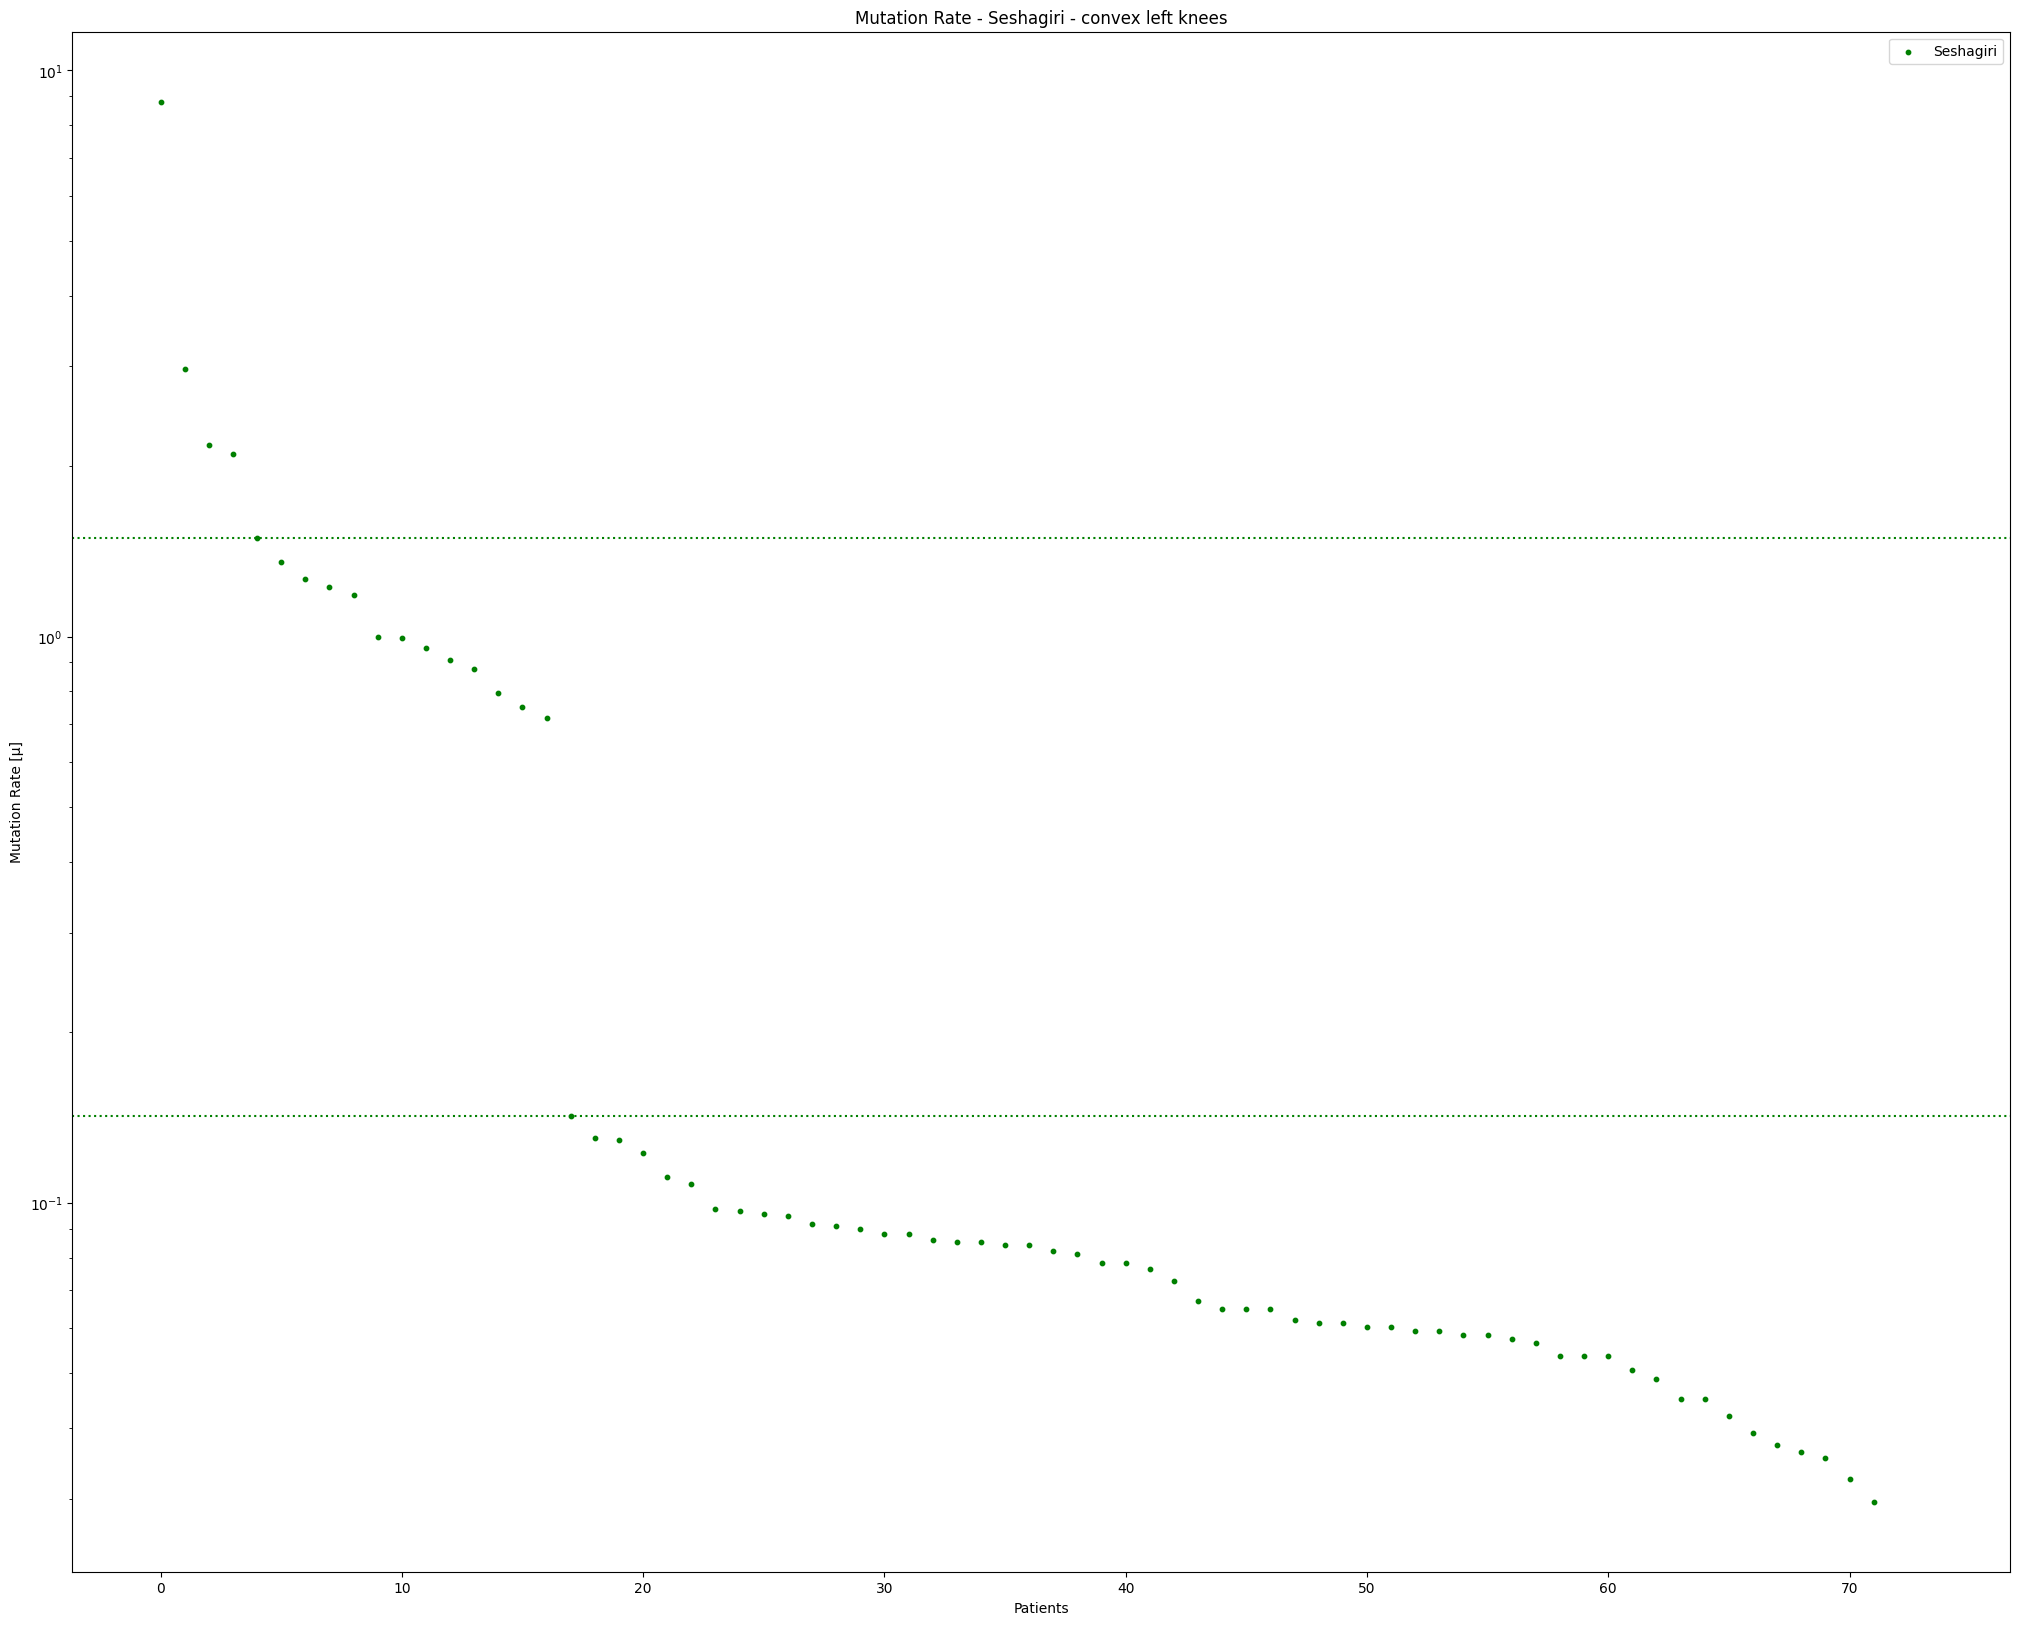

In [25]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Seshagiri'])
plt.title('Mutation Rate - Seshagiri - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'Seshagiri_convexLeftKnees')
plt.show()

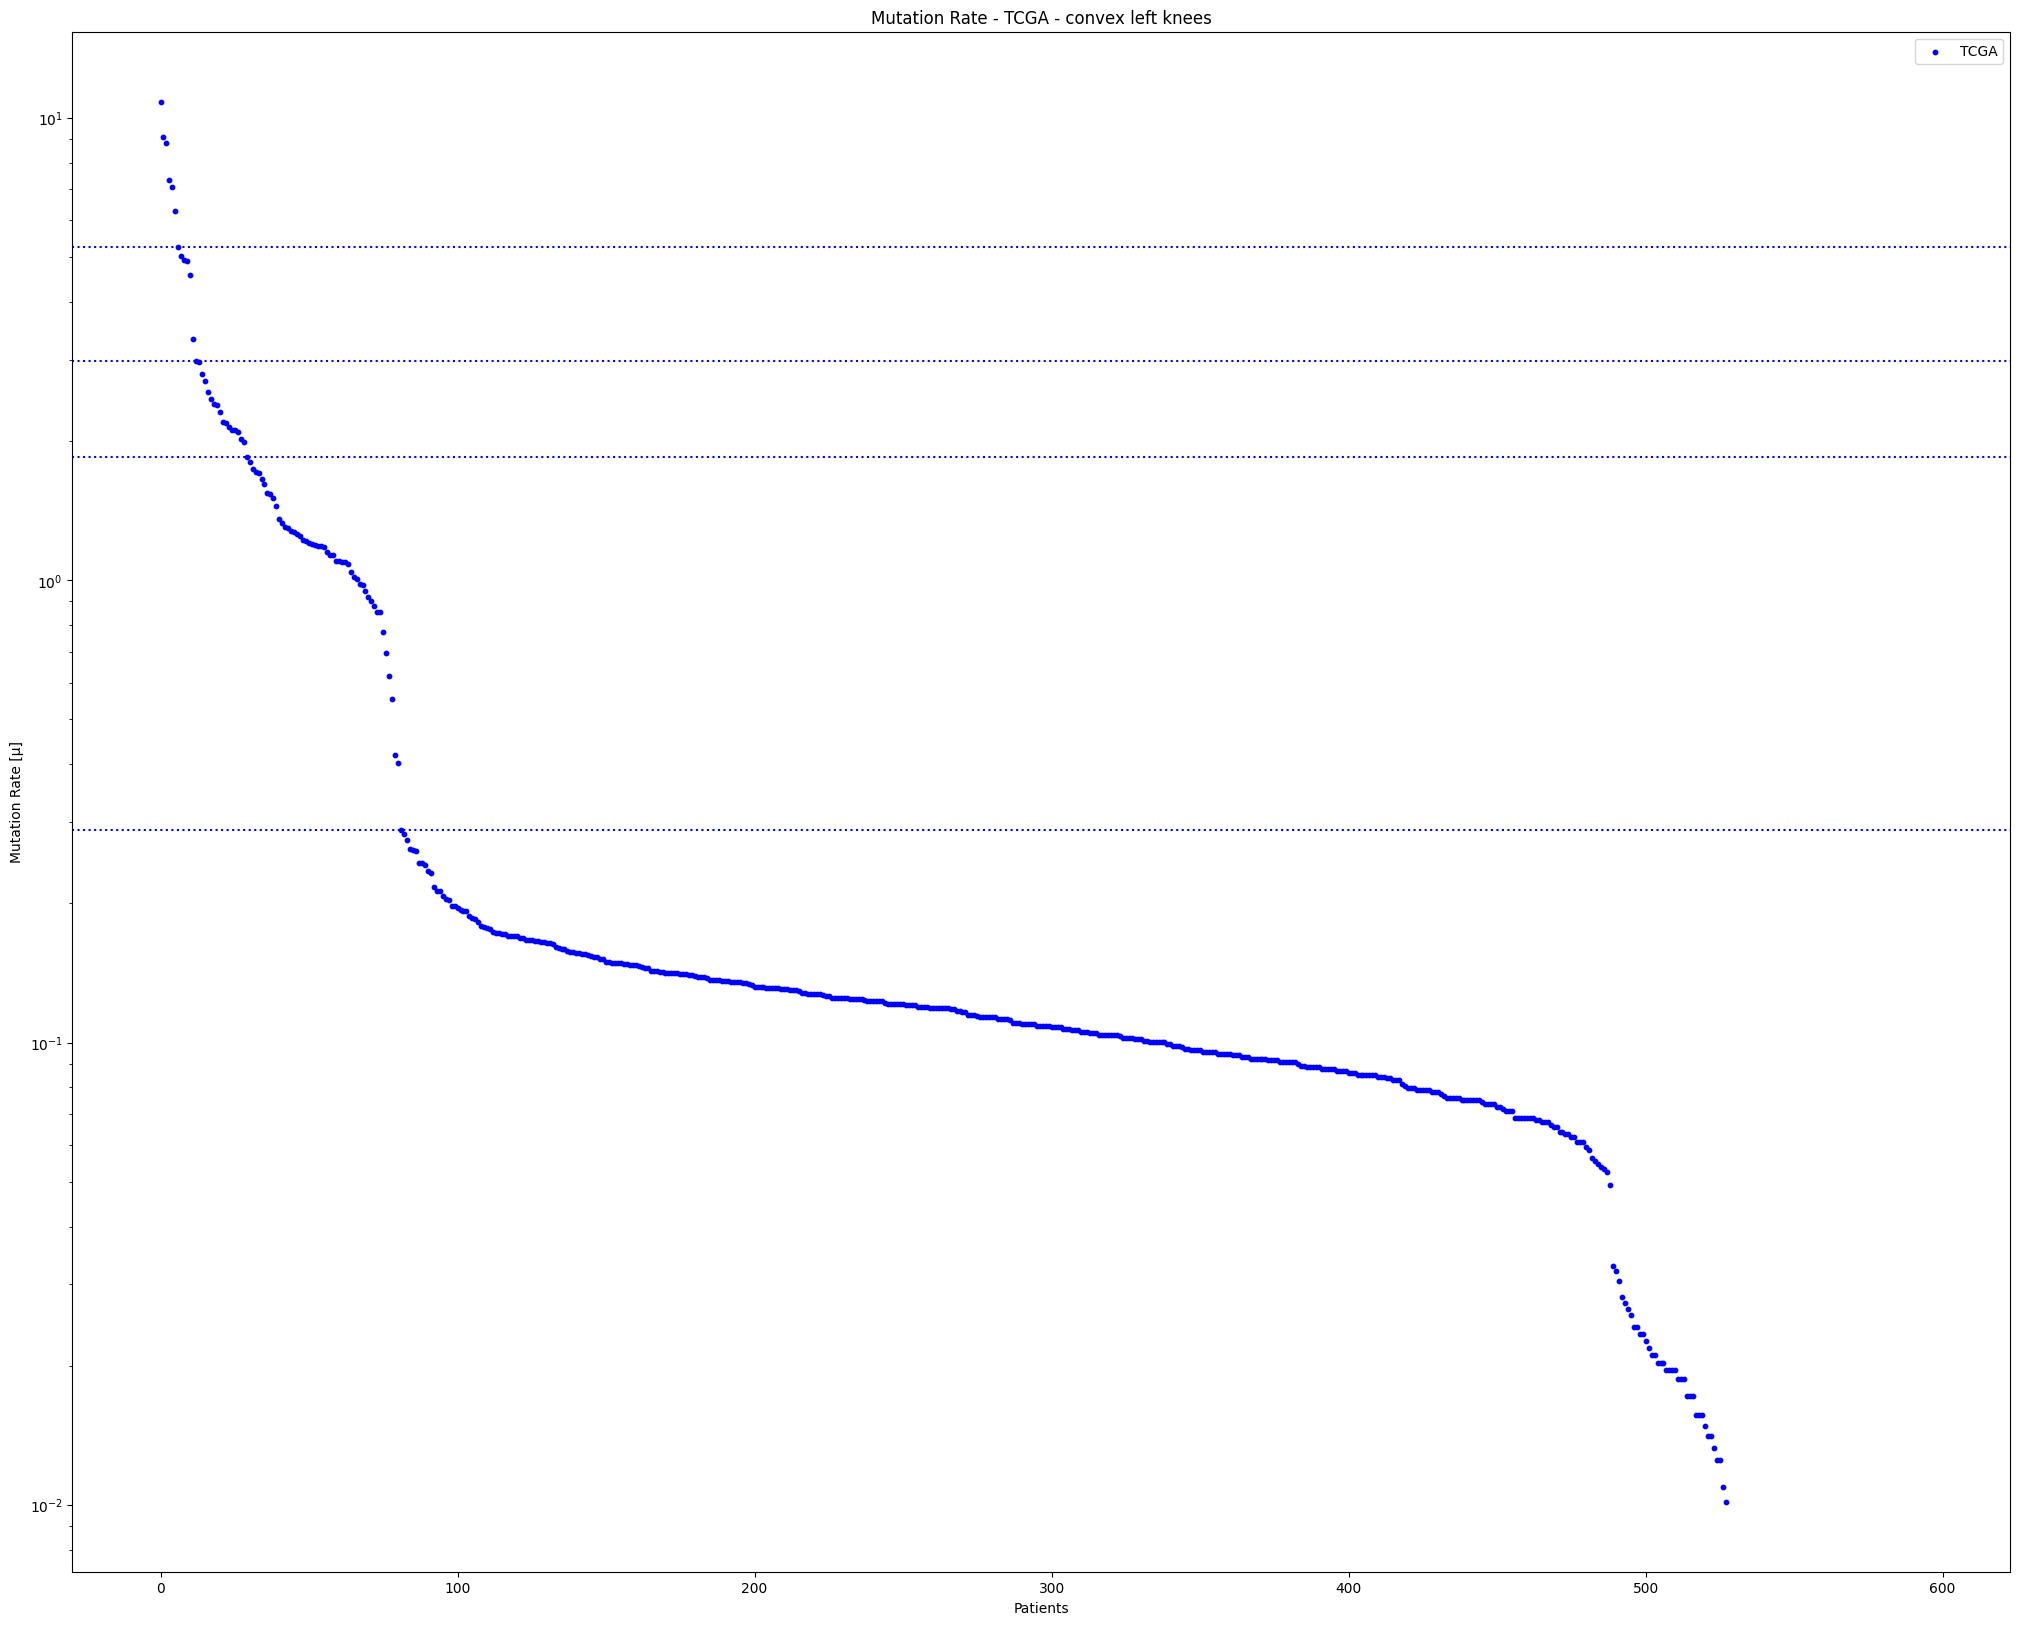

In [26]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['TCGA'])
plt.title('Mutation Rate - TCGA - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'TCGA_convexLeftKnees')
plt.show()

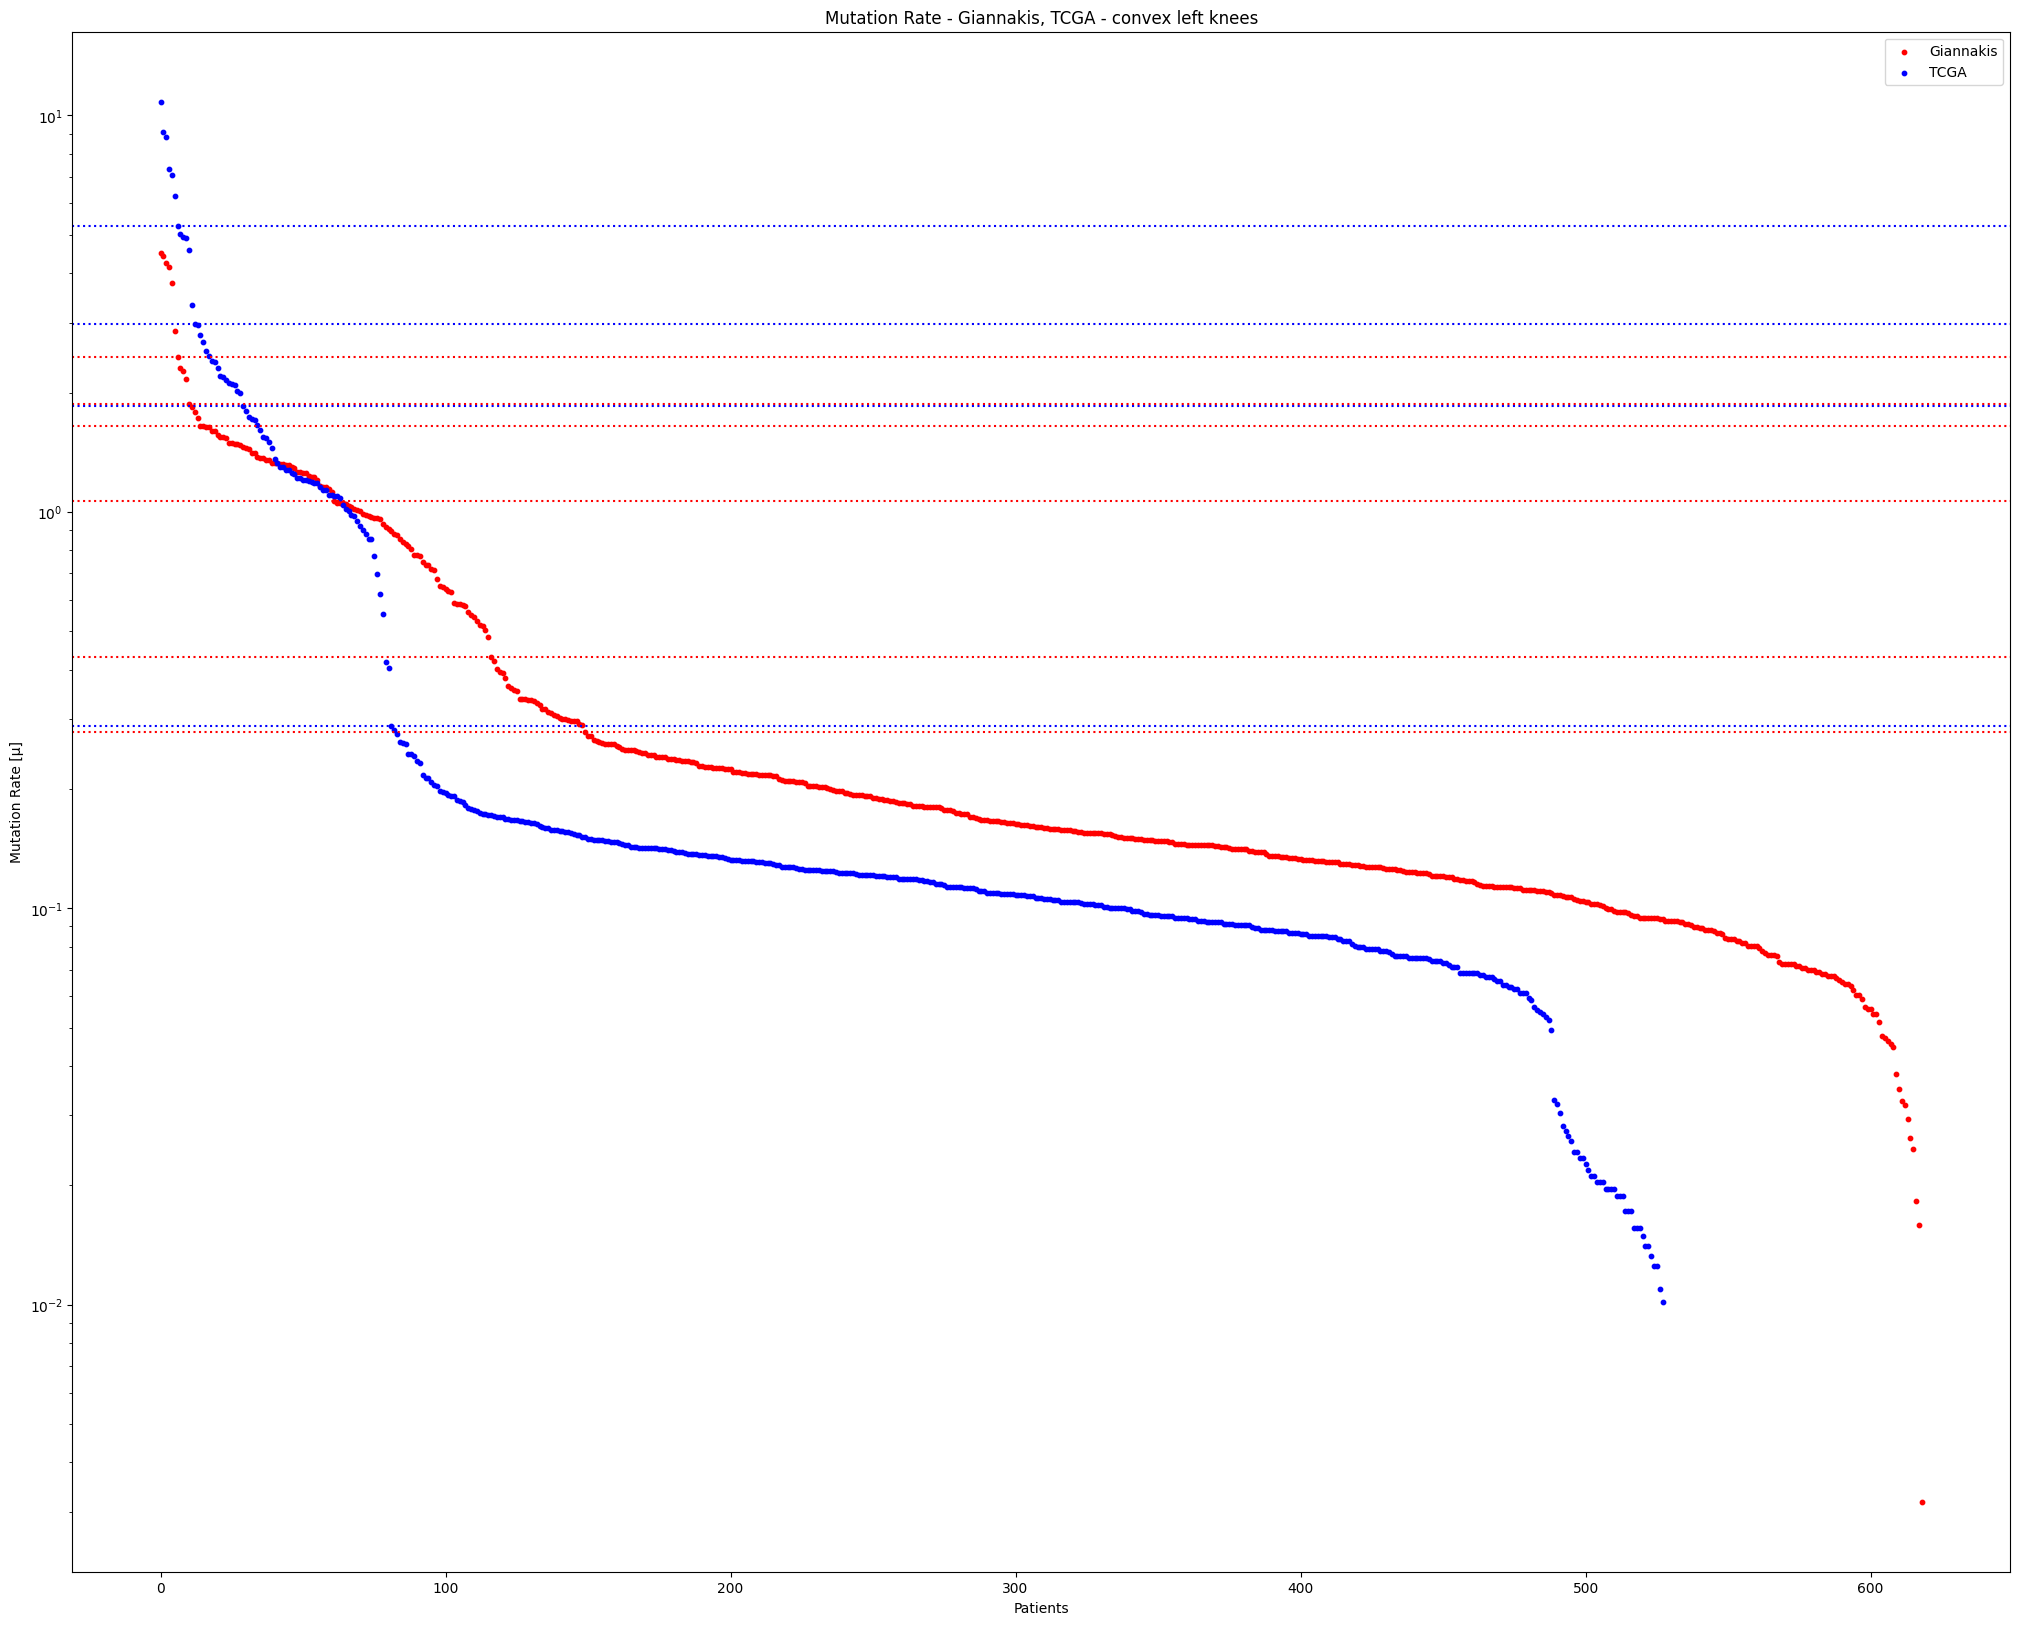

In [27]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis', 'TCGA'])
plt.title('Mutation Rate - Giannakis, TCGA - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_TCGA_convexLeftKnees')
plt.show()

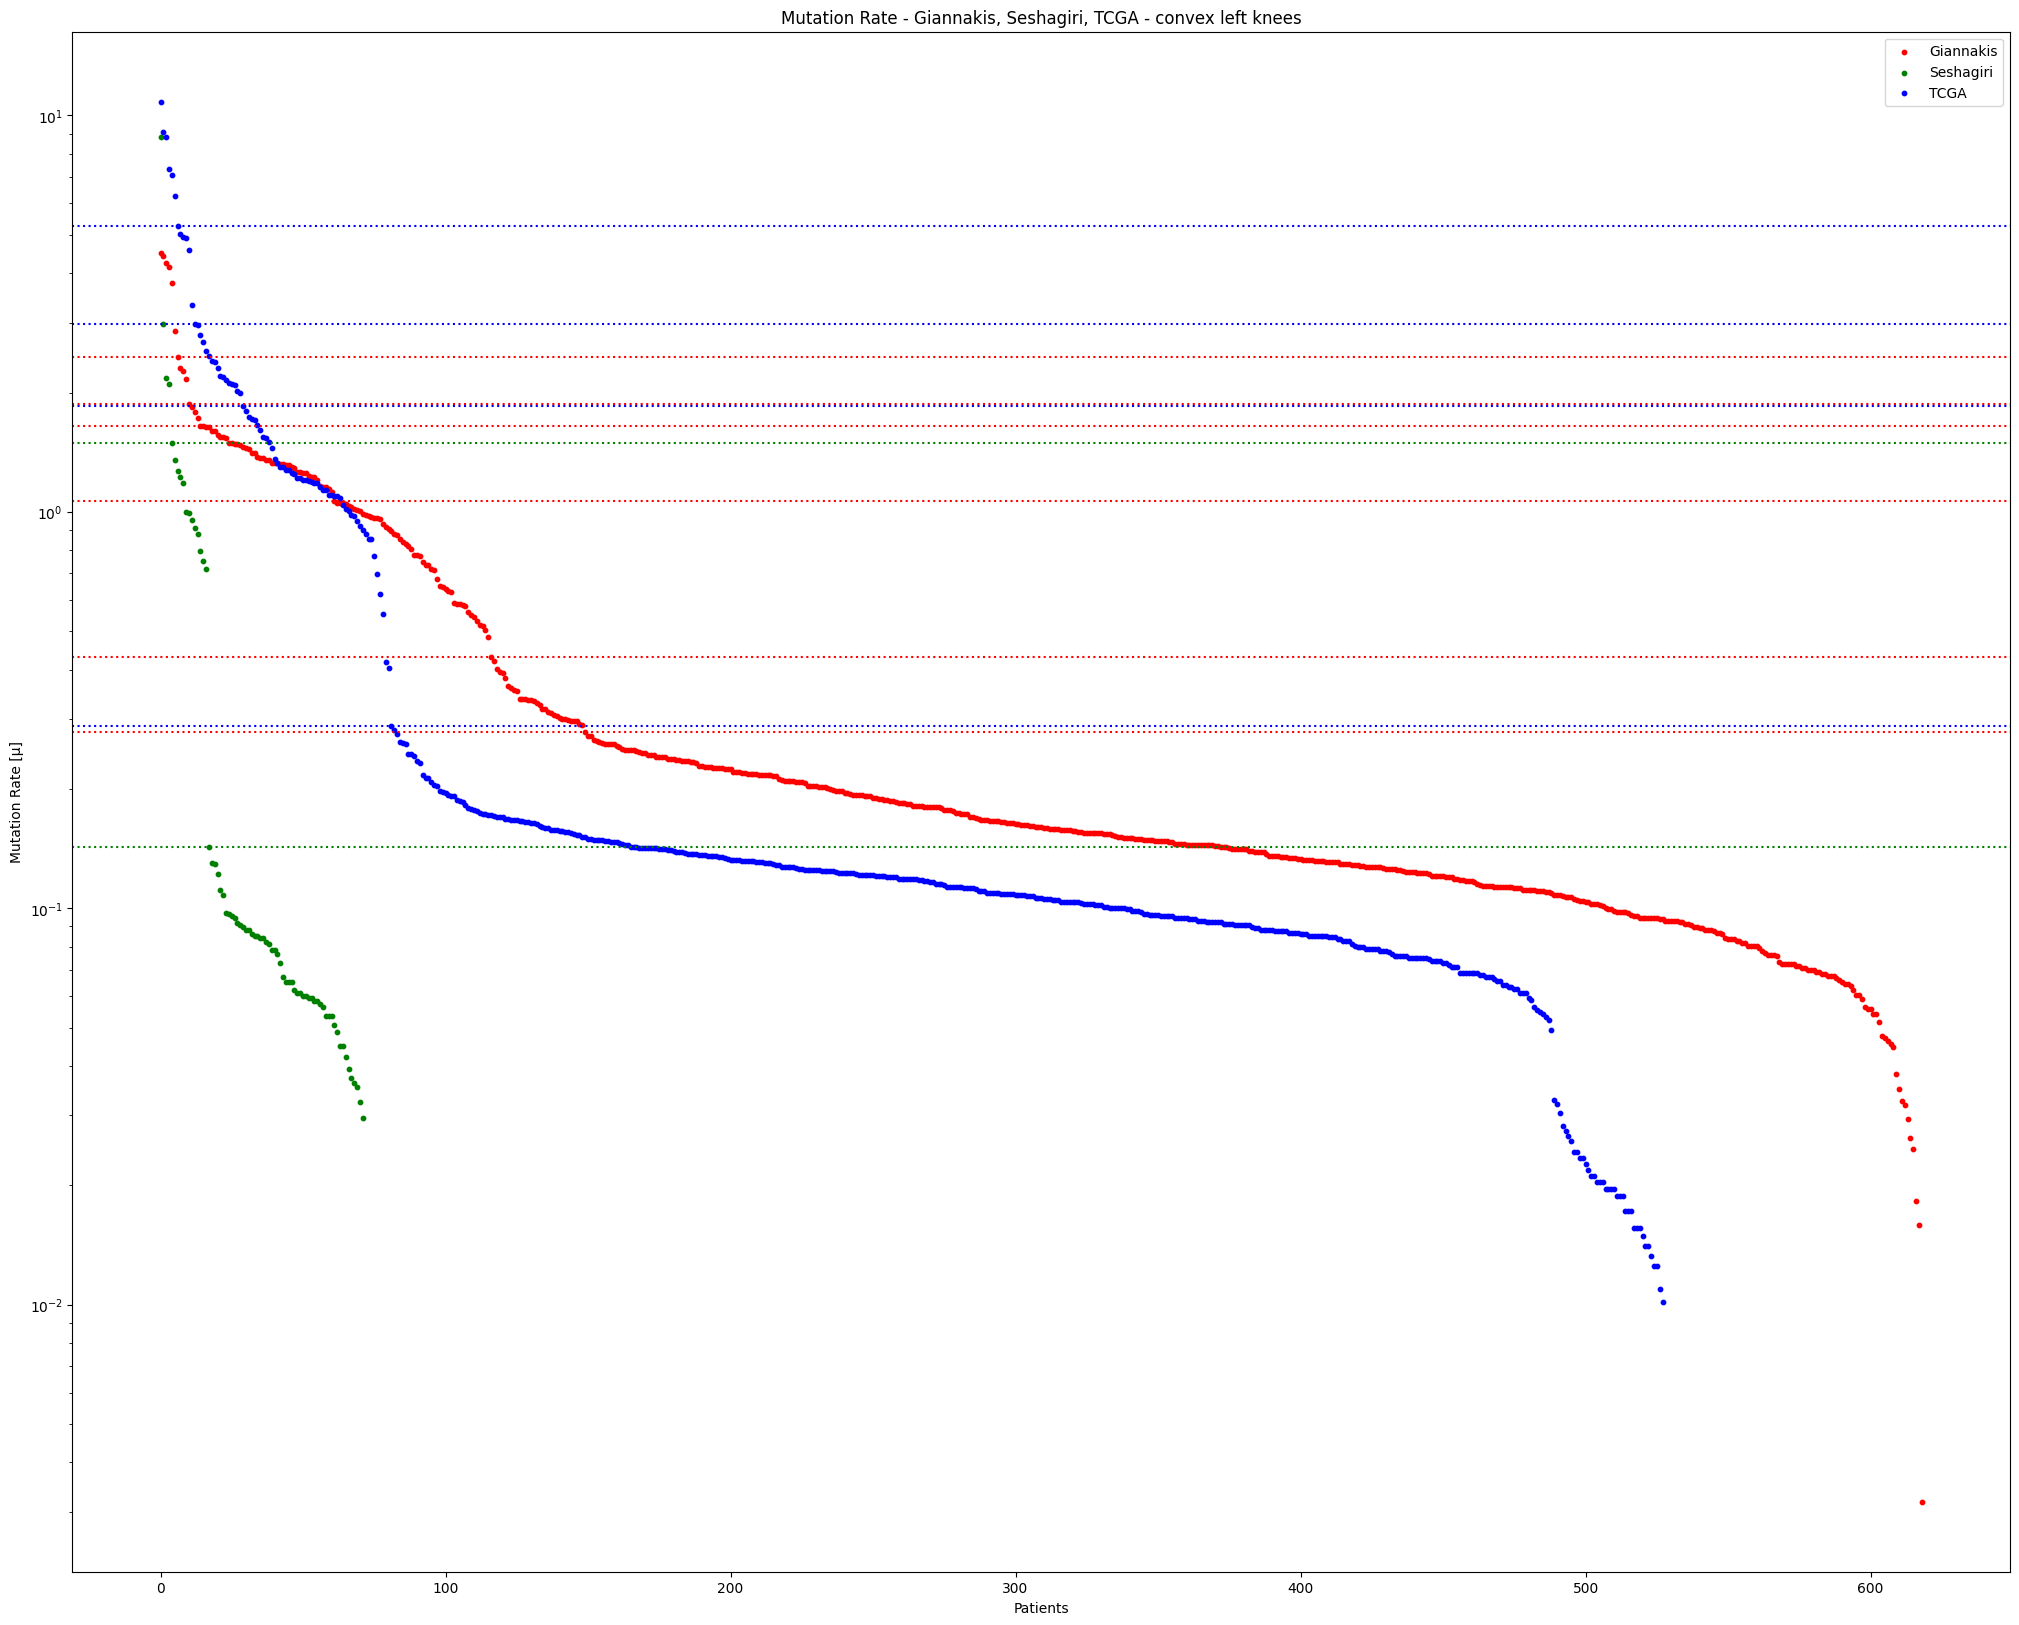

In [28]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - Giannakis, Seshagiri, TCGA - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_Seshagiri_TCGA_convexLeftKnees')
plt.show()

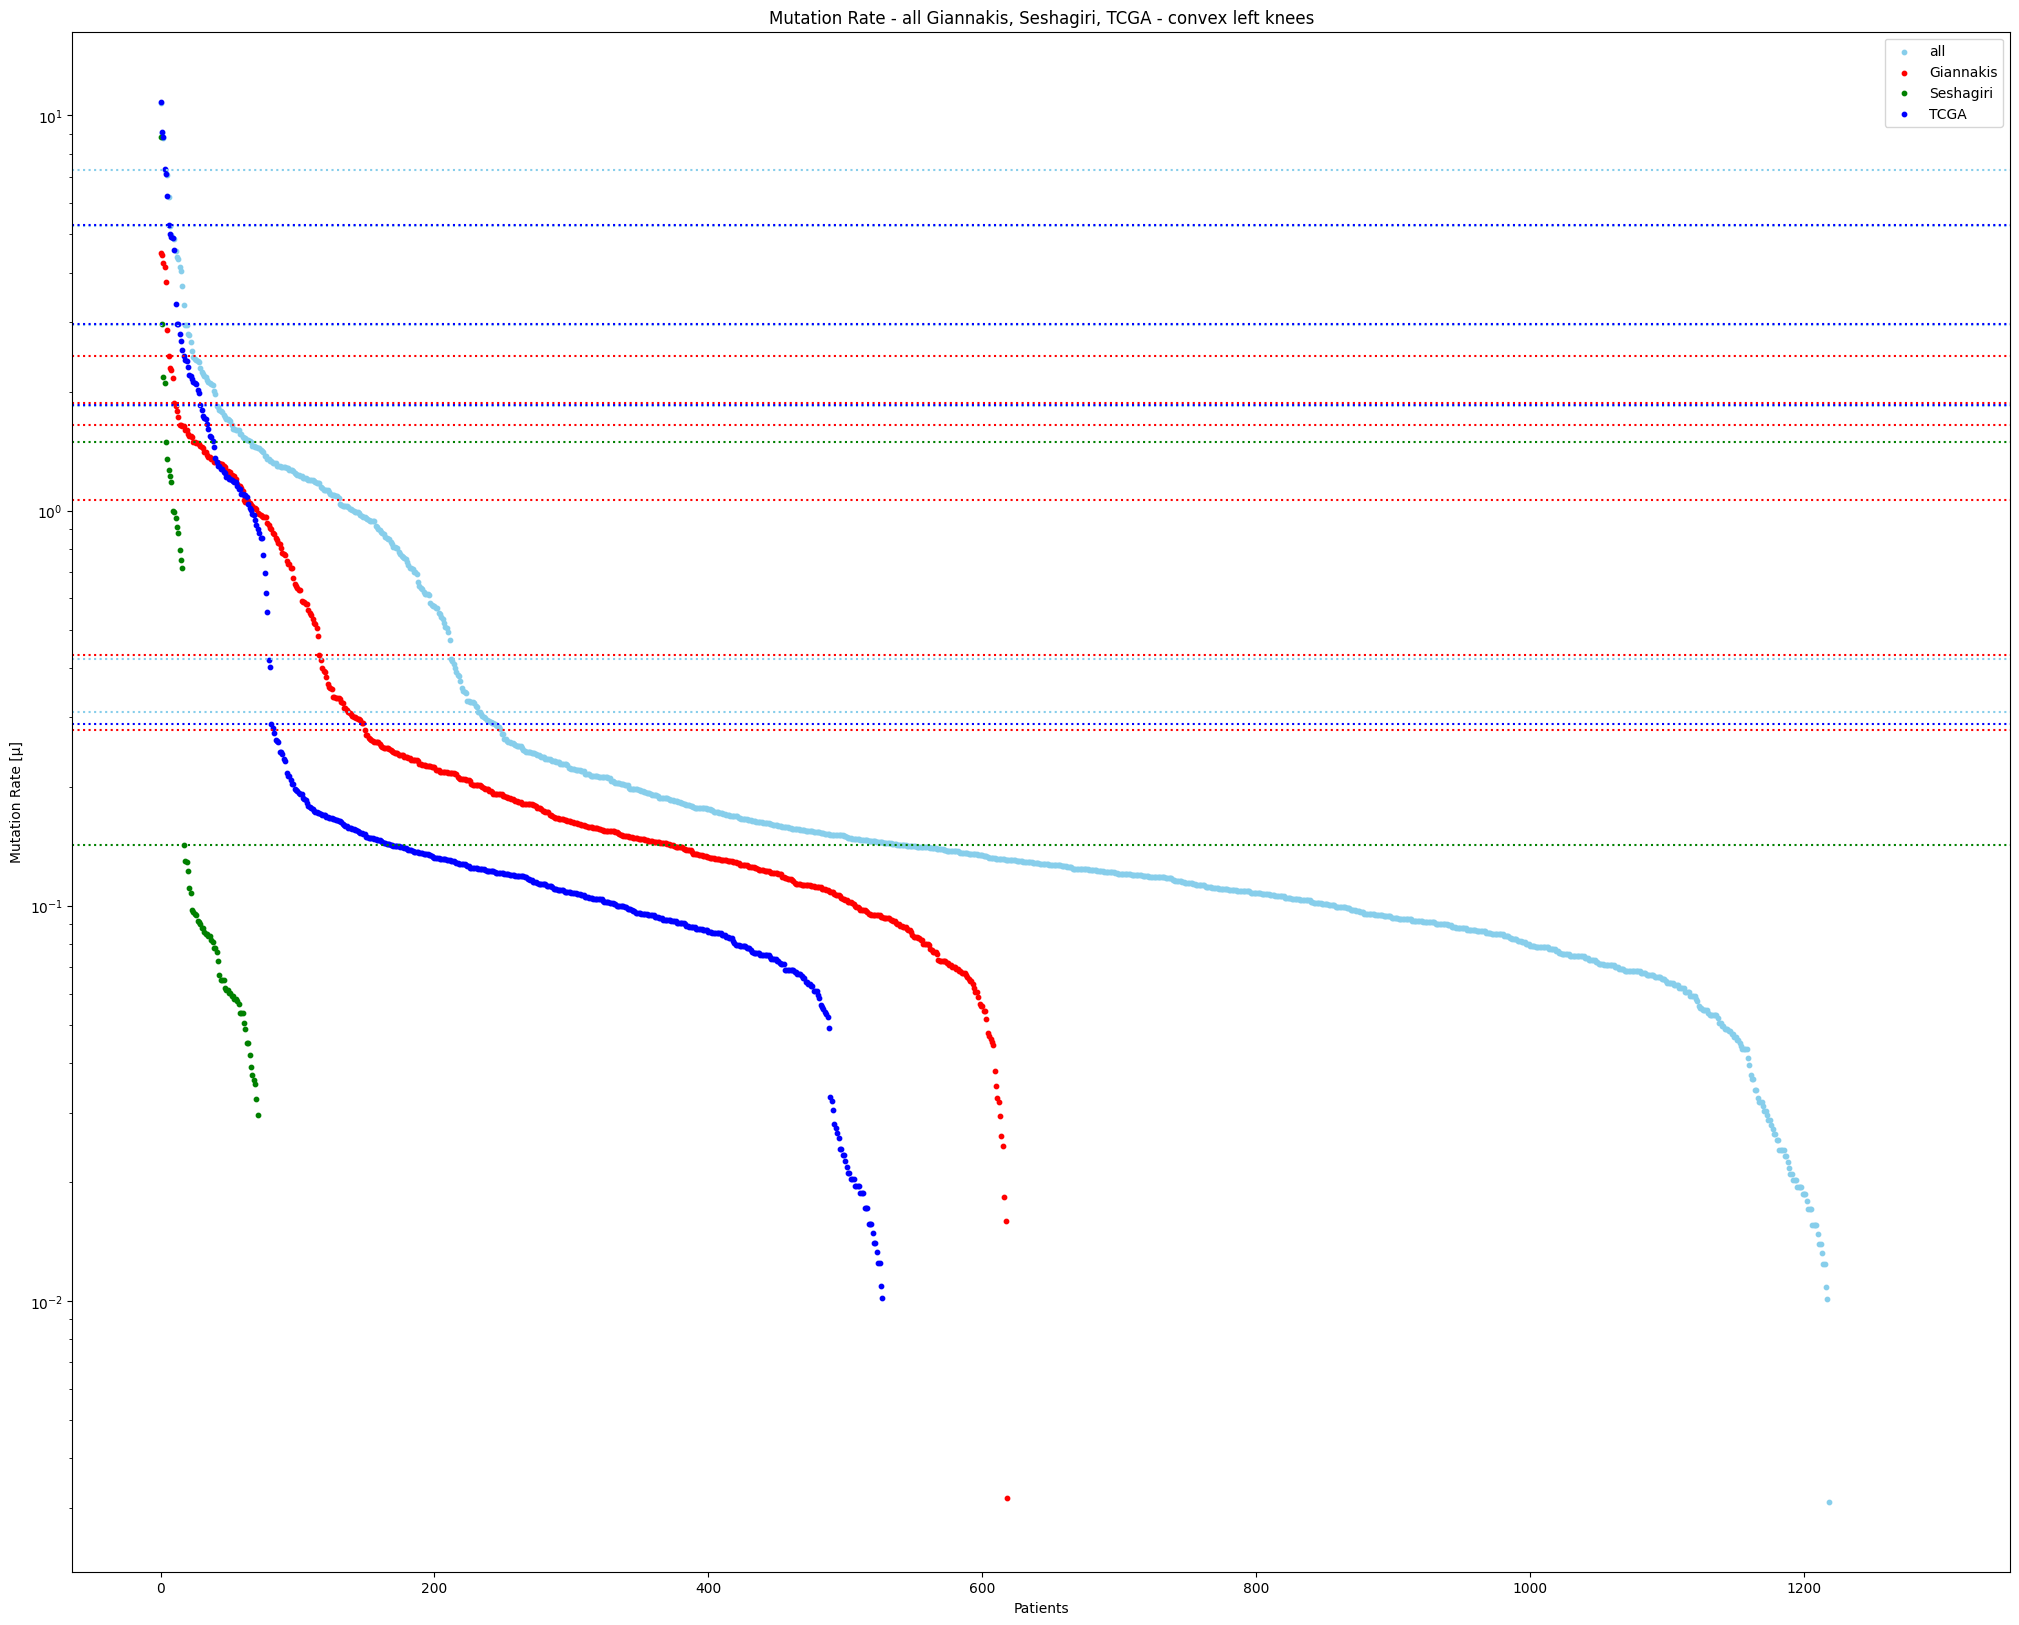

In [29]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all', 'Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - all Giannakis, Seshagiri, TCGA - convex left knees')
plt.savefig(data['hypoHyper_analysis'] + 'all_Giannakis_Seshagiri_TCGA_convexLeftKnees')
plt.show()

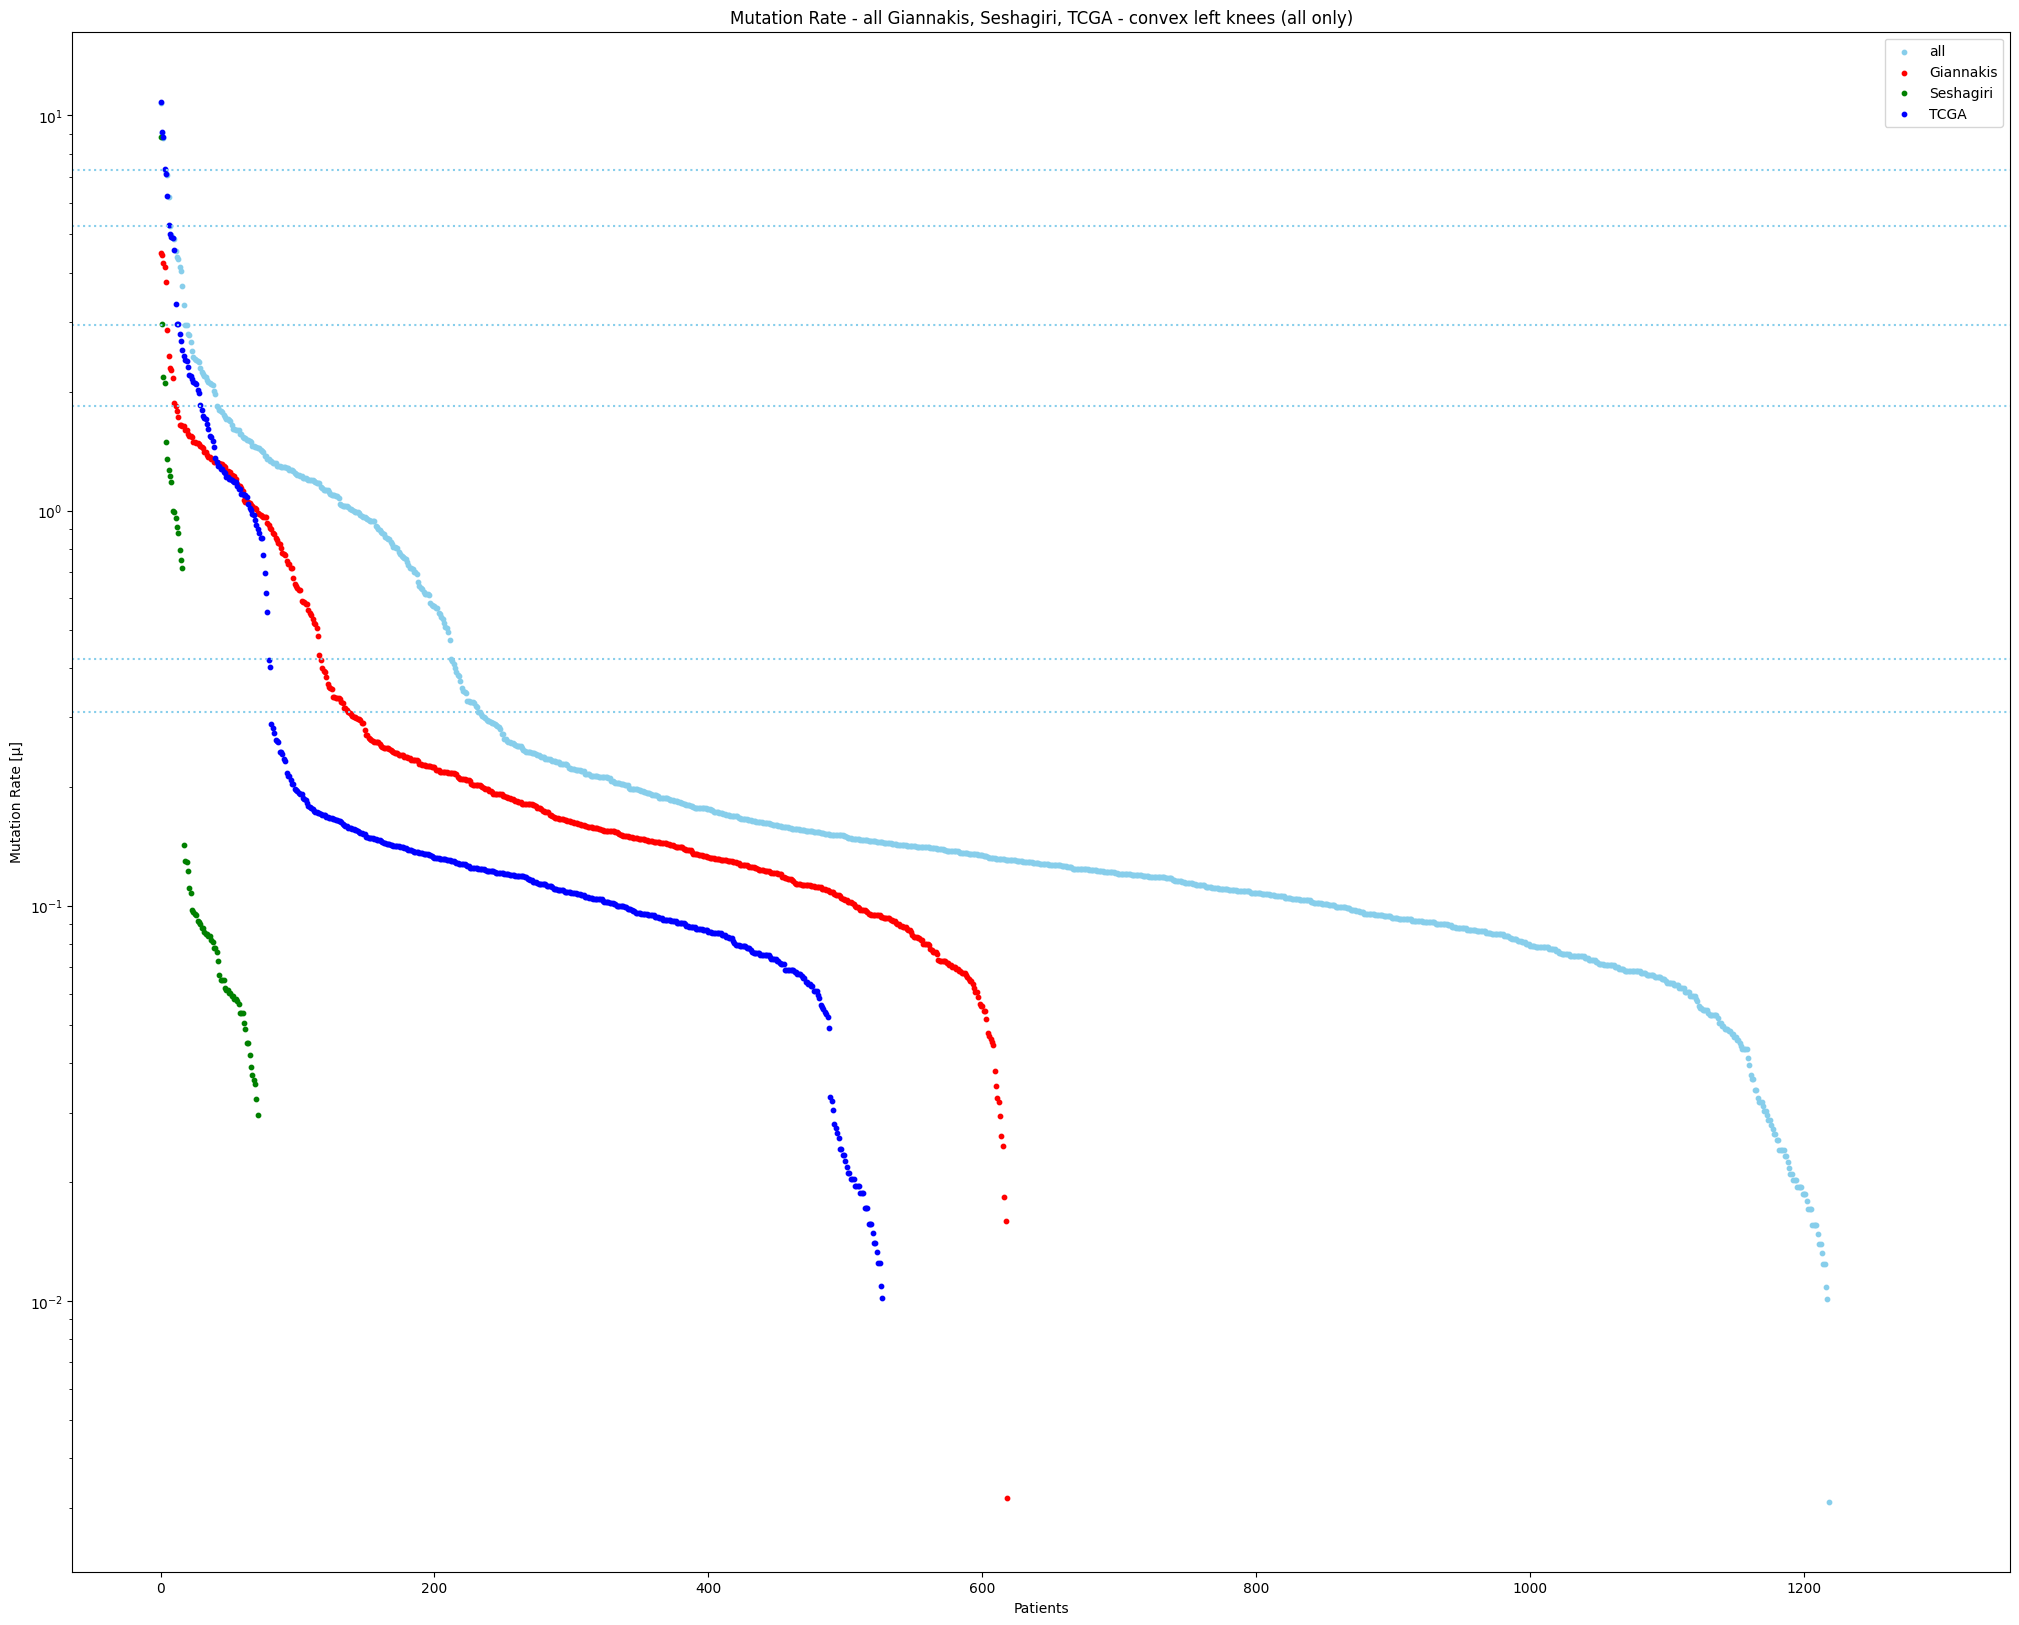

In [30]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all', 'Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - all Giannakis, Seshagiri, TCGA - convex left knees (all only)')
plt.savefig(data['hypoHyper_analysis'] + 'all_Giannakis_Seshagiri_TCGA_convexLeftKneesAllOnly')
plt.show()

## Concave Right Knees

In [31]:
numMutatedBases_perPatient_all.sort_values(by='Mutation_Rate[µ]', ascending=True).reset_index(drop=True)

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ]
0,TCGA-AG-A025,0.0,0.000000,0.000000
1,TCGA-AG-3578,0.0,0.000000,0.000000
2,TCGA-AG-3587,0.0,0.000000,0.000000
3,TCGA-AA-3542,0.0,0.000000,0.000000
4,TCGA-A6-2672,0.0,0.000000,0.000000
...,...,...,...,...
1282,32908,9212.0,0.000007,7.159124
1283,TCGA-AA-A010,9373.0,0.000007,7.284245
1284,TCGA-F5-6814,11290.0,0.000009,8.774046
1285,TCGA-CA-6717,11610.0,0.000009,9.022734


In [32]:
import math
def find_knees2(numMutatedBases_perPatient):
    xs = []
    ys = []
    gaps = []

    gap_max = -1
    dim_start = len(numMutatedBases_perPatient)//100*95
    while(True):
        kl  = KneeLocator(numMutatedBases_perPatient.index[dim_start:], numMutatedBases_perPatient['Mutation_Rate[µ]'].values[dim_start:], curve='concave', direction='decreasing', online=True)
        if kl.knee == None or kl.knee == len(numMutatedBases_perPatient)-1:
            break
        x4 = kl.knee
        x3 = kl.knee - 1
        y4 = kl.knee_y
        y3 = numMutatedBases_perPatient['Mutation_Rate[µ]'].values[x3]
        gap = abs(y4 - y3)
        # if gap > gap_max/10:
        print(str(x4) + '   -   ' + str(y4))
        gap_max = gap
        x_max = x4
        xs.append(x4)
        ys.append(y4)
        gaps.append(gap)
        #----
        dim_start = x4+1
    return xs, ys, gaps

In [33]:
print('all')
xs_all, ys_all, gaps_all = find_knees2(numMutatedBases_perPatient_all)
print('Giannakis')
xs_Giannakis, ys_Giannakis, gaps_Giannakis = find_knees2(numMutatedBases_perPatient_Giannakis)
print('Seshagiri')
xs_Seshagiri, ys_Seshagiri, gaps_Seshagiri = find_knees2(numMutatedBases_perPatient_Seshagiri)
print('TCGA')
xs_TCGA, ys_TCGA, gaps_TCGA = find_knees2(numMutatedBases_perPatient_TCGA)

all
1141   -   0.04973772589925035
1144   -   0.048960573932074564
1146   -   0.04818342196489878
1158   -   0.04352051016184406
1163   -   0.03652614245726198
1165   -   0.03419468655573462
1169   -   0.03186323065420726
1172   -   0.030308926719855682
1175   -   0.02875462278550411
1179   -   0.02642316688397675
1185   -   0.02409171098244939
1187   -   0.0233145590152736
1191   -   0.02098310311374624
1194   -   0.020205951146570457
1198   -   0.01942879917939467
1201   -   0.01865164721221888
1205   -   0.01709734327786731
1209   -   0.015543039343515735
1215   -   0.012434431474812588
Giannakis
593   -   0.0636326205776158
603   -   0.05170150421931283
608   -   0.04454283440433106
615   -   0.024657640473826122
Seshagiri
3   -   2.097960338299708
10   -   0.9921106292278347
71   -   0.029629508194665578
TCGA
479   -   0.06097351896307396
497   -   0.02423306522891401
499   -   0.023451353447336138
503   -   0.021106218102602523
506   -   0.020324506321024654
510   -   0.019542794

/home/axel/.local/lib/python3.12/site-packages/kneed/knee_locator.py:225: RuntimeWarning: invalid value encountered in divide
  return (a - min(a)) / (max(a) - min(a))


In [34]:
# put xs, ys, and gaps in df
knees_ConcaveRight_all = pd.DataFrame({'x': xs_all, 'y': ys_all, 'gap': gaps_all})
knees_ConcaveRight_Giannakis = pd.DataFrame({'x': xs_Giannakis, 'y': ys_Giannakis, 'gap': gaps_Giannakis})
knees_ConcaveRight_Seshagiri = pd.DataFrame({'x': xs_Seshagiri, 'y': ys_Seshagiri, 'gap': gaps_Seshagiri})
knees_ConcaveRight_TCGA = pd.DataFrame({'x': xs_TCGA, 'y': ys_TCGA, 'gap': gaps_TCGA})

In [35]:
# add number of giannakis patient with mut rate above y to df
knees_ConcaveRight_all['#all'] = knees_ConcaveRight_all.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_all['#giannakis'] = knees_ConcaveRight_all.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_all['#seshagiri'] = knees_ConcaveRight_all.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_all['#TCGA'] = knees_ConcaveRight_all.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] < row['y']), axis=1)

knees_ConcaveRight_Giannakis['#all'] = knees_ConcaveRight_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Giannakis['#giannakis'] = knees_ConcaveRight_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Giannakis['#seshagiri'] = knees_ConcaveRight_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Giannakis['#TCGA'] = knees_ConcaveRight_Giannakis.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] <row['y']), axis=1)

knees_ConcaveRight_Seshagiri['#all'] = knees_ConcaveRight_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Seshagiri['#giannakis'] = knees_ConcaveRight_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Seshagiri['#seshagiri'] = knees_ConcaveRight_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_Seshagiri['#TCGA'] = knees_ConcaveRight_Seshagiri.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] < row['y']), axis=1)

knees_ConcaveRight_TCGA['#all'] = knees_ConcaveRight_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_all['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_TCGA['#giannakis'] = knees_ConcaveRight_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_TCGA['#seshagiri'] = knees_ConcaveRight_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'] < row['y']), axis=1)
knees_ConcaveRight_TCGA['#TCGA'] = knees_ConcaveRight_TCGA.apply(lambda row: np.sum(numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'] < row['y']), axis=1)

In [36]:
# save them
knees_ConcaveRight_all.to_csv(data['hypoHyper_analysis'] + 'knees_ConcaveRight_all.csv', index=False)
knees_ConcaveRight_Giannakis.to_csv(data['hypoHyper_analysis'] + 'knees_ConcaveRight_Giannakis.csv', index=False)
knees_ConcaveRight_Seshagiri.to_csv(data['hypoHyper_analysis'] + 'knees_ConcaveRight_Seshagiri.csv', index=False)
knees_ConcaveRight_TCGA.to_csv(data['hypoHyper_analysis'] + 'knees_ConcaveRight_TCGA.csv', index=False)

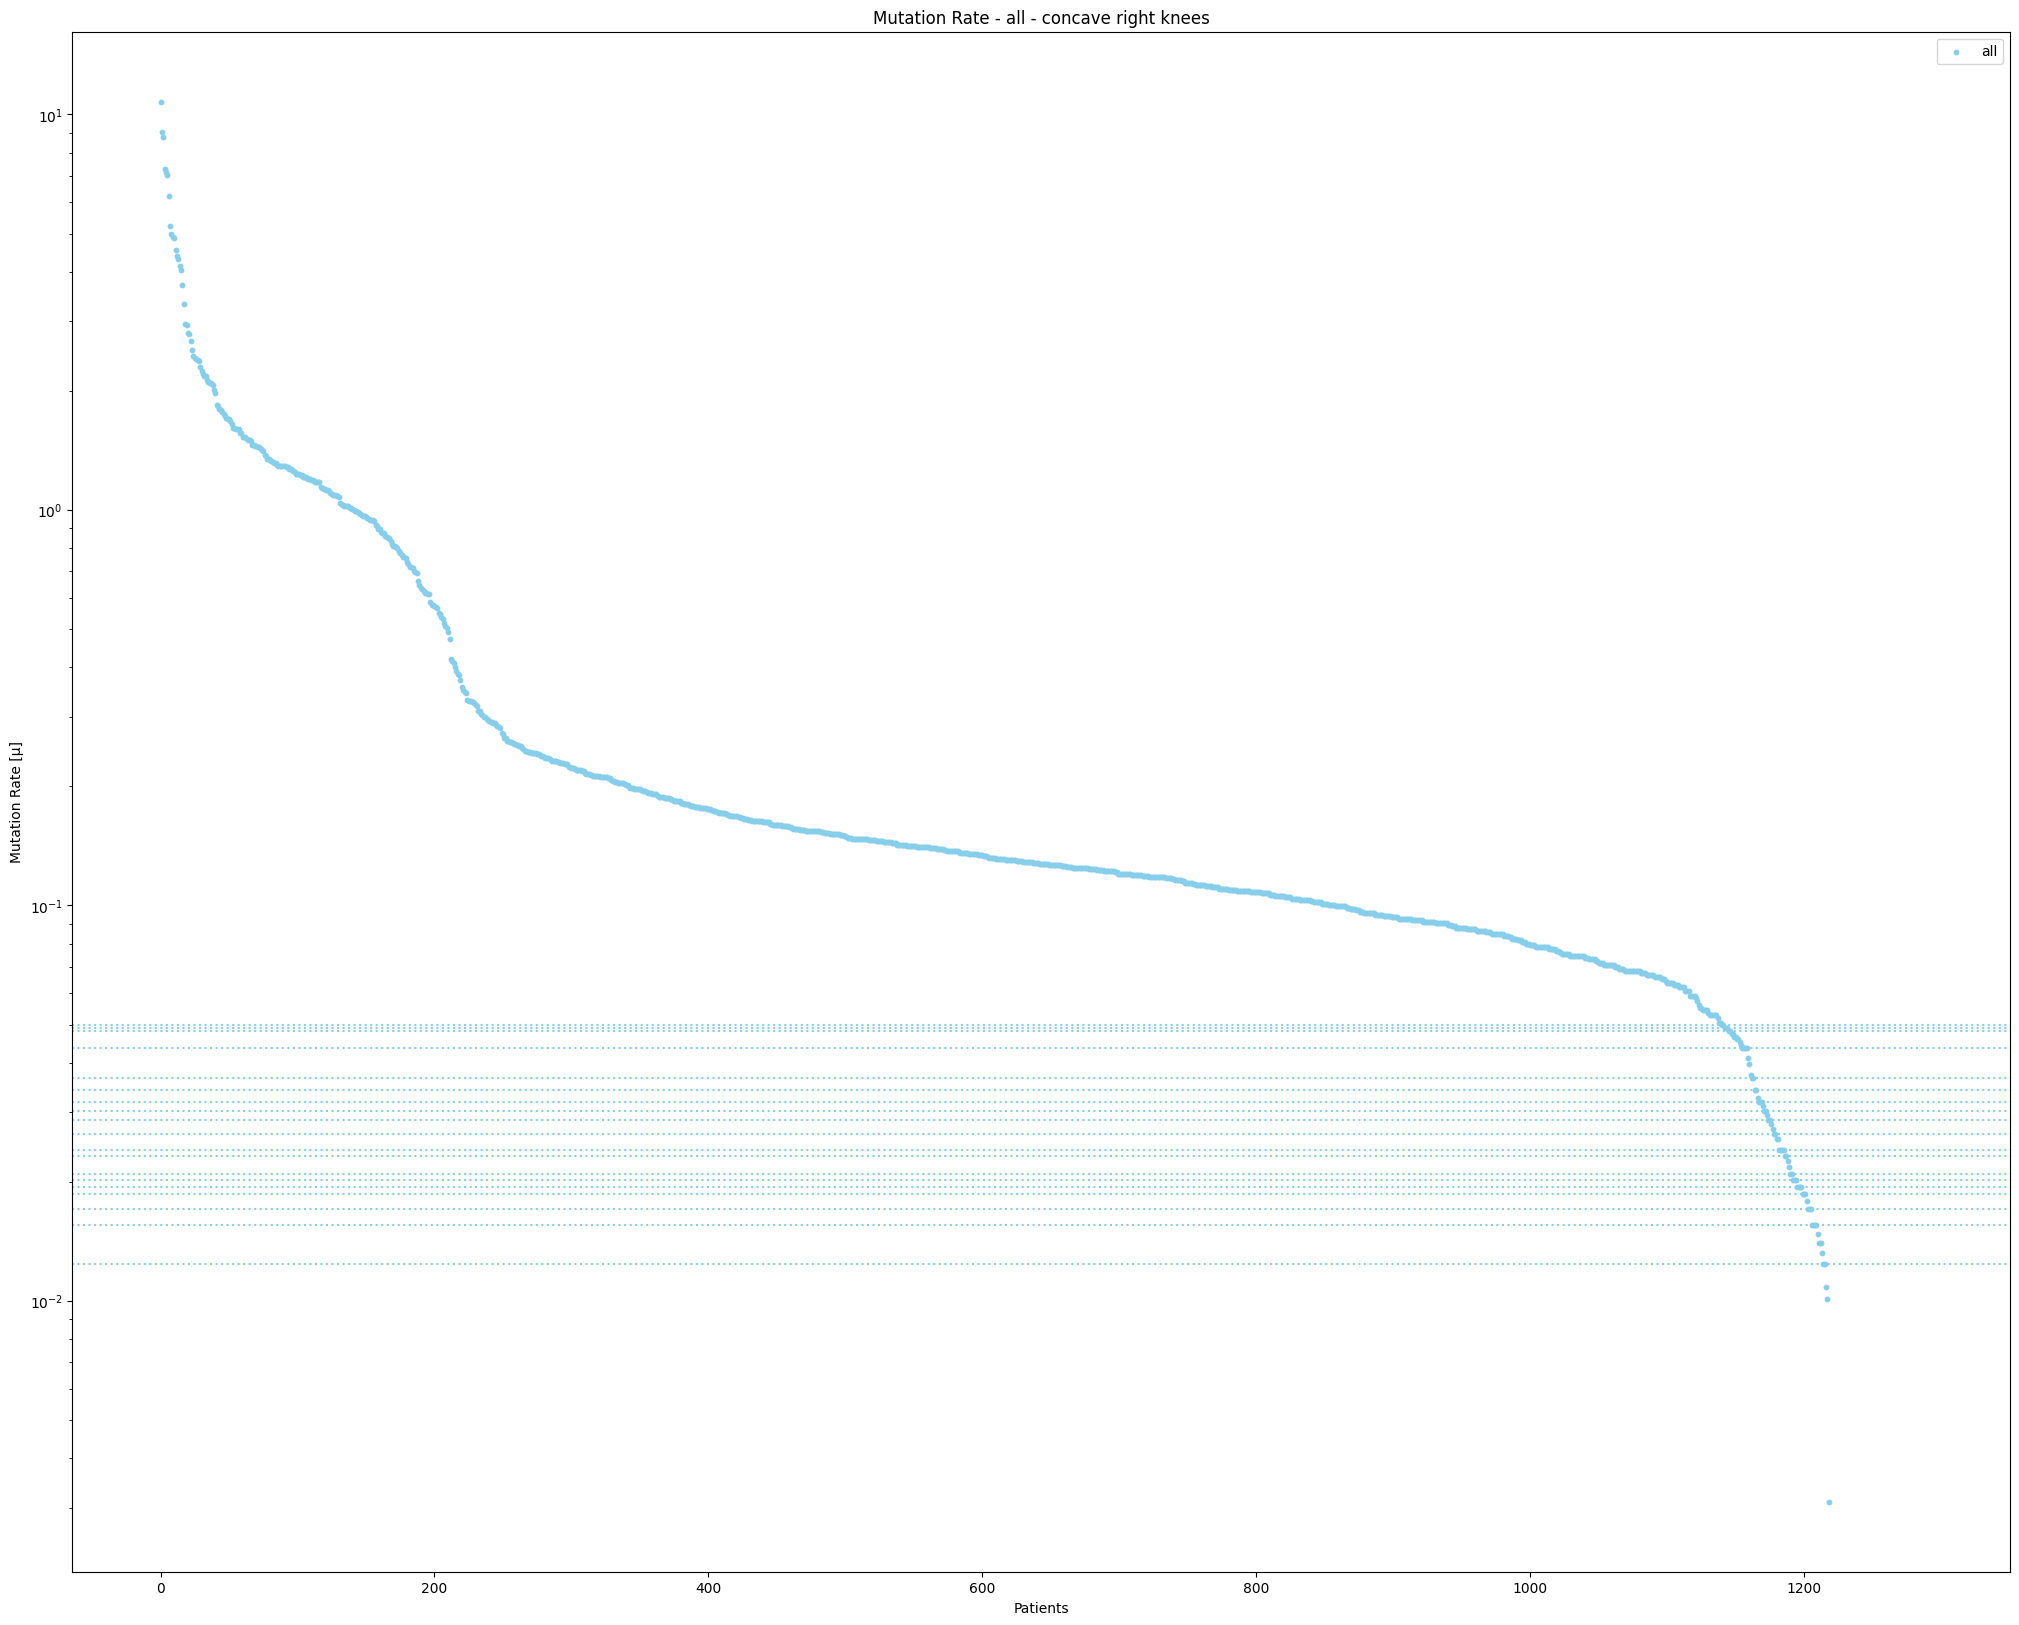

In [37]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all'])
plt.title('Mutation Rate - all - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'all_concaveRightKnees')
plt.show()

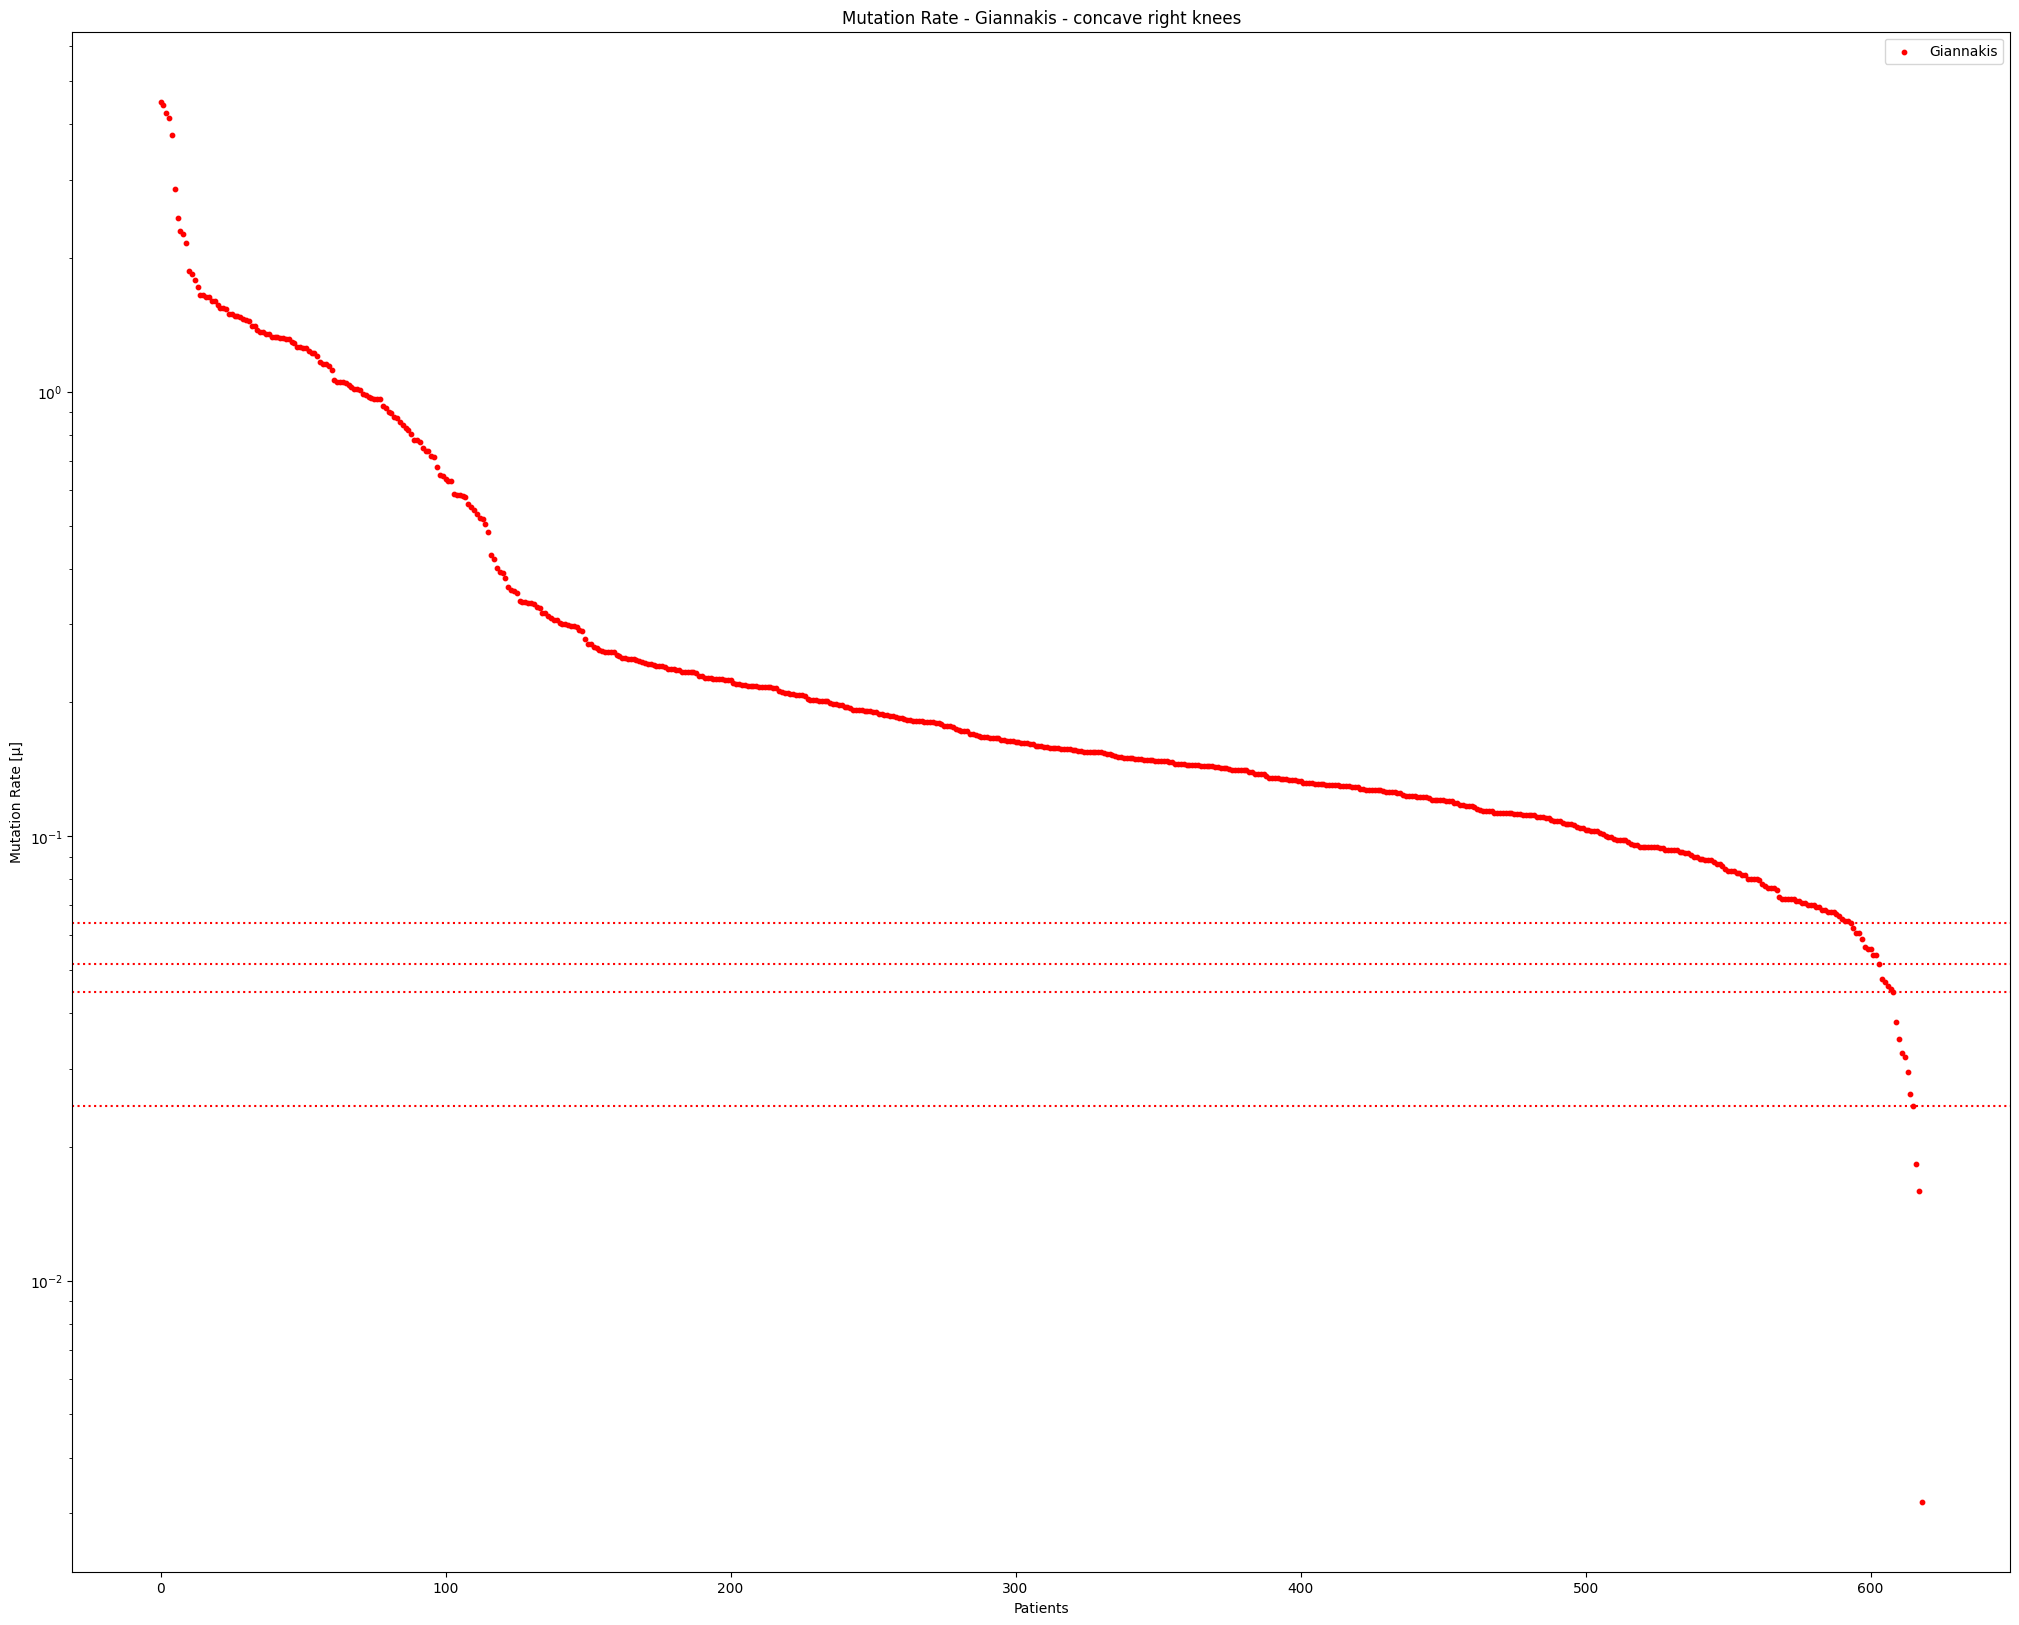

In [38]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis'])
plt.title('Mutation Rate - Giannakis - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_concaveRightKnees')
plt.show()

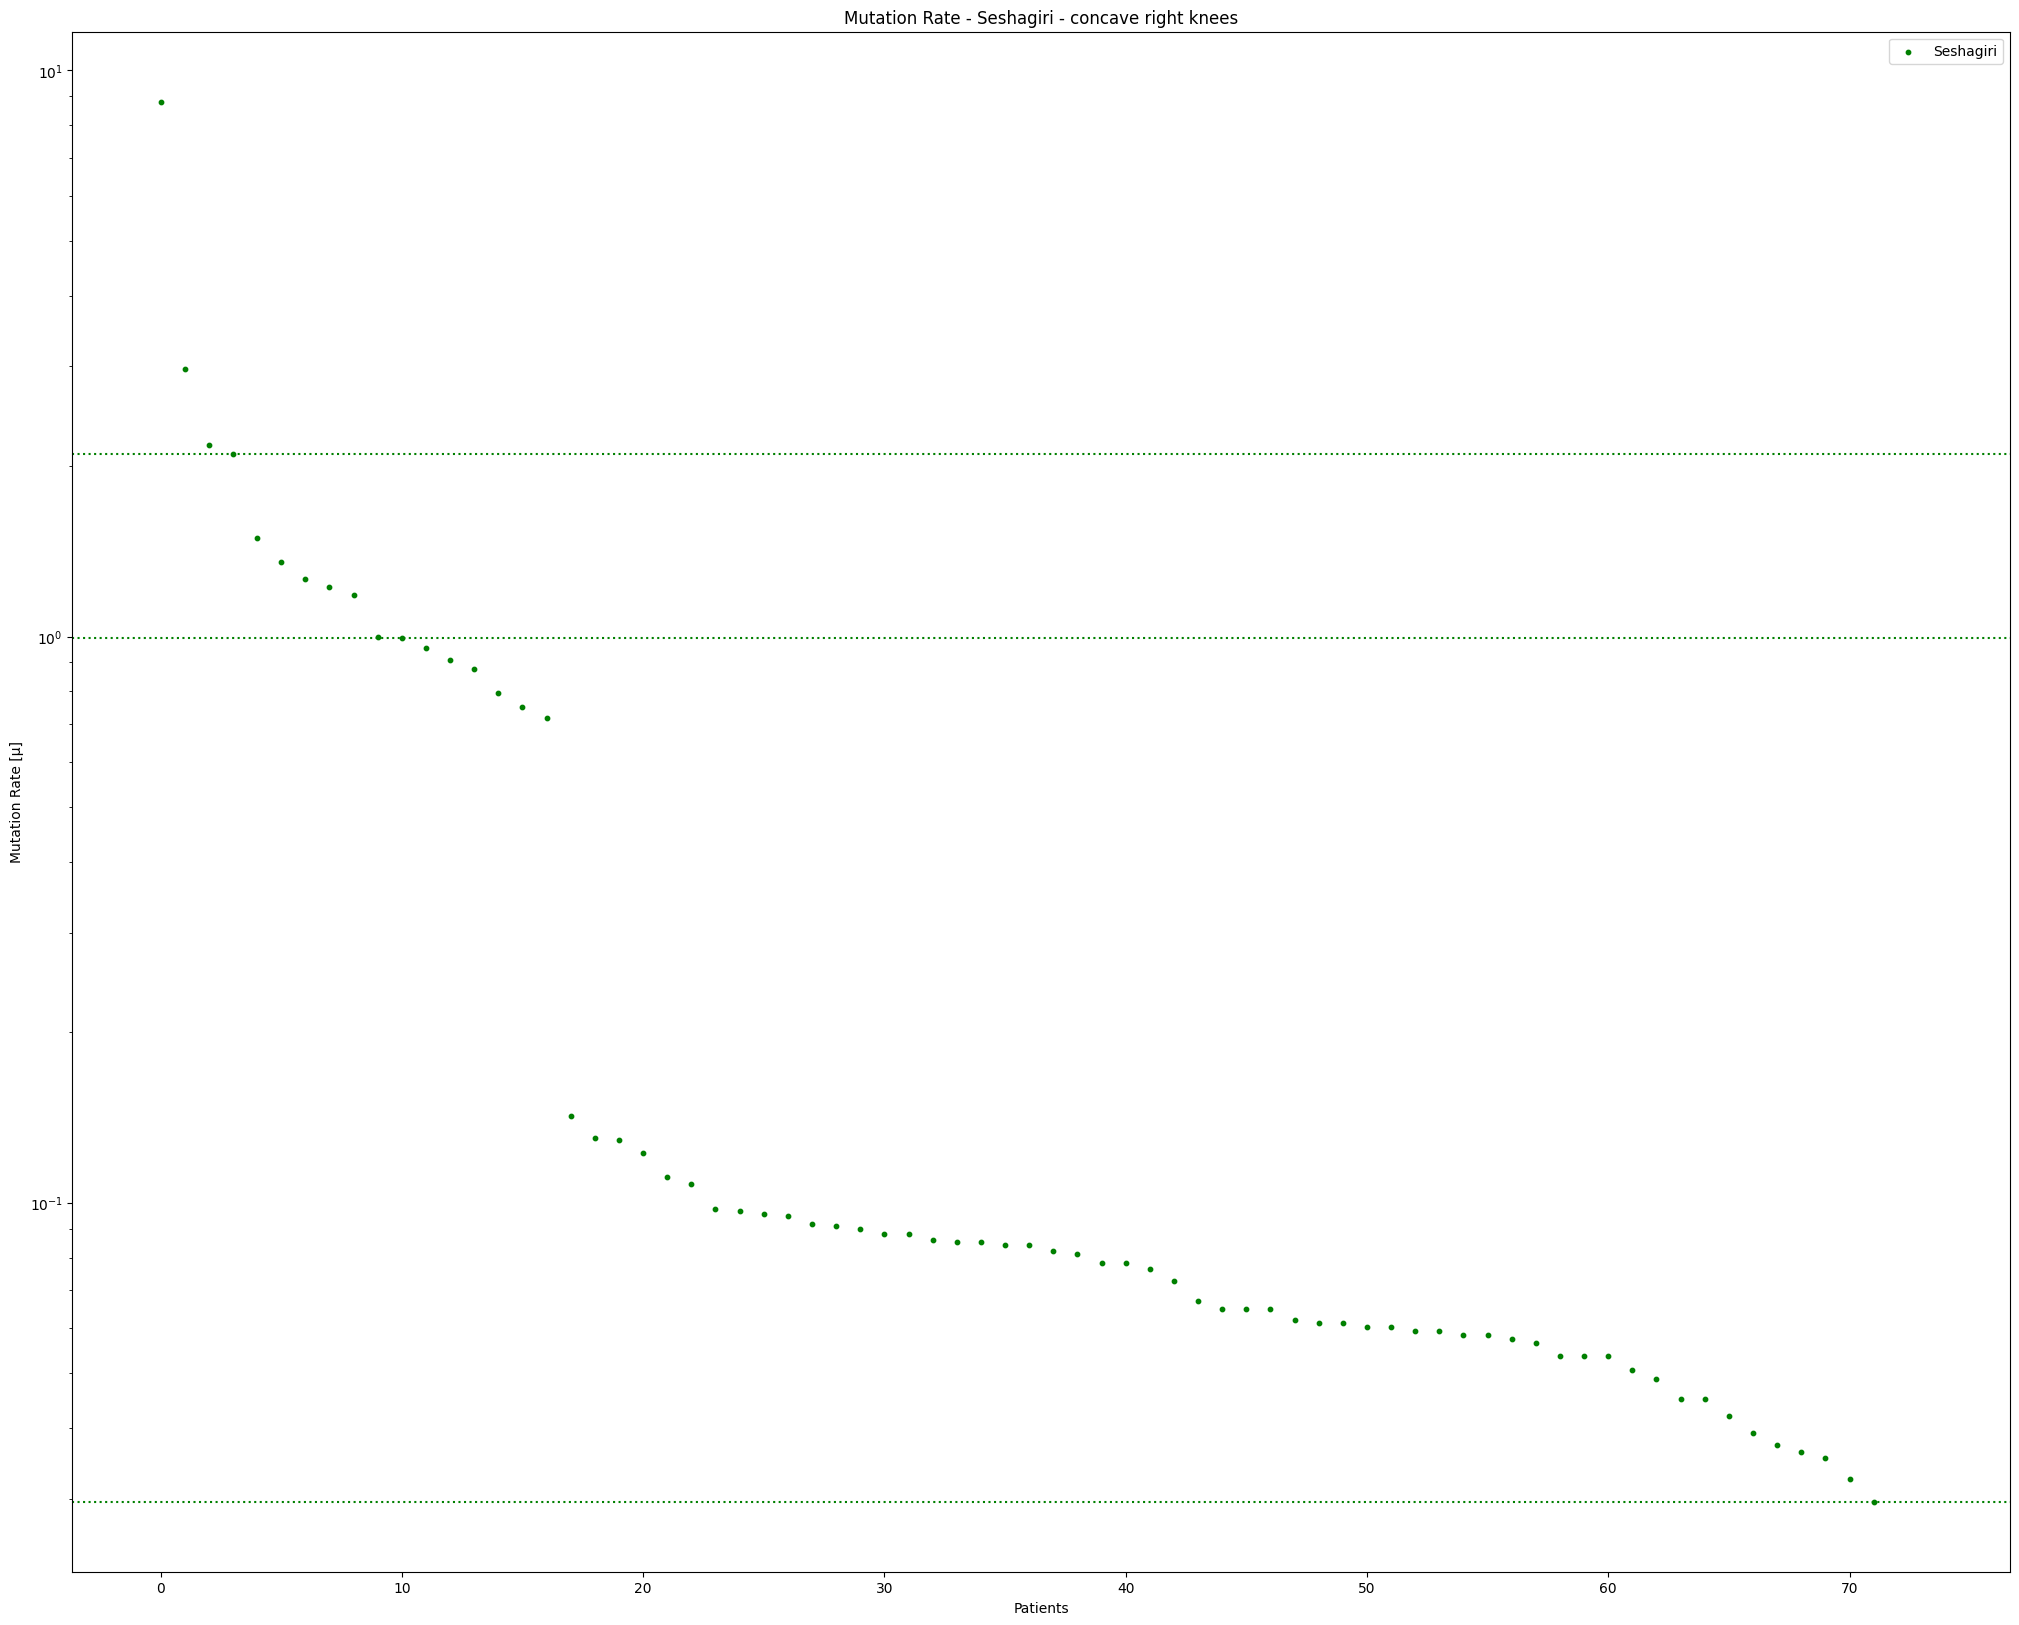

In [39]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Seshagiri'])
plt.title('Mutation Rate - Seshagiri - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'Seshagiri_concaveRightKnees')
plt.show()

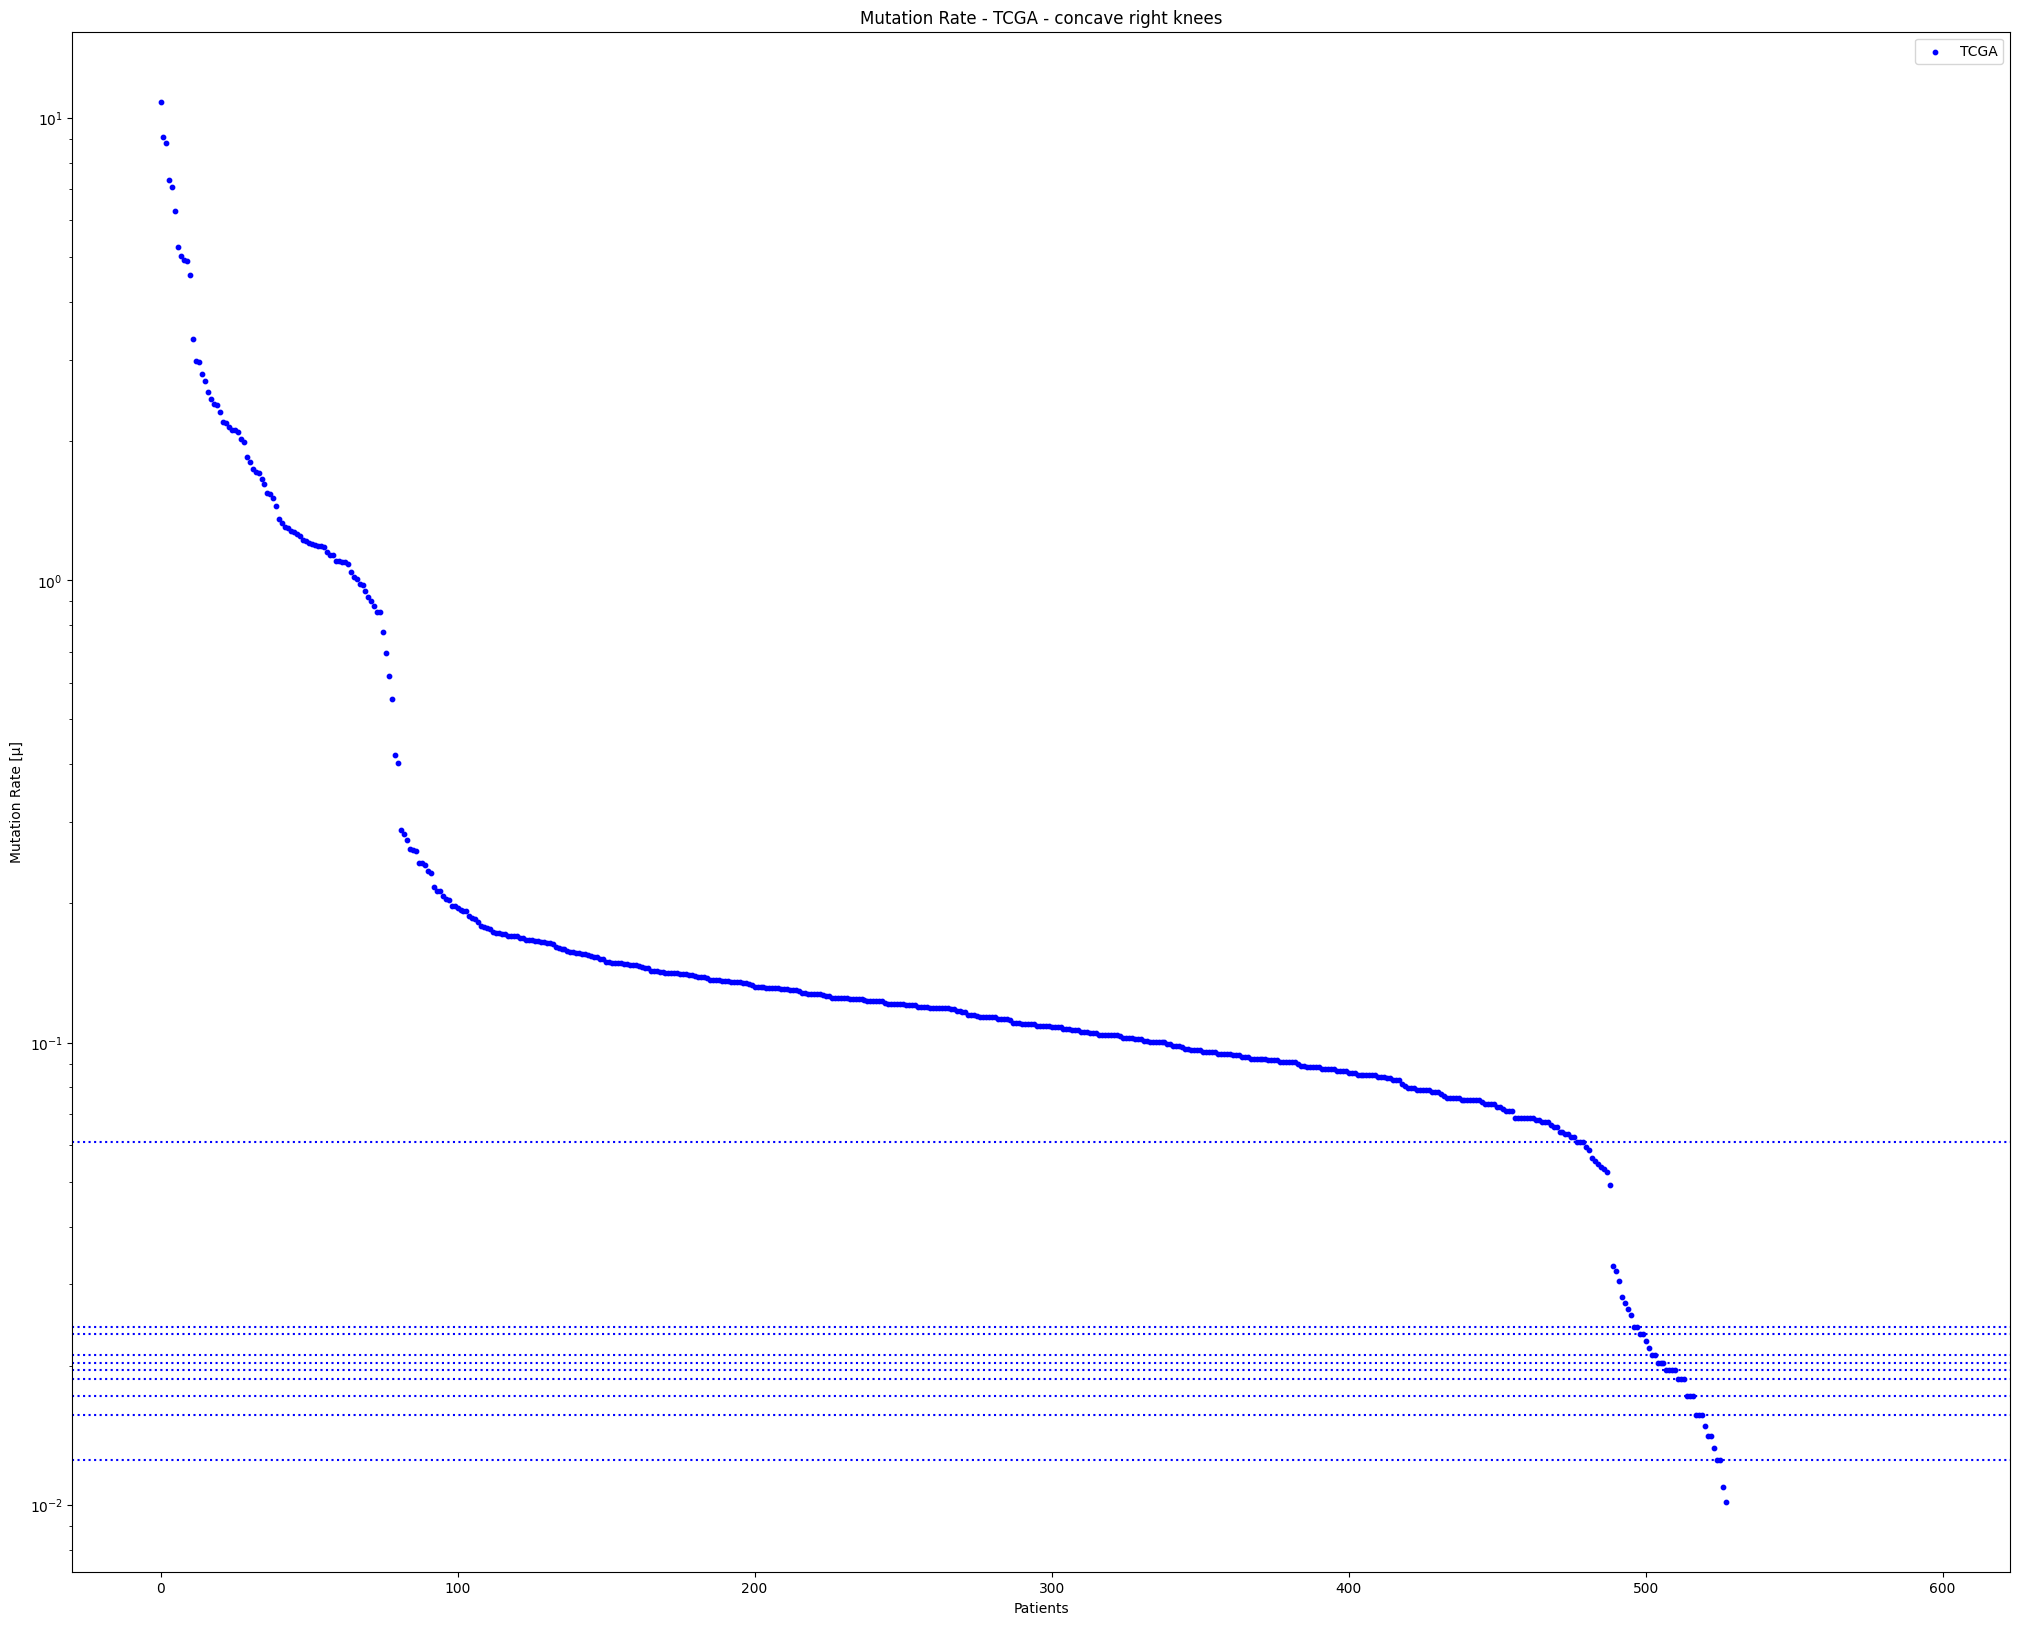

In [40]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['TCGA'])
plt.title('Mutation Rate - TCGA - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'TCGA_concaveRightKnees')
plt.show()

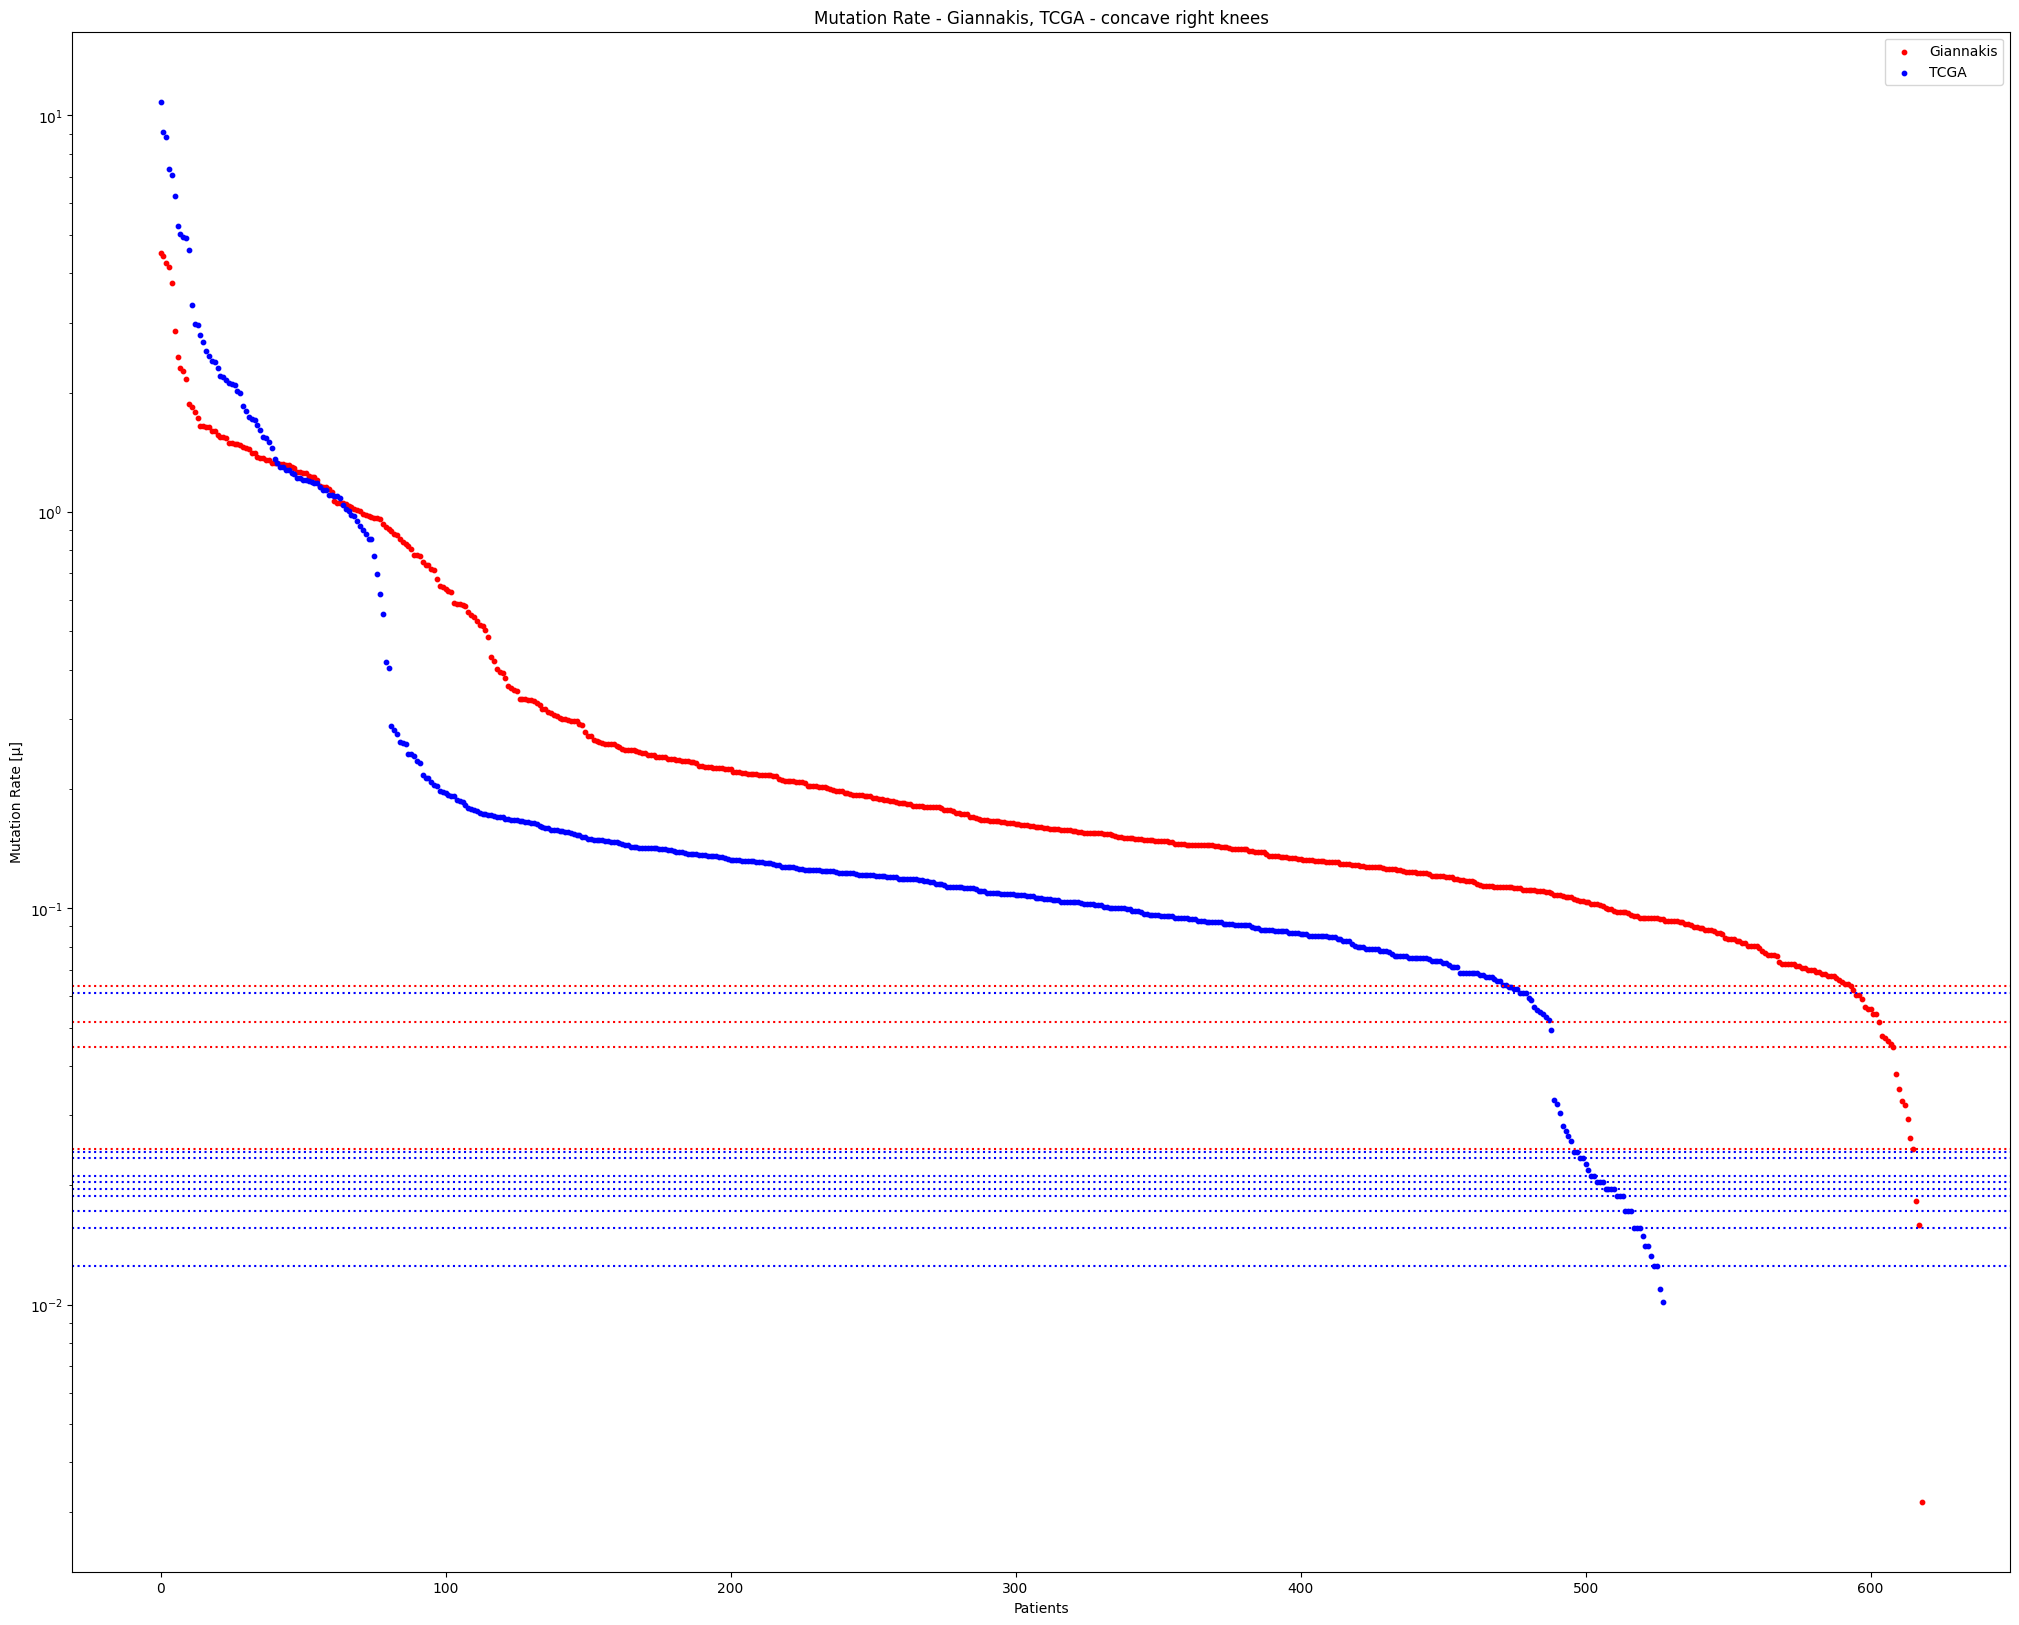

In [41]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis', 'TCGA'])
plt.title('Mutation Rate - Giannakis, TCGA - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_TCGA_concaveRightKnees')
plt.show()

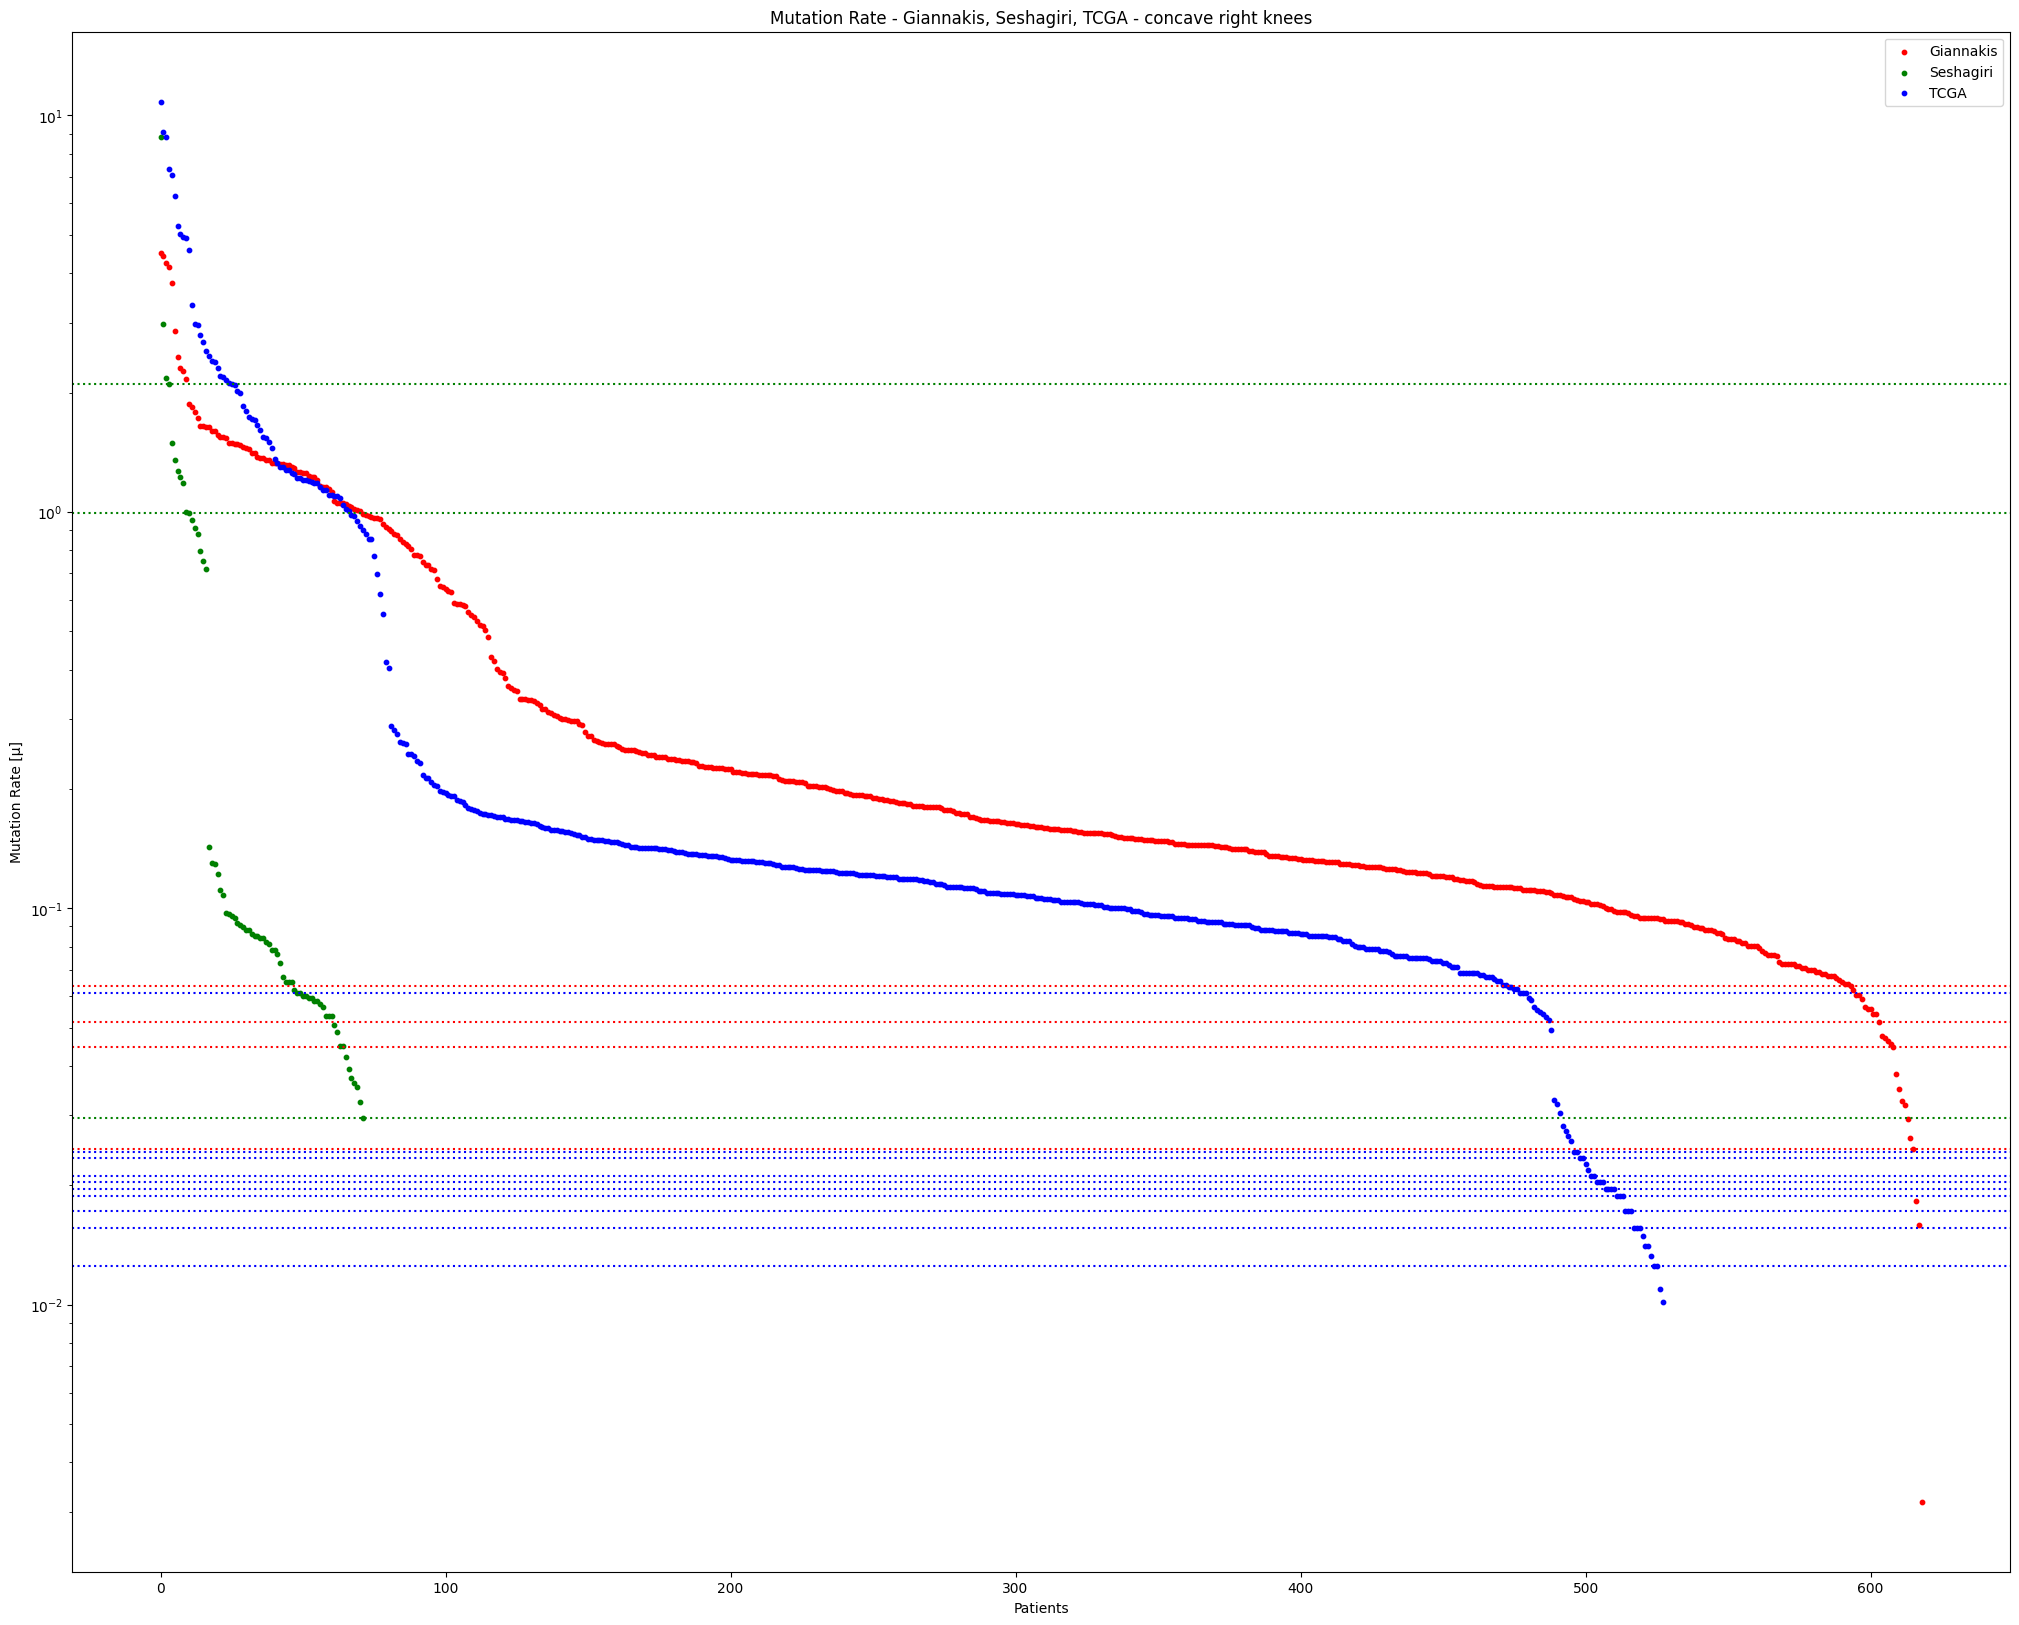

In [42]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - Giannakis, Seshagiri, TCGA - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'Giannakis_Seshagiri_TCGA_concaveRightKnees')
plt.show()

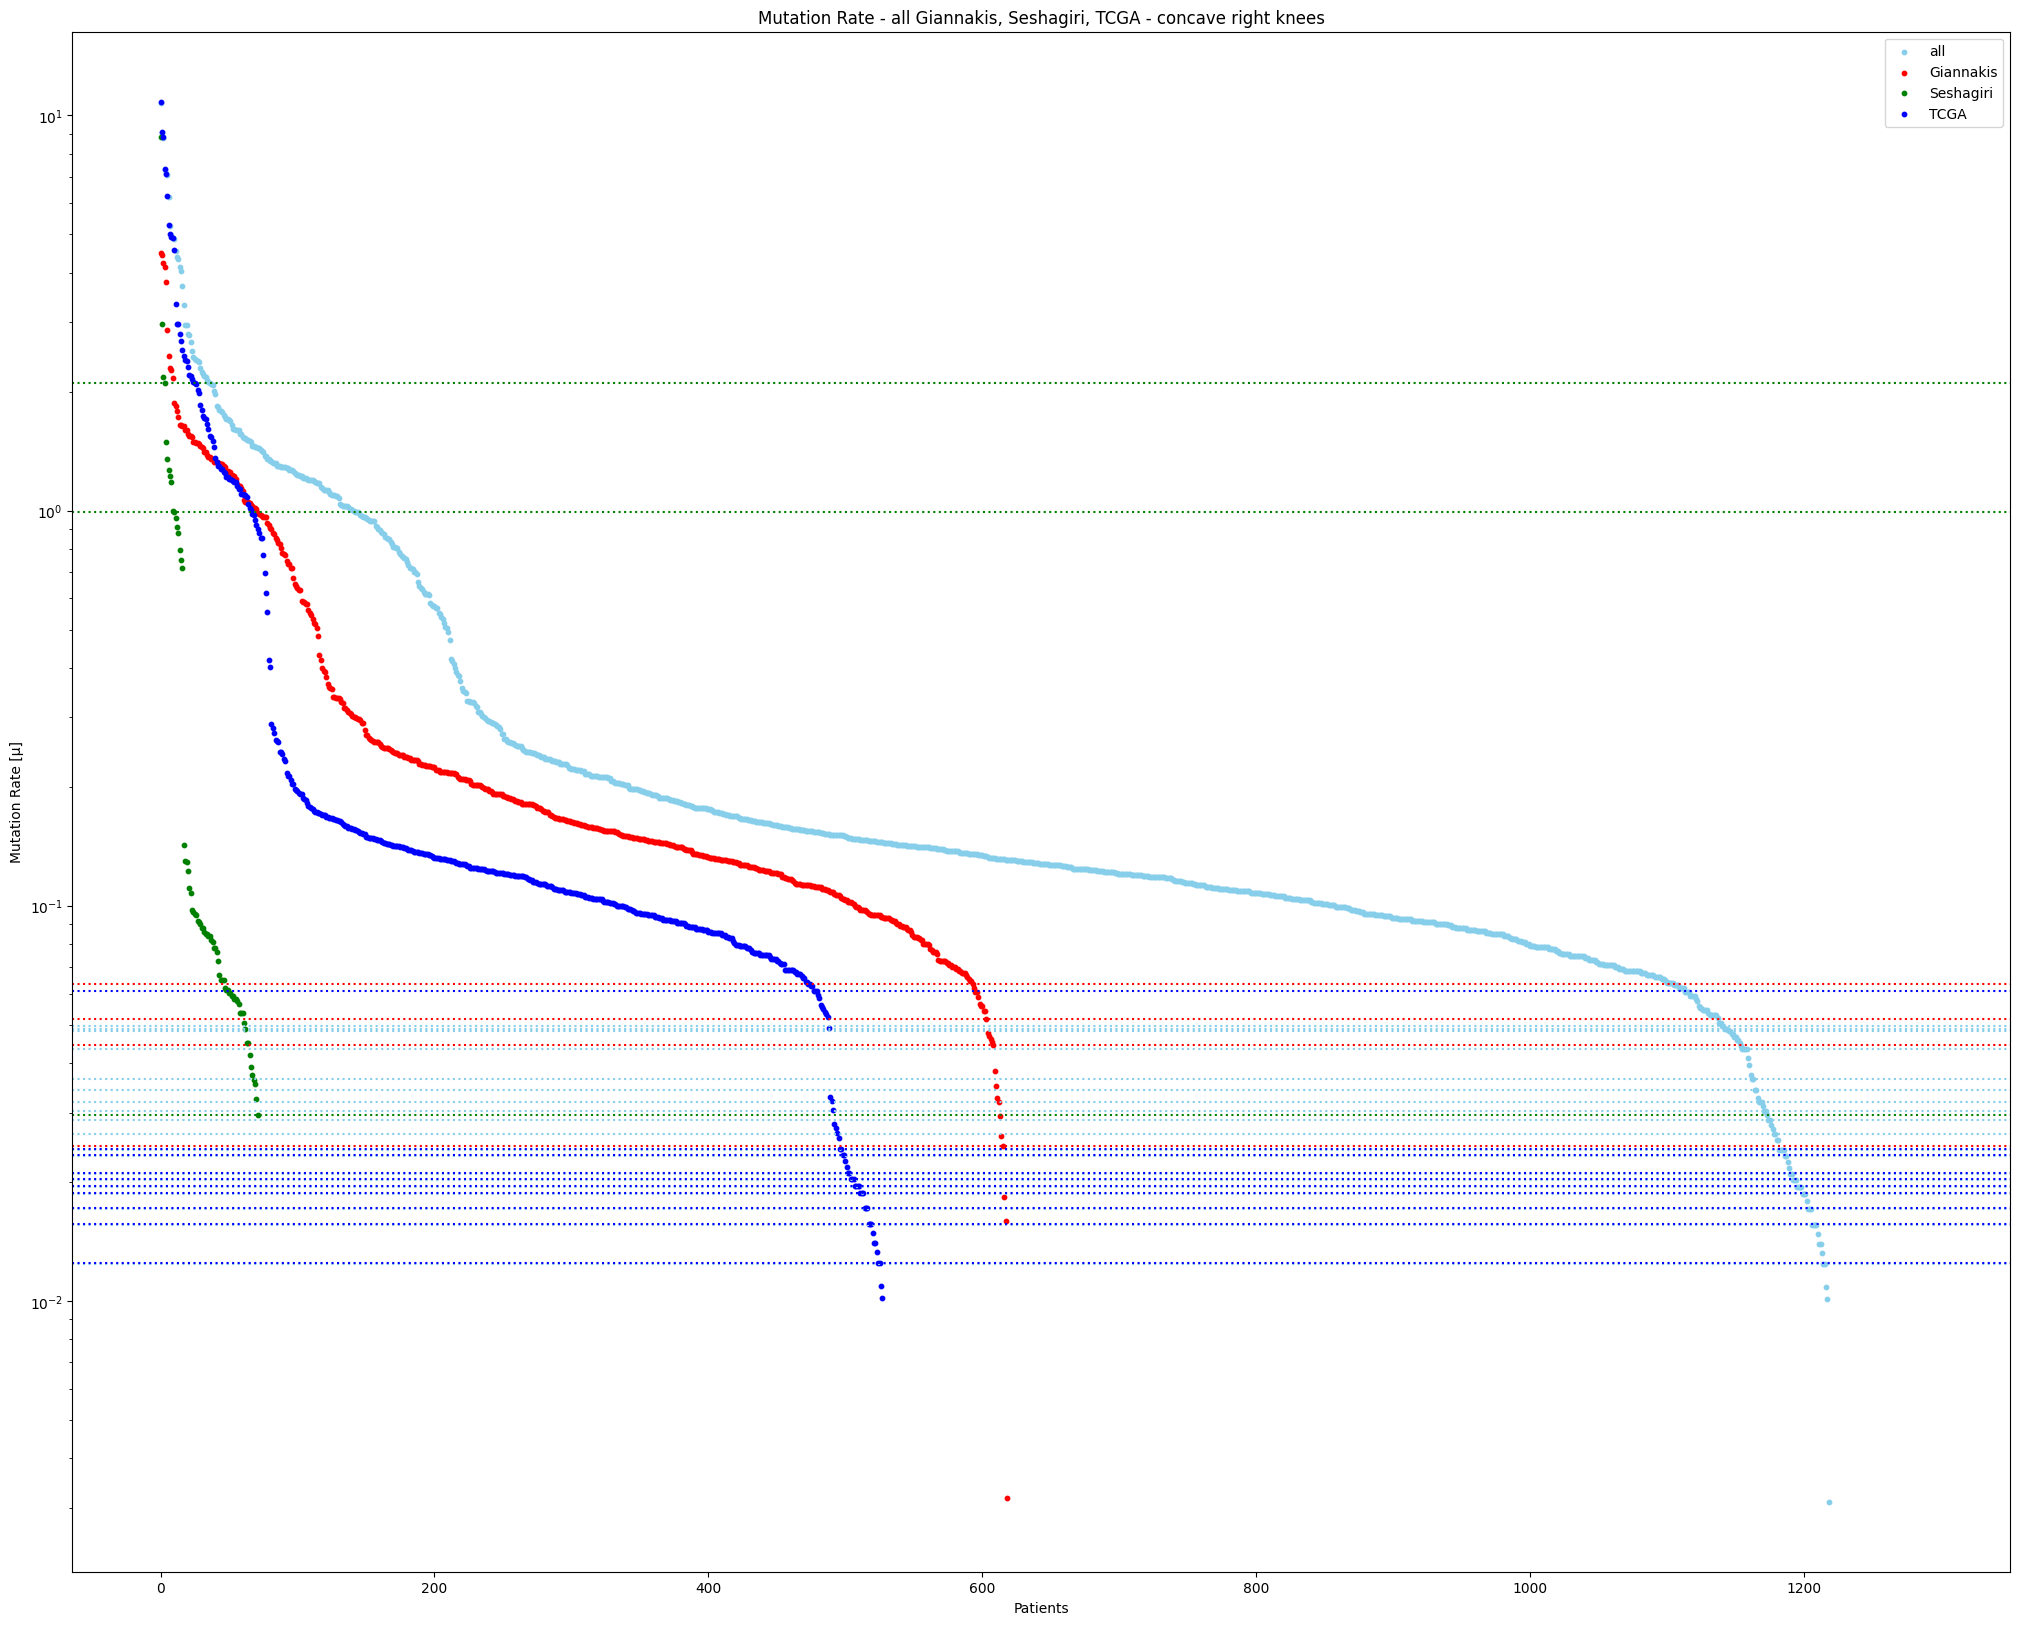

In [43]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
for y in ys_Giannakis:
    plt.axhline(y=y, color='red', linestyle=':')
for y in ys_Seshagiri:
    plt.axhline(y=y, color='green', linestyle=':')
for y in ys_TCGA:
    plt.axhline(y=y, color='blue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all', 'Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - all Giannakis, Seshagiri, TCGA - concave right knees')
plt.savefig(data['hypoHyper_analysis'] + 'all_Giannakis_Seshagiri_TCGA_concaveRightKnees')
plt.show()

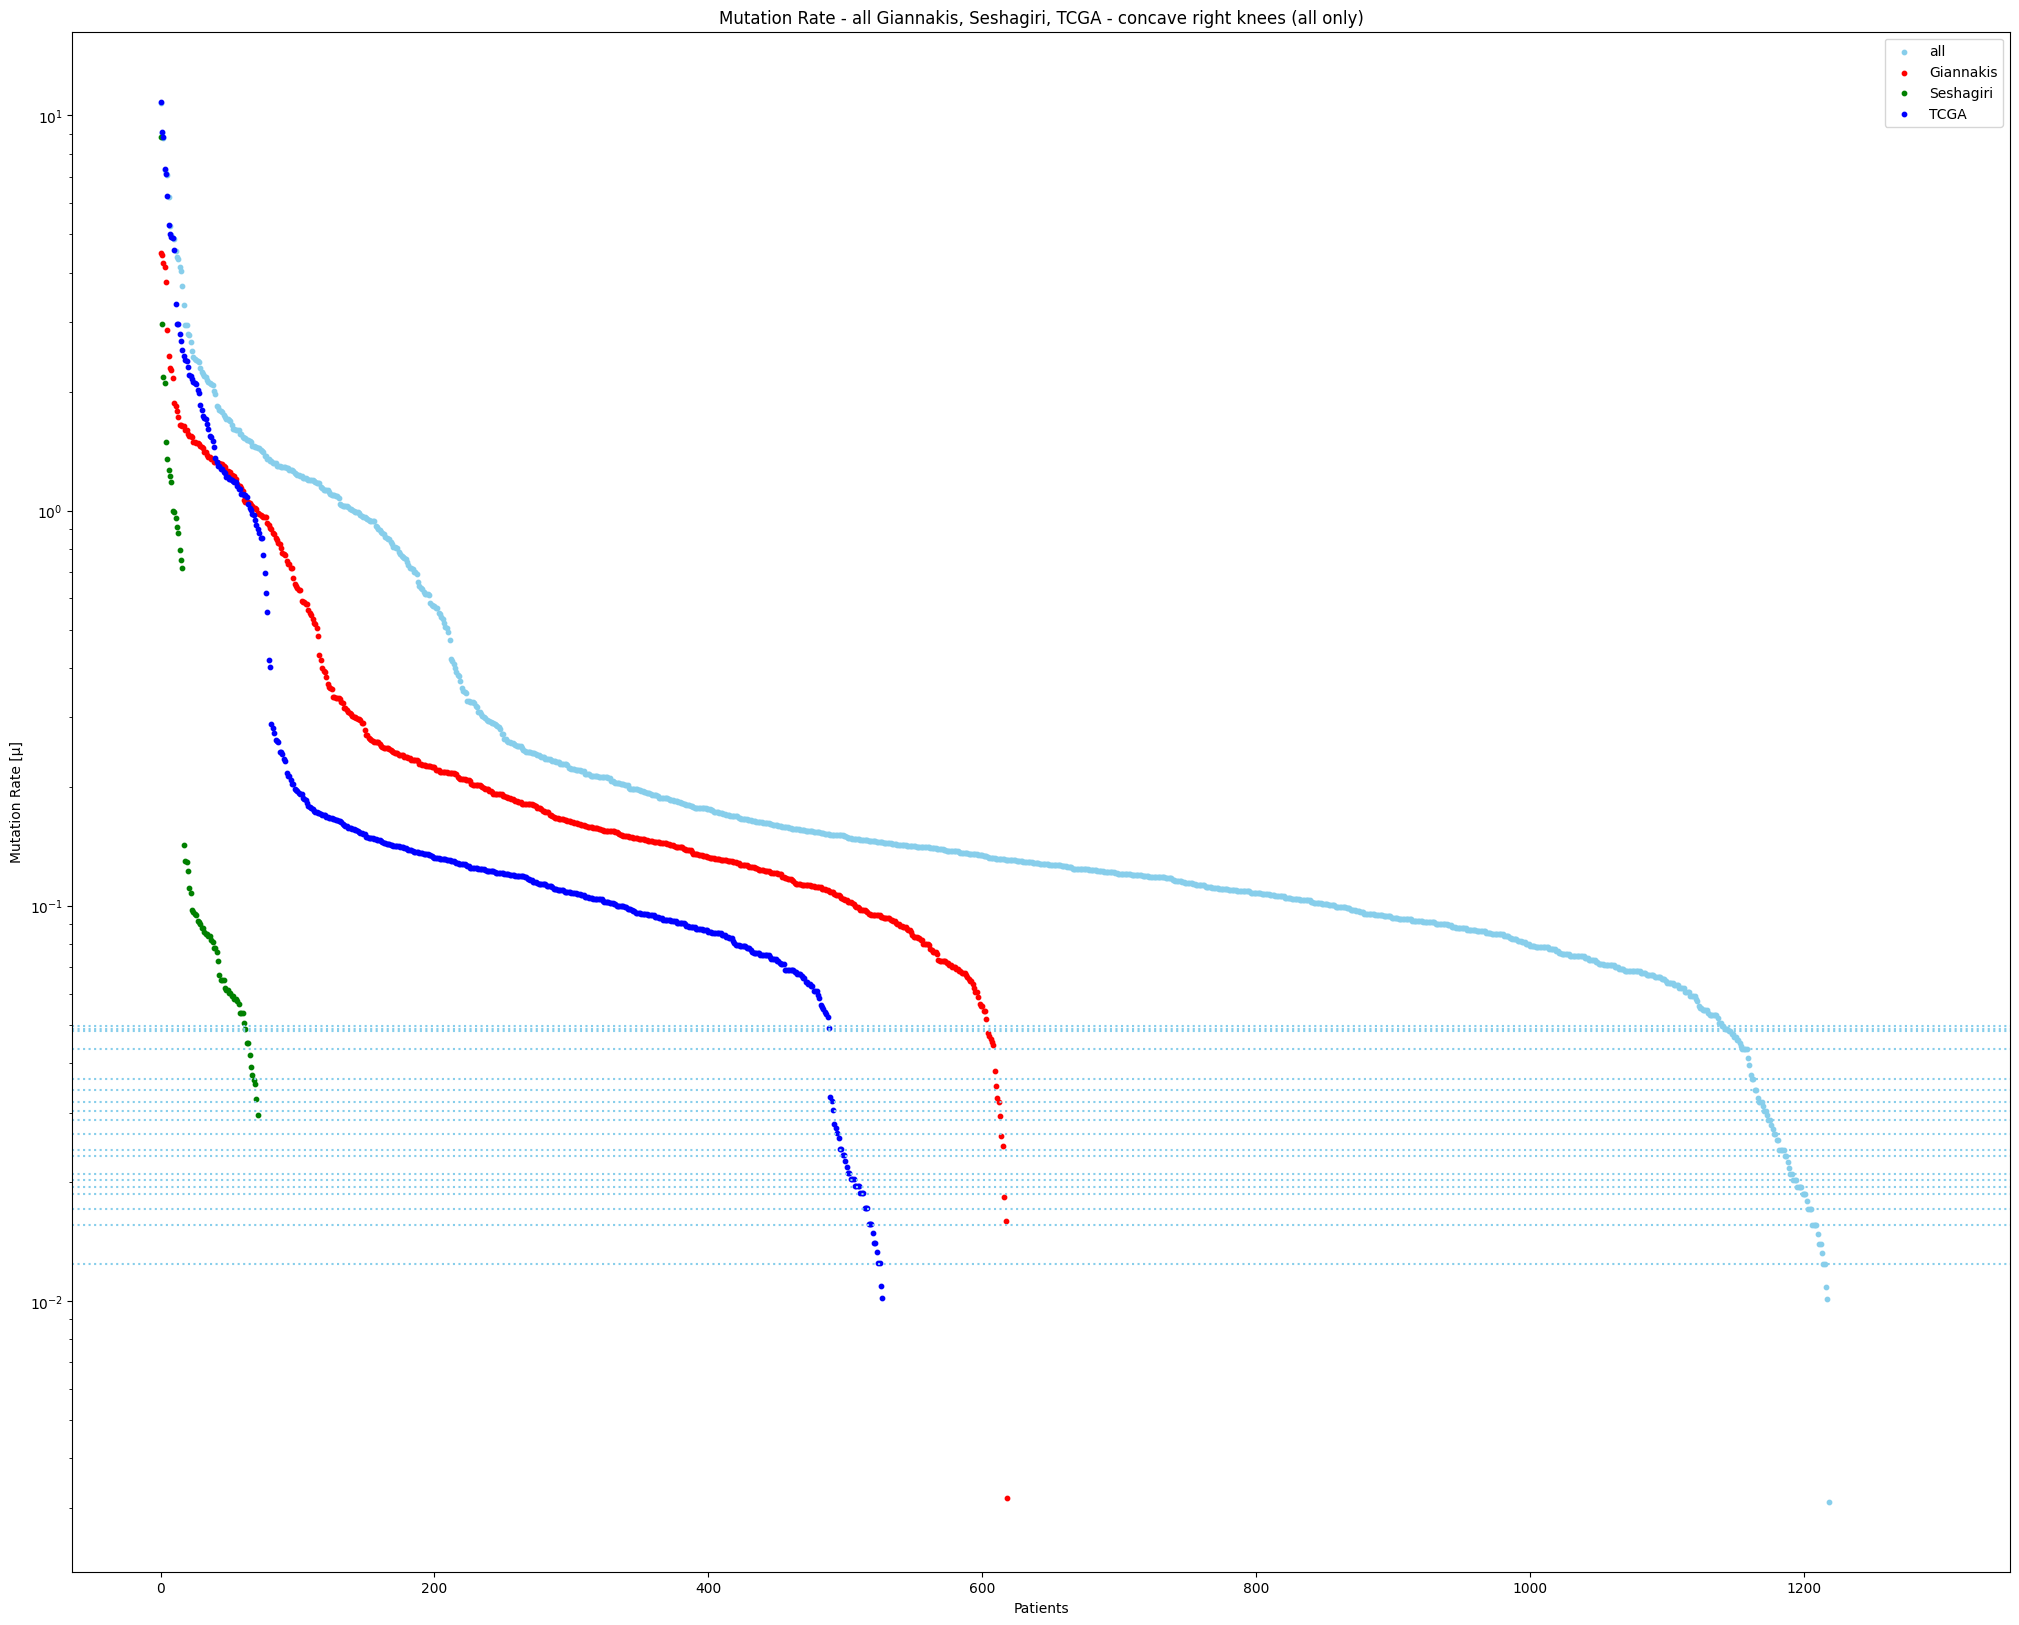

In [44]:
# plot mutation rate per patient
plt.figure(figsize=(25, 20))
plt.scatter(numMutatedBases_perPatient_all.index, numMutatedBases_perPatient_all['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.scatter(numMutatedBases_perPatient_Giannakis.index, numMutatedBases_perPatient_Giannakis['Mutation_Rate[µ]'], color='red', s=10)
plt.scatter(numMutatedBases_perPatient_Seshagiri.index, numMutatedBases_perPatient_Seshagiri['Mutation_Rate[µ]'], color='green', s=10)
plt.scatter(numMutatedBases_perPatient_TCGA.index, numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], color='blue', s=10)
for y in ys_all:
    plt.axhline(y=y, color='skyblue', linestyle=':')
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend(['all', 'Giannakis', 'Seshagiri', 'TCGA'])
plt.title('Mutation Rate - all Giannakis, Seshagiri, TCGA - concave right knees (all only)')
plt.savefig(data['hypoHyper_analysis'] + 'all_Giannakis_Seshagiri_TCGA_concaveRightKneesAllOnly')
plt.show()

## Chosen Thresholds

We manually choose conservative thresholds:

- hyper: 1.85
- hypo: 0.04

written in .ini

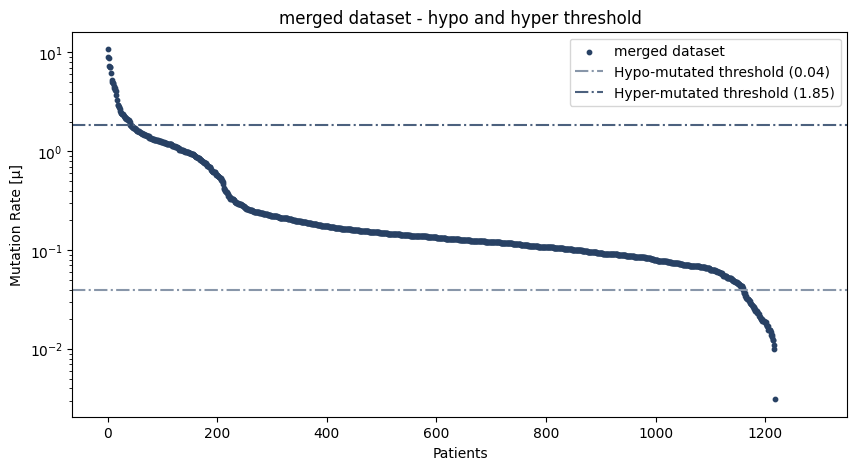

In [68]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Base colour and tinting function
blue_heritage = '#102C53'
tint = lambda color, p: mcolors.to_hex((p / 100) * np.array(mcolors.to_rgb(color)) + (1 - p / 100) * np.array([1, 1, 1]))

# Thresholds
hypo, hyper = 0.04, 1.85

# Plot mutation rate per patient
plt.figure(figsize=(10, 5))
plt.scatter(numMutatedBases_perPatient_all.index, 
            numMutatedBases_perPatient_all['Mutation_Rate[µ]'], 
            color=tint(blue_heritage, 90), s=10,
            label='merged dataset')

plt.axhline(y=hypo, color=tint(blue_heritage, 50), linestyle='-.', label='Hypo-mutated threshold (0.04)')
plt.axhline(y=hyper, color=tint(blue_heritage, 75), linestyle='-.', label='Hyper-mutated threshold (1.85)')

plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend()
plt.title('merged dataset - hypo and hyper threshold')
plt.savefig(data['hypoHyper_analysis'] + 'all - finalThresholds')
plt.show()


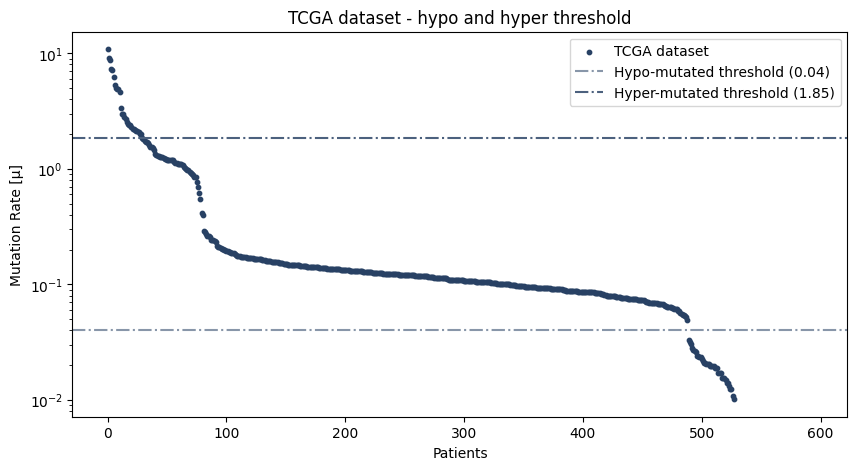

In [67]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Base colour and tinting function
blue_heritage = '#102C53'
tint = lambda color, p: mcolors.to_hex((p / 100) * np.array(mcolors.to_rgb(color)) + (1 - p / 100) * np.array([1, 1, 1]))

# Thresholds
hypo, hyper = 0.04, 1.85

# Plot mutation rate per patient
plt.figure(figsize=(10, 5))
plt.scatter(numMutatedBases_perPatient_TCGA.index, 
            numMutatedBases_perPatient_TCGA['Mutation_Rate[µ]'], 
            color=tint(blue_heritage, 90), s=10,
            label='TCGA dataset')

plt.axhline(y=hypo, color=tint(blue_heritage, 50), linestyle='-.', label='Hypo-mutated threshold (0.04)')
plt.axhline(y=hyper, color=tint(blue_heritage, 75), linestyle='-.', label='Hyper-mutated threshold (1.85)')

plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.legend()
plt.title('TCGA dataset - hypo and hyper threshold')
plt.savefig(data['hypoHyper_analysis'] + 'TCGA - finalThresholds')
plt.show()